#준비

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q koreanize-matplotlib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib
import json
import platform
import warnings
from pathlib import Path
from scipy import stats
from IPython.display import display

# 데이터

In [ ]:
# 한글 폰트 (Windows: 맑은 고딕, Mac: AppleGothic)
#plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "Noto Sans CJK KR")
#plt.rcParams["axes.unicode_minus"] = False

#DATA_PATH = "listings.csv"
OUT_PATH = "/content/drive/MyDrive/프로젝트/listings_clean.csv"

ROOM_TYPES = ["Entire home/apt", "Private room"]   # 호텔룸·다인실 제외
MIN_REVIEWS = 10                                    # 평점 신뢰도
MIN_AVAILABILITY = 1                                # 예약 가능일 1일 이상
MAX_QUOTE_NIGHTS = 6                               # 가격 견적 6박 이하 (장기 할인 가격 제외)
TRIM_Q = 0.01                                       # 가격 상·하위 1% 제외


# 이름에 운영 중단이 명시된 숙소 (직접 확인, 6개)
INACTIVE_IDS = [13254774, 16564598, 19557335, 20552841, 51397574, 635527106503833045]
CENTER = (51.5074, -0.1278)                         # 도심 기준점: Charing Cross 부근

# 1. 데이터 확인

In [ ]:

df = pd.read_csv("/content/drive/MyDrive/프로젝트/listings (1).csv")

print(df.shape)
df.head()

/tmp/ipykernel_5653/2123528322.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/drive/MyDrive/프로젝트/listings (1).csv")


(91954, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,...,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,11551,https://www.airbnb.com/rooms/11551,20260917015706,2026-09-19,NaN,Artistic London Pied-à-Terre,"Live like a local in this quintessential London flat, boasting a well-equipped kitchen for home-cooked feasts, vinta...",NaN,https://a0.muscache.com/pictures/prohost-api/Hosting-11551/original/ccbee37e-97b9-4580-bb06-e8319e54e4a0.jpeg,43039,https://www.airbnb.com/users/show/43039,1462507475108972681,https://www.airbnb.com/users/profile/1462507475108972681,Adriano,NaN,...,2026-09-04,4.55,4.61,4.57,4.78,4.84,4.54,4.49,NaN,NaN,1,1,0,0,0.98
1,13913,https://www.airbnb.com/rooms/13913,20260917015706,2026-09-19,NaN,Holiday London DB Room Let-on going,My bright double bedroom with a large window has a relaxed feeling! It comfortably fits one or two and is centrally ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-13913/original/d755aa6d-cebb-4464-80be-2722c921e8d5.jpeg,54730,https://www.airbnb.com/users/show/54730,1462507796255381667,https://www.airbnb.com/users/profile/1462507796255381667,Alina,NaN,...,2026-03-31,4.86,4.80,4.80,4.82,4.88,4.79,4.79,NaN,NaN,2,1,1,0,0.29
2,15400,https://www.airbnb.com/rooms/15400,20260917015706,2026-09-19,NaN,Bright Chelsea Apartment. Chelsea!,"Lots of windows and light. St Luke's Gardens are at the end of the block, and the river not too far the other way. ...",NaN,https://a0.muscache.com/pictures/428392/462d262a_original.jpg,60302,https://www.airbnb.com/users/show/60302,1462507970949884182,https://www.airbnb.com/users/profile/1462507970949884182,Philippa,NaN,...,2026-03-30,4.81,4.86,4.87,4.88,4.84,4.94,4.74,NaN,NaN,1,1,0,0,0.48
3,24328,https://www.airbnb.com/rooms/24328,20260917015706,2026-09-19,NaN,Battersea live/work artist house with car park,"Artist house by SW Battersea Park, bright high ceiling bedroom and separate studio/office, a shared communal garden ...",NaN,https://a0.muscache.com/pictures/9194b40f-c627-4b57-931a-0b8e1ba58eb7.jpg,41759,https://www.airbnb.com/users/show/41759,1462507453126203501,https://www.airbnb.com/users/profile/1462507453126203501,Joe,NaN,...,2026-07-02,4.90,4.89,4.91,4.90,4.93,4.60,4.66,NaN,NaN,1,1,0,0,0.50
4,25081,https://www.airbnb.com/rooms/25081,20260917015706,2026-09-21,previous scrape,Lovely bright flat for 1-4p 20 m to Covent Garden,"<b>The space</b><br />Big, charming flat in West/Central London all to yourself! Wooden floors, high ceilings and lo...",NaN,https://a0.muscache.com/pictures/hosting/Hosting-25081/original/bbb169ef-9578-42e2-967a-f3aa3805cdf3.jpeg,72242,https://www.airbnb.com/users/show/72242,1462508422108068678,https://www.airbnb.com/users/profile/1462508422108068678,Julie,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN


In [ ]:
print(f"행 수, 열 수: {df.shape}")
print("수집일:", df["last_scraped"].min(), "~", df["last_scraped"].max())
print("자치구 수:", df["neighbourhood_cleansed"].nunique())

행 수, 열 수: (91954, 90)
수집일: 2026-09-18 ~ 2026-09-23
자치구 수: 33


### **중복 확인:** `id` 기준 중복은 0건이다 (91,954행 = 고유 id 91,954개). 숙소 1개가 1행인 구조가 맞아, 중복 제거 없이 진행한다.

In [ ]:
# 중복 확인: 숙소 1개 = 1행인지
print("전체 행 수:", len(df))
print("고유 id 수:", df["id"].nunique())
print("중복 id 수:", df["id"].duplicated().sum())

전체 행 수: 91954
고유 id 수: 91954
중복 id 수: 0


## 2. 가격 정리

**문제:** `price`는 `"$1,234.00"` 같은 문자열이고, 숙소마다 다른 날짜·숙박 일수로 조회한 견적의 1박 가격이다.

**하는 일**
- `$`와 쉼표를 지워 숫자로 변환 → `price_gbp`
- 견적 원문(`price_quote_raw`)에서 실제 통화 확인
- 체크아웃 − 체크인으로 가격 조회 기간 계산 → `quote_nights`

**결과**
- 통화는 전부 GBP → `$` 기호와 달리 **실제 단위는 파운드(£)**
- 가격 결측 **34.9%** → 아래 2-1에서 원인 확인
- 중앙값 £175, 평균 £248, 최댓값 £75,000 → 비싼 쪽으로 치우친 분포, 비정상 존재 가능성

In [ ]:
# 변환 전 price 열 확인
print("자료형:", df["price"].dtype)
print("예시:", df["price"].dropna().head(5).tolist())


자료형: object
예시: ['$267.50', '$127.00', '$137.50', '$228.00', '$290.00']


In [ ]:
df["price_gbp"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)

currency = df["price_quote_raw"].dropna().str.extract(r'"currency": "(\w+)"')[0]
print("견적 통화:", currency.value_counts().to_dict())
print("자료형:", df["price_gbp"].dtype)

df["quote_nights"] = (pd.to_datetime(df["price_quote_checkout_date"])
                      - pd.to_datetime(df["price_quote_checkin_date"])).dt.days
print("\n전체 가격 결측 비율:", round(df["price_gbp"].isna().mean(), 3))
print(df["price_gbp"].describe().round(1))

견적 통화: {'GBP': 60028}
자료형: float64

전체 가격 결측 비율: 0.349
count    59905.0
mean       248.4
std        577.0
min         10.0
25%         99.7
50%        175.0
75%        279.8
max      75000.0
Name: price_gbp, dtype: float64


## 2-1 가격 결측은 무작위가 아니다

**확인한 것:** 가격이 없는 숙소가 어떤 숙소인지, 최근 1년 리뷰 유무로 나눠 가격 결측 비율을 비교했다.

**결과:**
- 리뷰 10개 이상 숙소의 26.7%가 가격이 없다.
- 최근 1년 리뷰가 없는 숙소는 70.5%, 있는 숙소는 14.3%가 가격이 없다.
- 최근 1년 리뷰가 없는 숙소는 마지막 리뷰가 중앙값 3.2년 전으로, 운영을 쉬고 있을 가능성이 높다.

**결론:** 가격 없는 숙소는 리뷰와 관계없이 **전부 제외**한다.
- 제외해도 현재 운영 중인 숙소 위주로 남으므로, "지금 받는 가격을 추정 시세와 비교하는 질문에 맞는 범위다.
- 가격은 분석 대상 자체라 다른 값으로 채우면 결과를 지어내는 셈이므로 채우지 않는다.

In [ ]:
r10 = df[df["number_of_reviews"] >= MIN_REVIEWS]
print("리뷰 10개 이상 숙소의 가격 결측 비율:", round(r10["price_gbp"].isna().mean(), 3))
print(r10.groupby(r10["number_of_reviews_ltm"] == 0)["price_gbp"]
         .apply(lambda s: s.isna().mean()).round(3)
         .rename({False: "최근 1년 리뷰 있음", True: "최근 1년 리뷰 없음"}))

no_recent = r10[r10["number_of_reviews_ltm"] == 0]
years_since = (pd.to_datetime(no_recent["last_scraped"])
               - pd.to_datetime(no_recent["last_review"])).dt.days / 365
print("최근 1년 리뷰 없는 숙소:", len(no_recent), "개")
print("마지막 리뷰 이후 경과 연수 중앙값:", round(years_since.median(), 1))

리뷰 10개 이상 숙소의 가격 결측 비율: 0.267
number_of_reviews_ltm
최근 1년 리뷰 있음    0.143
최근 1년 리뷰 없음    0.705
Name: price_gbp, dtype: float64
최근 1년 리뷰 없는 숙소: 8525 개
마지막 리뷰 이후 경과 연수 중앙값: 3.2


## 2-2 조회 기간에 따라 가격과 할인이 달라진다 (집 전체 / 개인실)

**하는 일**
- 조회 기간별 1박 가격 중앙값을 비교한다.
- 견적 원문의 할인 금액(`discount_amount`)이 0보다 큰지로 할인 적용 비율을 구한다.

**결론**
- 두 유형 모두 **7박에서 할인 적용 비율이 55% 안팎으로 급증**한다. 주간 할인(7박 이상)이 시작되는 지점으로 보인다.
- 할인된 가격이 섞이면 정상 가격 숙소가 "상대적 저가 숙소"로 잘못 분류될 수 있으므로, **조회 기간 6박 이하만 사용**한다.
- 개인실은 6박 이하에서도 조회 기간이 길수록 가격이 낮다(1박 £85 → 4~6박 £71).
- 이 구간은 할인 비율이 오히려 낮아(7.6~9.1%), 할인 때문이 아니다. 최소 숙박일이 긴 개인실이 원래 저렴한 방이기 때문으로 보인다.
- 가격 측정 문제가 아니라 숙소의 실제 차이이므로 빼지 않고, 조회 기간(`quote_nights`)을 모델 변수로 넘겨 반영한다.

In [ ]:
# 조회 기간별 1박 가격 중앙값 (집 전체 / 개인실)
pr = df[df["room_type"].isin(ROOM_TYPES) & df["price_gbp"].notna()]
print(pr.groupby(["room_type", pd.cut(pr["quote_nights"], [0, 1, 3, 6, 30, 400])], observed=True)["price_gbp"]
        .agg(["median", "size"]).round(1))

                              median   size
room_type       quote_nights               
Entire home/apt (0, 1]         224.0  10745
                (1, 3]         230.5  19184
                (3, 6]         247.0   5337
                (6, 30]        206.4   4477
                (30, 400]      152.7    778
Private room    (0, 1]          85.0  10610
                (1, 3]          80.0   5980
                (3, 6]          70.5   1153
                (6, 30]         58.6   1215
                (30, 400]       51.2    127


In [ ]:
# 할인 적용 비율 (집 전체 / 개인실)
def discount_amount(raw):
    if not isinstance(raw, str):
        return np.nan
    quote = json.loads(raw).get("quote") or {}
    d = quote.get("discount_amount")
    return float(d) if d not in (None, "") else 0.0

qr = df[df["room_type"].isin(ROOM_TYPES) & df["price_quote_raw"].notna()].copy()
qr["has_discount"] = qr["price_quote_raw"].map(discount_amount) > 0
print(qr.groupby(["room_type", qr["quote_nights"].clip(upper=10)])["has_discount"]
        .mean().round(3).unstack(0))

room_type     Entire home/apt  Private room
quote_nights                               
1.0                     0.263         0.164
2.0                     0.192         0.109
3.0                     0.176         0.108
4.0                     0.149         0.076
5.0                     0.140         0.091
6.0                     0.126         0.081
7.0                     0.550         0.548
8.0                     0.615         0.714
9.0                     0.529         0.538
10.0                    0.565         0.552


## 3. 필터링

각 단계에서 몇 개가 빠지는지 표로 남긴다.

### 판단 1. 이름에 운영 중단이 표시된 숙소 제외 (6개)

- 가격과 리뷰가 있어도 운영 중이 아닌 숙소가 있다. 숙소 이름에서 운영 중단을 뜻하는 표현을 검색한 뒤 직접 읽어 확인한 6개를 id로 제외했다 ("No Longer Available", "Not available until 2022", "let out full time" 등).
- 이름에 표시하지 않은 비활성 숙소는 여전히 남아 있을 수 있으며, 이는 한계로 기록한다.


### 판단 2. 가격 상·하위 1% 제외

- 극단적인 가격은 가격 예측 모델을 왜곡하므로, 다른 필터를 모두 적용한 **마지막**에 상·하위 1%를 제외한다. 순서를 바꾸면 자르는 기준값이 달라진다.
- **상위 1%:** 2인용 원룸 £10,000 등 실제 판매 가격이 아니라 예약을 막기 위해 설정한 것으로 보이는 가격이 포함되어 있다. 이는 "상대적 고가 숙소"가 아니라 사실상 판매 중지 상태이므로 제외한다.
- **하위 1%:** 대부분 외곽 지역의 1인용 개인실로, 실제로 싼 숙소로 보인다. 오류는 아니지만 가격 예측 모델이 같은 조건의 싼 가격을 학습하므로, 제외해도 결론에 미치는 영향은 작다고 판단한다.


### 판단 3. 예약 가능일 1일 이상

- `availability_365`가 0인 숙소는 닫힌 숙소일 수도 있지만 1년 내내 예약이 찬 숙소일 수도 있다. 제외되는 숫자가 작아(아래 표) 결과 영향은 작다고 판단한다.

### 판단 4. 숙소 유형은 집 전체·개인실만 사용 (409개 제외)

| 숙소 유형 | 숙소 수 | 비율 |
|---|---|---|
| 집 전체 | 61,074 | 66.4% |
| 개인실 | 30,471 | 33.1% |
| 호텔룸 | 207 | 0.2% |
| 다인실 | 202 | 0.2% |

- **표본이 너무 적다:** 호텔룸과 다인실은 합쳐서 0.4%뿐이다. 리뷰·가격 필터까지 거치면 더 줄어, 추정 시세를 안정적으로 계산하기 어렵다.
- **가격 구조가 다르다:** 호텔룸은 숙박업체가 운영하는 객실이고, 다인실은 방 하나를 여러 명이 나눠 쓰는 침대 단위 가격이다. 집 전체·개인실과 같은 기준으로 가격을 비교하기 어렵다.

### 판단 5. 누적 리뷰 10개 이상만 사용

- 가성비 점수는 손님 별점의 평균이라, 리뷰가 적으면 한두 명 의견에 크게 흔들린다.
- 리뷰 1~2개 숙소는 60.2%가 5.0 만점이고 점수 흔들림(표준편차)이 1.02다. 점수가 숙소의 가성비보다 우연히 만난 한두 명의 평가를 반영한다.
- 리뷰가 10~19개가 되면 만점 비율 7.4%, 흔들림 0.28로 크게 안정되고, 그 뒤로는 줄어드는 폭이 완만하다.


In [ ]:
steps = []
def log(name, d):
    steps.append({"단계": name, "숙소 수": len(d)})
    return d

s = log("전체", df)
s = log("집 전체·개인실", s[s["room_type"].isin(ROOM_TYPES)])
s = log(f"리뷰 {MIN_REVIEWS}개 이상", s[s["number_of_reviews"] >= MIN_REVIEWS])
s = log("가격 있음", s[s["price_gbp"].notna()])
s = log(f"예약 가능일 {MIN_AVAILABILITY}일 이상", s[s["availability_365"] >= MIN_AVAILABILITY])
s = log(f"조회 기간 {MAX_QUOTE_NIGHTS}박 이하", s[s["quote_nights"] <= MAX_QUOTE_NIGHTS])
s = log("운영 중단 표시 숙소 제외", s[~s["id"].isin(INACTIVE_IDS)])

lo, hi = s["price_gbp"].quantile([TRIM_Q, 1 - TRIM_Q])
s = log(f"가격 상·하위 {TRIM_Q:.0%} 제외 (£{lo:.0f}~£{hi:.0f})", s[s["price_gbp"].between(lo, hi)])

filter_table = pd.DataFrame(steps)
filter_table["제외"] = -filter_table["숙소 수"].diff().fillna(0).astype(int)
filter_table

,단계,숙소 수,제외
0,전체,91954,0
1,집 전체·개인실,91545,409
2,리뷰 10개 이상,38504,53041
3,가격 있음,28201,10303
4,예약 가능일 1일 이상,27923,278
5,조회 기간 6박 이하,26124,1799
6,운영 중단 표시 숙소 제외,26118,6
7,가격 상·하위 1% 제외 (£40~£958),25607,511


### *전체 숙소 유형별 수

In [ ]:
before_rooms = pd.DataFrame({
    "숙소 수": df["room_type"].value_counts(),
    "비율(%)": (df["room_type"].value_counts(normalize=True) * 100).round(1),
})
before_rooms

,숙소 수,비율(%)
room_type,,
Entire home/apt,61074,66.4
Private room,30471,33.1
Hotel room,207,0.2
Shared room,202,0.2


### *필터 후 숙소 유형별 수

**최종 분석 대상 구성:** 25,607개 중 집 전체 17,004개(66.4%), 개인실 8,603개(33.6%). 필터 전(66.4% / 33.1%)과 비율이 거의 같아, 필터가 특정 유형에 치우치지 않았다.

In [ ]:
# 최종 분석 대상의 숙소 유형 구성
final_rooms = pd.DataFrame({
    "숙소 수": s["room_type"].value_counts(),
    "비율(%)": (s["room_type"].value_counts(normalize=True) * 100).round(1),
})
final_rooms

,숙소 수,비율(%)
room_type,,
Entire home/apt,17004,66.4
Private room,8603,33.6


### *리뷰 수 구간 별 가성비 점수가 얼마나 흔들리는지



In [ ]:
# 리뷰 수 구간별 가성비 점수가 얼마나 흔들리는지 (가격 있는 집 전체·개인실)
rv = df[df["room_type"].isin(ROOM_TYPES) & df["price_gbp"].notna() & df["review_scores_value"].notna()]
bins = pd.cut(rv["number_of_reviews"], [0, 2, 4, 9, 19, 49, 100000],
              labels=["1~2", "3~4", "5~9", "10~19", "20~49", "50+"])
g = rv.groupby(bins, observed=True)["review_scores_value"]

stability = pd.DataFrame({
    "숙소 수": g.size(),
    "점수 흔들림(표준편차)": g.std().round(2),
    "5.0 만점 비율(%)": (g.apply(lambda x: (x == 5).mean()) * 100).round(1),
    "4점 미만 비율(%)": (g.apply(lambda x: (x < 4).mean()) * 100).round(1),
})
stability

,숙소 수,점수 흔들림(표준편차),5.0 만점 비율(%),4점 미만 비율(%)
number_of_reviews,,,,
1~2,7822,1.02,60.2,16.2
3~4,4518,0.58,38.1,12.4
5~9,6895,0.40,20.7,7.2
10~19,7616,0.28,7.4,2.5
20~49,10156,0.22,1.7,0.8
50+,10429,0.18,0.2,0.2


## 4. 피처 만들기

**목적:** 가격 예측 모델에 넣을 재료를 원본에서 숫자로 만든다.

**한 일**

| 새 열 | 만든 방법 | 이유 |
|---|---|---|
| `bath_n` | `bathrooms_text`("1.5 baths" 등)에서 숫자 추출, "Half-bath"는 0.5 | `bathrooms` 열이 전부 비어 있음 |
| `bath_shared` | 욕실 설명에 "shared"가 있으면 1 | 공용 욕실 숙소가 "상대적 저가 숙소"로 잘못 분류되는 것 방지 |
| `amenities_n` | 편의시설 목록(JSON 문자열)의 개수 | 목록 그대로는 모델에 넣을 수 없음 |
| `dist_center_km` | Charing Cross까지 거리 (하버사인 공식) | 자치구(33개)보다 세밀한 위치 차이 반영 |
| `log_price` | 가격의 로그 | 비싼 쪽으로 치우친 분포를 펴고, 비율(%) 차이로 해석 |

**결과** (25,607개 숙소)

| | 욕실 수 | 공용 욕실 | 편의시설 수 | 도심 거리 |
|---|---|---|---|---|
| 중앙값 | 1개 | 19% (평균) | 37개 | 5.7km |
| 범위 | 0~9개 | | 0~99개 | 0~28.8km |

- 욕실 수 18개는 숫자를 추출하지 못해 5절 결측치 처리에서 채운다.

- 가격은 숙소마다 다른 체크인 날짜로 조회되어 계절 요금 차이가 섞일 수 있다. 다만 분석 대상의 84.3%가 9~10월 기준으로 조회되어 영향은 작다고 판단했다. 성수기 날짜로 조회된 일부 숙소는 상대적 고가로 분류될 가능성이 있다 (**한계**).

#### *원본 열에서 피처 만들기

In [ ]:
s = s.copy()

# 욕실 수: "1.5 baths", "1 shared bath", "Half-bath" 등
bt = s["bathrooms_text"].fillna("").str.lower()
s["bath_n"] = bt.str.extract(r"([\d.]+)")[0].astype(float)
s.loc[s["bath_n"].isna() & bt.str.contains("half"), "bath_n"] = 0.5
s["bath_shared"] = bt.str.contains("shared").astype(int)

# 편의시설 개수: JSON 목록 문자열
s["amenities_n"] = s["amenities"].map(lambda x: len(json.loads(x)) if isinstance(x, str) else np.nan)

# 도심까지 거리(km): 하버사인 공식
def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, [lat, lon, lat0, lon0])
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
s["dist_center_km"] = haversine_km(s["latitude"], s["longitude"], *CENTER)

s["log_price"] = np.log(s["price_gbp"])

print(s[["bath_n", "bath_shared", "amenities_n", "dist_center_km"]].describe().round(2))

         bath_n  bath_shared  amenities_n  dist_center_km
count  25589.00     25607.00     25607.00        25607.00
mean       1.30         0.19        36.28            7.04
std        0.59         0.39        13.14            4.79
min        0.00         0.00         0.00            0.01
25%        1.00         0.00        27.00            3.63
50%        1.00         0.00        37.00            5.71
75%        1.50         0.00        45.00            9.53
max        9.00         1.00        99.00           28.77


#### *가격 조회 월별 숙소 수: 9~10월에 몰려 있다

In [ ]:
quote_m = pd.to_datetime(s["price_quote_checkin_date"]).dt.month

month_table = pd.DataFrame({
    "숙소 수": quote_m.value_counts().sort_index(),
    "비율(%)": (quote_m.value_counts(normalize=True).sort_index() * 100).round(1),
})
month_table.index.name = "조회 월"
print(f"9~10월 기준으로 조회된 숙소: {quote_m.isin([9, 10]).mean() * 100:.1f}%")
month_table

9~10월 기준으로 조회된 숙소: 84.3%


,숙소 수,비율(%)
조회 월,,
1,1075,4.2
2,221,0.9
3,178,0.7
4,103,0.4
5,112,0.4
6,103,0.4
7,73,0.3
8,61,0.2
9,15129,59.1


## 5. 결측 처리

- 모델 재료 13개 중 결측: 침대 수 481개(1.88%), 욕실 수 18개(0.07%), 침실 수 13개(0.05%)
- 같은 숙소 유형·수용 인원 숙소들의 중앙값으로 채웠다. 비율이 작고, 비슷한 숙소 기준이라 왜곡이 작다고 판단한다.
- 가격과 달리 이 값들은 모델의 재료일 뿐이라, 지우기보다 채워서 숙소를 남기는 편이 낫다.

In [ ]:
feature_cols = ["neighbourhood_cleansed", "room_type", "accommodates", "bedrooms", "beds",
                "bath_n", "bath_shared", "amenities_n", "dist_center_km",
                "latitude", "longitude", "quote_nights"]

missing = pd.DataFrame({
    "결측 수": s[feature_cols].isna().sum(),
    "결측 비율(%)": (s[feature_cols].isna().mean() * 100).round(2),
})
print("전체 숙소 수:", len(s))
missing[missing["결측 수"] > 0].sort_values("결측 수", ascending=False)

전체 숙소 수: 25607


,결측 수,결측 비율(%)
beds,481,1.88
bath_n,18,0.07
bedrooms,13,0.05


In [ ]:
# 침대·욕실 결측은 같은 숙소 유형·수용 인원의 중앙값으로 채운다
for col in ["beds", "bath_n", "bedrooms"]:
    n_missing = s[col].isna().sum()
    s[col] = s[col].fillna(s.groupby(["room_type", "accommodates"])[col].transform("median"))
    s[col] = s[col].fillna(s[col].median())
    print(f"{col}: {n_missing}개 채움")

beds: 481개 채움
bath_n: 18개 채움
bedrooms: 13개 채움


## 6. 결과 변수 점검

**목적:** 핵심 비교값인 1년 추정 수익(`estimated_revenue_l365d`)과 확인용 지표(`number_of_reviews_ltm`, `estimated_occupancy_l365d`)가 어떤 값인지 직접 확인한다. 문제 정의의 용어 정의와 한계의 근거가 된다.

### 판단

**1. 세 변수는 리뷰 수 하나에서 이어진 값이다**
- 실제 예약 기록이 없어, Inside Airbnb는 리뷰 수에 "리뷰를 쓰는 손님 비율"과 "평균 숙박 일수" 가정을 적용해 예약일을 추정한다. 이 데이터에서는 추정 예약일이 리뷰 수의 약 9배다.
- 추정 수익은 그 추정 예약일 × 1박 가격이다. 그래서 리뷰가 0개면 예약일도, 수익도 0이 되어 0인 숙소 비율이 셋 다 7.8%로 같다.
- → 핵심 비교는 **추정 수익**으로 하고, 리뷰 수로 같은 방향인지 확인한다. 리뷰 수는 가격이 들어가지 않은 값이라 "예약이 적은가"를 따로 볼 수 있다.

**2. 추정 예약일은 255일에서 잘린다**
- 1년(365일)이 아니라 255일이 최댓값이고, 5곳 중 1곳(20.7%)이 이 값에 묶여 있다.
- → 인기가 아주 많은 숙소끼리는 예약일과 추정 수익의 차이가 줄어 보인다 (**한계**).
- → 특히 상대적 저가 숙소는 예약이 많아 255일에 묶이기 쉬워, 실제보다 추정 수익이 낮게 기록될 수 있다. 가설 1-2("저가 숙소는 수익이 낮다")가 이 상한 때문에 맞는 것처럼 보일 수 있으므로, 255일에 묶인 숙소 비율을 집단별로 함께 확인한다 (**한계**).

**3. 추정 수익에는 가격이 곱해져 있다**
- 추정 수익 = 추정 예약일 × 1박 가격이다.
- → 상대적 고가 숙소는 가격이 높은 만큼 수익이 높게 나오기 쉽다. 그런데도 시세 수준 숙소보다 수익이 낮다면, **예약일이 가격 차이보다 훨씬 적다**는 뜻이다 (가설 1-1).
- → 상대적 저가 숙소는 반대로 가격이 낮아 수익이 낮게 나오기 쉽다. 예약일이 많아도 그 차이를 메우지 못하는지 확인한다 (가설 1-2).
- 해석할 때 리뷰 수(예약 쪽)도 함께 본다.

**4. 모두 추정치다**
- 세 변수 모두 실제 예약·정산 기록이 아니다. 발표에서는 "리뷰 수로 추정한 값"임을 밝힌다.
- 수익 차이는 가격 검토 필요성의 참고 정보이며, 가격을 바꾸면 그만큼 회복된다는 뜻이 아니다.

#### (1) 분포와 0인 숙소 비율

In [ ]:
out_cols = ["estimated_revenue_l365d", "estimated_occupancy_l365d", "number_of_reviews_ltm"]

check = s[out_cols].describe().T.round(1)
check["0인 숙소(%)"] = [round((s[c] == 0).mean() * 100, 1) for c in out_cols]
check.index = ["추정 수익 (£)", "추정 예약일 (일)", "최근 12개월 리뷰 수"]
check

,count,mean,std,min,25%,50%,75%,max,0인 숙소(%)
추정 수익 (£),25607.0,25030.2,26899.4,0.0,6773.5,17056.0,33810.0,238170.0,7.8
추정 예약일 (일),25607.0,127.0,90.0,0.0,46.0,110.0,221.0,255.0,7.8
최근 12개월 리뷰 수,25607.0,17.6,19.0,0.0,5.0,12.0,24.0,789.0,7.8


#### (2) 추정 수익 = 가격 × 추정 예약일인지 확인

In [ ]:
occ = s["estimated_occupancy_l365d"]
calc = s["price_gbp"] * occ
diff = (s["estimated_revenue_l365d"] - calc).abs()

print(f"직접 계산과의 최대 차이: £{diff.max():.2f}")
print(f"£1 미만으로 일치하는 숙소: {(diff < 1).mean() * 100:.1f}%")

직접 계산과의 최대 차이: £0.50
£1 미만으로 일치하는 숙소: 100.0%


#### (3) 추정 예약일은 리뷰 수의 몇 배인가
리뷰 0개(나눌 수 없음)와 255일 상한 숙소(잘린 값)는 빼고 계산한다.

In [ ]:
m = (s["number_of_reviews_ltm"] > 0) & (occ < occ.max())
ratio = occ[m] / s.loc[m, "number_of_reviews_ltm"]

print(f"계산 대상 숙소: {m.sum():,}개")
print(f"추정 예약일 ÷ 리뷰 수 (중앙값): {ratio.median():.1f}배")

example = (s[m].groupby("number_of_reviews_ltm")["estimated_occupancy_l365d"]
              .median().head(6).astype(int).rename("추정 예약일 (일)"))
example.index.name = "최근 12개월 리뷰 수"
example.to_frame()

계산 대상 숙소: 18,301개
추정 예약일 ÷ 리뷰 수 (중앙값): 9.2배


,추정 예약일 (일)
최근 12개월 리뷰 수,
1,9
2,18
3,28
4,37
5,46
6,55


## 7. EDA

### 1. 가격은 저가에 몰리고 고가로 길게 늘어진다
- 1박 가격 중앙값 £169, 평균 £205 → 비싼 숙소가 평균을 끌어올린다.
- 치우침 정도(왜도): 원래 가격 1.68 → 로그 가격 0.05로 거의 대칭이 된다.
- **판단:** 가격 예측 모델은 로그 가격(`log_price`)으로 학습한다.

### 2. 자치구에 따라 가격이 최대 3배 차이 난다
- 가장 싼 곳: Sutton £80, Hillingdon £84, Bexley £85
- 가장 비싼 곳: Westminster £256, Kensington and Chelsea £253, City of London £250
- **판단:** 위치를 빼면 도심 숙소는 상대적 고가 숙소, 외곽 숙소는 상대적 저가 숙소로 잘못 분류된다. 자치구와 도심 거리를 추정 시세의 핵심 기준으로 넣는다.

### 3. 가성비 점수는 4.5점 이상에 몰려 있다
- 4.5점 이상 81.1%, 평균 4.67, 중앙값 4.71, 표준편차 0.23
- **판단:** 정규분포가 아니므로 집단 비교에는 비모수 검정(Kruskal-Wallis)을 쓴다. 점수 차이는 원래 작을 수밖에 없어, p-value보다 효과 크기로 의미를 판단한다.

### 4. 추정 예약일은 255일에서 잘려 있다
- 최근 1년 추정 예약일은 중앙값 110일, 평균 127일이다.
- 그래프 오른쪽 끝 255일에 막대가 크게 솟아 있다. 1년(365일)이 아니라 255일이 최댓값이고, 5,313개(20.7%)가 이 값에 몰려 있다.
- 추정 예약일은 실제 예약 기록이 아니라 리뷰 수의 약 9배로 짐작한 값이고, Inside Airbnb가 255일(1년의 약 70%)에서 상한을 둔 것으로 보인다.
- **판단:** 인기가 아주 많은 숙소는 실제 예약일과 관계없이 모두 255일로 기록되어, 이 숙소들끼리는 수요 차이를 구분할 수 없다. 추정 수익 비교 결과를 해석할 때 이 한계를 함께 밝힌다.

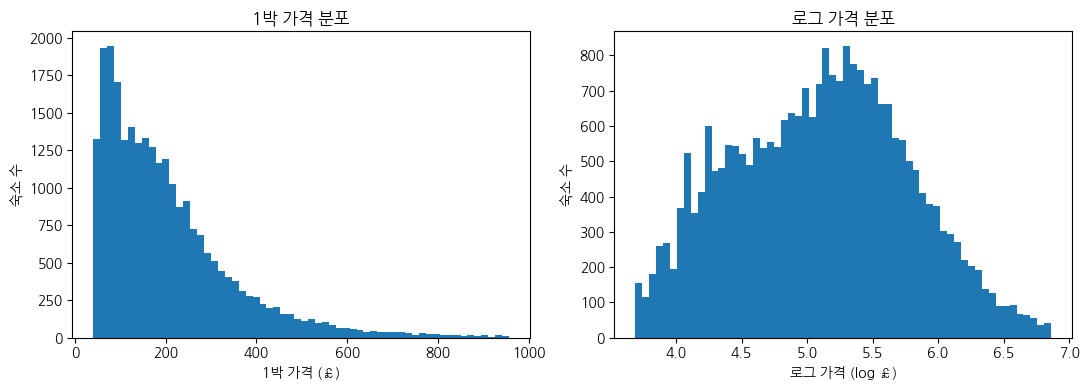

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(s["price_gbp"], bins=60)
axes[0].set_title("1박 가격 분포")
axes[0].set_xlabel("1박 가격 (£)")
axes[0].set_ylabel("숙소 수")

axes[1].hist(s["log_price"], bins=60)
axes[1].set_title("로그 가격 분포")
axes[1].set_xlabel("로그 가격 (log £)")
axes[1].set_ylabel("숙소 수")

plt.tight_layout(); plt.show()

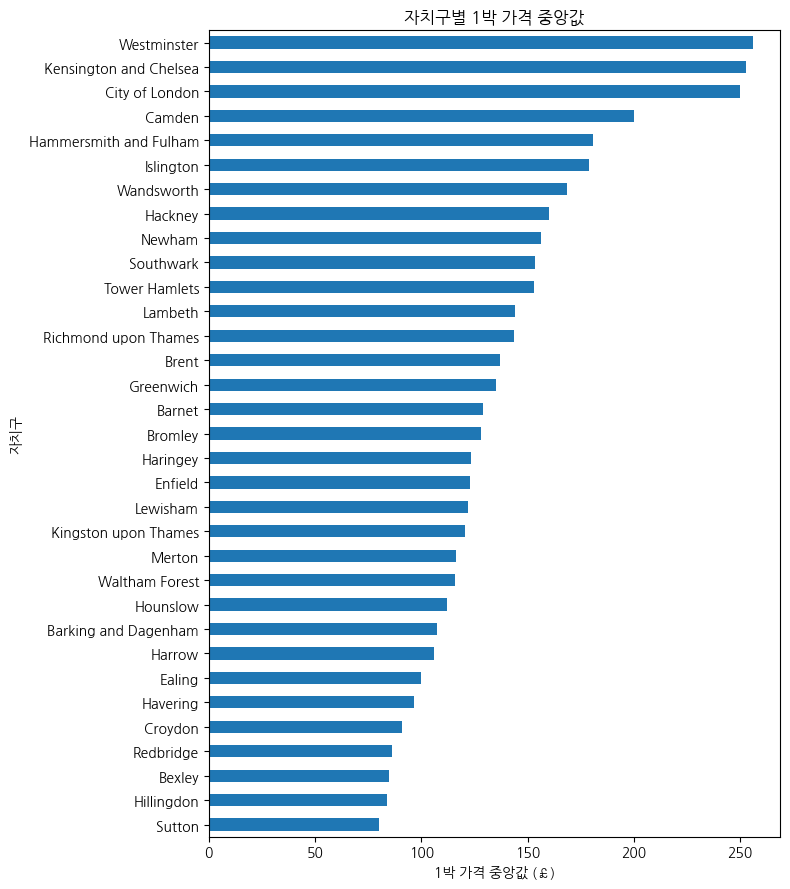

In [ ]:
borough = s.groupby("neighbourhood_cleansed")["price_gbp"].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
borough.plot.barh(ax=ax)
ax.set_title("자치구별 1박 가격 중앙값")
ax.set_xlabel("1박 가격 중앙값 (£)")
ax.set_ylabel("자치구")

plt.tight_layout(); plt.show()

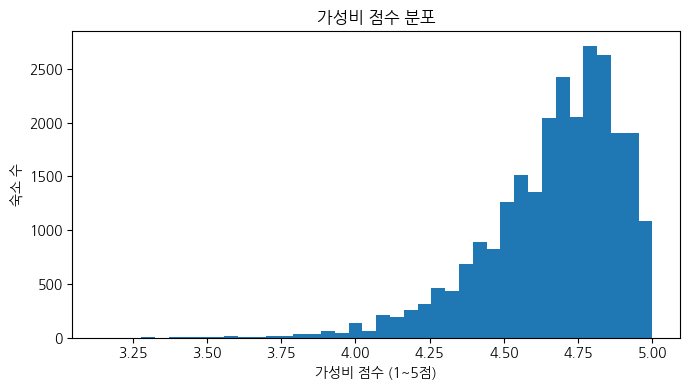

4.5점 이상 비율: 0.811
count    25607.00
mean         4.67
std          0.23
min          3.14
25%          4.55
50%          4.71
75%          4.83
max          5.00
Name: review_scores_value, dtype: float64


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(s["review_scores_value"], bins=40)
ax.set_title("가성비 점수 분포")
ax.set_xlabel("가성비 점수 (1~5점)")
ax.set_ylabel("숙소 수")
plt.tight_layout(); plt.show()

print("4.5점 이상 비율:", round((s["review_scores_value"] >= 4.5).mean(), 3))
print(s["review_scores_value"].describe().round(2))

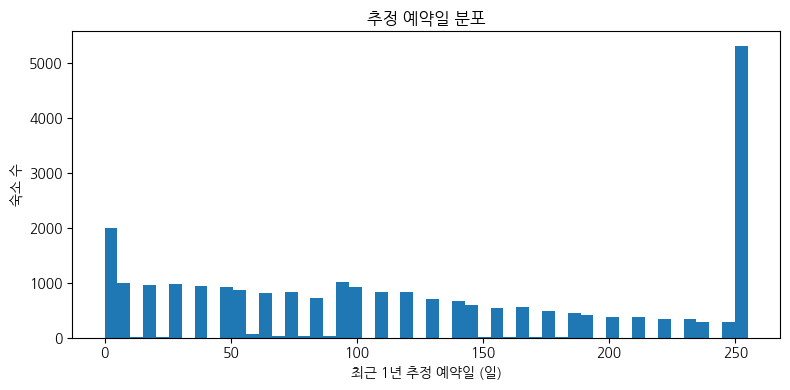

중앙값: 110일
평균: 127일
최댓값: 255일
최댓값인 숙소: 5,313개 (20.7%)


In [ ]:
occ = s["estimated_occupancy_l365d"]
at_max = occ == occ.max()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(occ, bins=50)
ax.set_title("추정 예약일 분포")
ax.set_xlabel("최근 1년 추정 예약일 (일)")
ax.set_ylabel("숙소 수")
plt.tight_layout(); plt.show()

print(f"중앙값: {occ.median():.0f}일")
print(f"평균: {occ.mean():.0f}일")
print(f"최댓값: {occ.max()}일")
print(f"최댓값인 숙소: {at_max.sum():,}개 ({at_max.mean() * 100:.1f}%)")

## 8. 저장

모델 담당과 검증 담당이 헷갈리지 않도록 **열을 용도별로 나눠** 저장한다.

- `FEATURES`: 가격 예측 모델에 넣는 변수
- `OUTCOMES`: 모델에 넣으면 안 되는 결과 변수 (가성비 점수, 리뷰 수 등)
- 평점, 리뷰 수, 슈퍼호스트 여부는 모델 피처에서 뺀다 (결과 변수를 원인에 넣는 셈이라서)

In [ ]:
ID = ["id"]
TARGET = ["price_gbp", "log_price"]
FEATURES = feature_cols
OUTCOMES = ["review_scores_value", "review_scores_rating", "number_of_reviews_ltm",
            "number_of_reviews", "estimated_occupancy_l365d", "estimated_revenue_l365d",
            "availability_365", "host_is_superhost", "first_review"]

out = s[ID + TARGET + FEATURES + OUTCOMES]
out.to_csv(OUT_PATH, index=False)
print(out.shape, "→", OUT_PATH)
print("결측 남은 열:", out[FEATURES].isna().sum()[lambda x: x > 0].to_dict())

(25607, 24) → /content/drive/MyDrive/프로젝트/listings_clean.csv
결측 남은 열: {}


# 에어비앤비 런던 추정 시세 모델링
데이터: Inside Airbnb London (2026-09-17 수집) · 분석 대상: 전처리를 마친 25,607곳

## 1. 분석 질문

**핵심 질문**

> 같은 조건 시세와의 가격 편차가 크고, 1년 추정 수익이 시세 수준 숙소보다 낮은 숙소는 어떤 숙소인가?

- **가격 편차** = (실제 가격 − 추정 시세) ÷ 추정 시세. 편차의 기준은 **같은 조건 숙소의 추정 시세**다. 0이면 시세와 같고, +0.3이면 시세보다 30% 비싸다.
- **가격 편차가 크다**의 기준선은 숙소들의 편차가 실제로 어떻게 퍼져 있는지 보고 정한다. 기준선을 넘어 높은 쪽이면 상대적 고가, 낮은 쪽이면 상대적 저가다.
- **수익이 낮다** = 수익 비율(내 수익 ÷ 같은 묶음 시세 수준 숙소의 수익 중앙값) 1 미만.

**가설**

| 가설 | 내용 | 확인 |
| --- | --- | --- |
| 가설 1-1 | 같은 조건의 추정 시세보다 높은 쪽으로 가격 편차가 큰 숙소는, 높은 숙박 단가에도 불구하고 같은 조건에서 시세 수준의 가격을 책정한 숙소보다 1년 추정 수익이 낮을 것이다. | Step 7 |
| 가설 1-2 | 같은 조건의 추정 시세보다 낮은 쪽으로 가격 편차가 큰 숙소는, 많은 예약일에도 불구하고 같은 조건에서 시세 수준의 가격을 책정한 숙소보다 1년 추정 수익이 낮을 것이다. | Step 7 |

**보조 질문**: 같은 조건 시세와의 가격 편차는 게스트의 가성비 평가와 연결되는가? (Step 9)
- 보조 가설: 시세보다 높은 쪽으로 가격 편차가 클수록 가성비 점수가 낮다.

## 2. 용어

| 용어 | 뜻 |
| --- | --- |
| 추정 시세 | 같은 조건(위치·크기·유형·편의시설) 숙소 가격을 모델로 예측한 값. 그 숙소를 학습에 쓰지 않은 5겹 교차 검증 예측. 로그 가격을 예측해 되돌린 값이라 같은 조건 가격의 중앙값에 가깝다 |
| 가격 편차 (이하 편차) | (실제 가격 − 추정 시세) ÷ 추정 시세 |
| 편차 기준선 | 상대적 고가 / 시세 수준 / 상대적 저가를 나누는 선. Step 6-2에서 편차 분포를 보고 정한다 |
| 상대적 고가 / 시세 수준 / 상대적 저가 | 편차가 +기준선 이상 / 그 사이 / −기준선 이하 |
| 같은 조건 묶음 | 자치구 × 숙소 유형 × 수용 인원. 시세 수준 숙소가 10곳 이상 묶음만 비교 |
| 수익 비율 | 숙소의 1년 추정 수익 ÷ 같은 묶음 시세 수준 숙소의 수익 중앙값 (1 = 같음) |
| 1년 추정 수익 | 1박 가격 × 지난 1년 추정 예약일. 노트북에서 직접 계산한다(Step 6) |

- 모델 조건 12개에는 가격 조회 조건인 조회 박 수(`quote_nights`)도 들어 있다.
- 같은 묶음 시세 수준 숙소의 수익 중앙값이 0인 묶음은 수익 비율을 계산할 수 없으므로 비교에서 뺀다(7-1).

## 3. 판정 기준

가설은 같은 조건 묶음 안에서만 비교하는 **층화 Mann-Whitney 검정**으로 판정한다. 숙소가 2만 곳이 넘으면 아주 작은 차이도 p-value가 작게 나온다. 그래서 차이의 크기인 **효과 크기 r**(0.1 작음, 0.3 중간, 0.5 큼)을 함께 본다.

| 판정 | 조건 |
| --- | --- |
| 채택 | 방향이 가설과 같고, p < 0.05, \|r\| ≥ 0.1 |
| 부분 채택 | 방향이 가설과 같고, p < 0.05지만 \|r\| < 0.1 (방향은 맞지만 차이가 작음) |
| 기각 | 방향이 반대이거나 p ≥ 0.05 |

- 보조 질문은 편차와 가성비 점수의 Spearman 순위 상관 ρ에 같은 기준을 쓴다(\|ρ\| ≥ 0.1).
- 가설 1-2의 '많은 예약일'은 예약일 비교로 따로 확인한다.

## 4. 전처리 결과를 반영한 모델링 계획
전처리 노트북이 넘겨준 파일 `listings_clean.csv`(25,607곳)와 전처리에서 확인한 사실을 보고 모델링 계획을 세웠다.

| 전처리 결과 | 확인된 사실 | 모델링 계획 |
| --- | --- | --- |
| 필터링 | 91,954곳 → 25,607곳 (집 전체·개인실, 리뷰 10개 이상, 예약 가능일 1일 이상, 가격 조회 6박 이하, 가격 상·하위 1% 제외) | 25,607곳 전체로 **하나의 전역 모델**을 만든다 |
| 조회 기간 | 7박부터 할인 적용 비율이 55% 안팎으로 급증 → 6박 이하 견적만 남김 | 남은 가격은 장기 할인이 거의 없는 1박 가격이므로 그대로 타깃으로 쓴다 |
| 조회 기간 (계속) | 6박 이하에서도 개인실은 조회 기간이 길수록 1박 가격이 낮음(85파운드 → 71파운드). 최소 숙박일이 긴 방이 원래 싼 방이라 판단, 조회 기간을 모델 변수로 넘김
| 피처 | 피처 12개 (위치 4, 유형 1, 규모 4, 시설 2, 가격 조회 조건 1) | 12개를 모두 모델 피처로 쓴다 |
| 결측 처리 | 침대 481·욕실 18·침실 13건을 숙소 유형 × 수용 인원 중앙값으로 채움 → 결측 0건 | 다시 채우지 않고 0건인지만 확인한다 |
| 결과 변수 | 평점·리뷰·예약일·예약 가능일·슈퍼호스트·첫 리뷰는 모두 예약 뒤에 생기는 값. 추정 예약일은 255일 상한(20.7%) | 피처에서 뺀다(누수). 1년 추정 수익은 1박 가격 × 추정 예약일로 계산해 같은 묶음 시세 수준 숙소와 **수익 비율**로 비교한다. 255일 상한이 결론을 바꾸는지 따로 점검한다 |
| 탐색 | 1박 가격 왜도 1.68 → 로그 후 0.05. 자치구별 중앙값 80파운드(Sutton) ~ 256파운드(Westminster). 가성비 점수 4.5점 이상 81.1% | 타깃은 `log_price`. 위치 피처는 필수. 가성비 점수는 차이가 작게 나올 수 있는 지표로 보조 질문에 쓴다 |

## 5. 모델 선택 원칙
| 모델 | 현장에서 설명하는 방법 | 역할 |
| --- | --- | --- |
| Ridge 회귀 | "침실이 1개 늘면 가격이 몇 % 오른다"를 계수로 바로 말한다 | 기준선: 가장 단순한 모델로 어디까지 되는지 |
| 결정트리 | "개인실인가? 침실이 2개 이상인가? 도심 5km 안인가?" 같은 질문 규칙으로 가격을 나눈다 | 가격을 가르는 규칙과 조건의 조합 효과 확인 |
| 랜덤포레스트 | 결정트리 200개가 각각 고른 '비슷한 숙소'들의 가격 평균 | 조건이 비슷한 숙소들의 가격 평균으로 추정 시세를 만들 수 있는지 확인 |

| 랜덤포레스트 설정 | 값 |
| --- | --- |
| 트리 수 (`n_estimators`) | 200 |
| 마지막 묶음 최소 숙소 수 (`min_samples_leaf`) | 2 |
| 나머지 | scikit-learn 기본값 |

**모델은 전역, 분석은 유형별**: 숙소 유형별로 모델을 따로 만들면 학습 데이터가 쪼개진다(예: 수용 인원 3명 이상 개인실은 1,243곳). 그래서 모델은 25,607곳 전체로 하나만 만들고, 결과를 유형별로 나눠 해석한다(6-3, 7-3).

**평가 방법**: 모든 모델은 같은 5겹 교차검증으로 비교한다. 숙소를 5묶음으로 나눠 각 묶음을 나머지 4묶음으로 학습한 모델이 예측하게 하면, 모든 숙소가 **자기 가격을 보지 않은 예측**(OOF, Out-of-Fold)을 하나씩 받는다. 이 예측이 곧 추정 시세의 재료다.

| 지표 | 뜻 | 좋은 방향 |
| --- | --- | --- |
| R² | 로그 가격 차이 중 모델이 설명하는 비율 | 높을수록 |
| MAE (파운드) | 예측이 실제와 평균 몇 파운드 다른가 | 낮을수록 |
| MAPE % | 평균 오차율 (크게 틀린 숙소에 끌림) | 낮을수록 |
| MedAPE % | 보통 숙소의 오차율 (중앙값) | 낮을수록 |

## 6. 분석 순서
| Step | 질문 | 방법 |
| --- | --- | --- |
| 0 | 다시 실행해도 같은 결과가 나오는가 | 시드·경로·상수 고정, 실행 환경 확인 |
| 1 | 전처리 결과가 맞는가, 결과 변수가 섞이지 않았는가 | 전처리 결과 확인, 누수 검사, 피처 12개로 X·y 정의 |
| 2 | 가장 단순한 모델은 어디까지 맞히는가 | Ridge 회귀 |
| 3 | 가격을 가르는 규칙은 무엇인가 | 결정트리 |
| 4 | 추정 시세로 쓸 모델은 무엇인가 | 랜덤포레스트, 세 모델 비교 |
| 5 | 모델은 무엇을 보고 가격을 정하는가 | 순열 중요도 |
| 6 | 숙소마다 추정 시세와 편차는 얼마이고, 기준선은 어디인가 | `oof_pred_final` = 추정 시세, 편차 분포, 기준선, 유형별 비교 |
| 7 | 가설 1-1·1-2: 시세를 벗어난 숙소는 수익이 낮은가 | 같은 조건 묶음 안 비교, 수익 비율, 층화 Mann-Whitney, 유형별, 판정 |
| 8 | 핵심 질문: 가격 편차가 크고 1년 추정 수익이 시세 수준 숙소보다 낮은 숙소는 어떤 숙소인가 | 수익 비율 1 미만 현황, 같은 가격 집단 안 '수익 낮음 vs 같거나 높음' 특징 비교 |
| 9 | 보조 질문: 가격 편차는 가성비 평가와 연결되는가 | 가성비 점수 집단 비교, Spearman 순위 상관 (전체·같은 묶음 안) |
| 10 | 결론은 튼튼한가 | 평점·슈퍼호스트 통제, 255일 상한 점검, 기준선·모델 변경, 비교 묶음 기준 변경 |
| 11 | 덜 번 금액은 얼마이고, 결과는 어디에 저장되는가 | 같은 묶음 시세 수준 숙소 대비 덜 번 금액, 결과 파일, 재현 확인 |
| 마지막 | 최종 모델링 결과 분석과 제언 | |


---
## Step 0. 환경 준비
**왜 하는가**: 시드·겹 수·경로·상수를 맨 앞에서 고정해, 누가 다시 실행해도 같은 숫자가 나오게 한다.

In [ ]:
# [Step 0] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 0-1. 라이브러리
# ====================================================================================================
# [0-1] 분석·모델·평가 도구 불러오기

import logging
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import stats
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

# ====================================================================================================
# 0-2. 폰트, 시드, 색
# ====================================================================================================
# [0-2] 한글 폰트, 시드 42, 그래프 배경, 집단 색 고정

try:
    import koreanize_matplotlib                       # Colab에서 없으면: !pip install -q koreanize-matplotlib
except ImportError:
    pass
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 컴퓨터에 없는 폰트 이름 경고 숨김
for k in ["figure.facecolor", "axes.facecolor", "savefig.facecolor"]:
    plt.rcParams[k] = "white"                         # VS Code 어두운 테마에서도 글자가 보이게
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
N_SPLITS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

COLORS = {"상대적 저가": "#2E7D32", "시세 수준": "#9AA8AE", "상대적 고가": "#B23A26"}
MODEL_COLORS = {"Ridge": "#7B8A92", "DecisionTree": "#55626C", "RandomForest": "#1F6F7A"}
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | sklearn {sklearn.__version__}")
REF_SKLEARN = "1.6.1"                                 # 이 노트북의 해설 숫자를 만든 scikit-learn 버전
if sklearn.__version__ != REF_SKLEARN:
    print(f"주의: 해설 숫자는 scikit-learn {REF_SKLEARN} 실행 결과입니다. 지금 버전({sklearn.__version__})에서는 끝자리가 달라질 수 있습니다.")

# ====================================================================================================
# 0-3. 데이터 경로
# ====================================================================================================
# [0-3] data/ 폴더를 먼저, 없으면 구글 드라이브 '프로젝트' 폴더에서 파일 찾기

LOCAL_DIR = Path("data")
DRIVE_DIR = Path("/content/drive/MyDrive/프로젝트")

def resolve_path(file_names):
    for name in file_names:
        if (LOCAL_DIR / name).exists():
            return LOCAL_DIR / name
    try:
        from google.colab import drive
        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
    except ImportError:
        pass
    for name in file_names:
        if (DRIVE_DIR / name).exists():
            return DRIVE_DIR / name
    raise FileNotFoundError(f"{file_names} 를 data/ 또는 드라이브 '프로젝트' 폴더에 넣어주세요.")

CLEAN_PATH = resolve_path(["listings_clean.csv"])                 # 전처리 저장 파일 → 모델 학습
print(f"전처리 결과: {CLEAN_PATH}")

# ====================================================================================================
# 0-4. 상수
# ====================================================================================================
# [0-4] 타깃, 전처리 피처·결과 변수 목록, 분석 기준값

target_col = "log_price"            # 전처리에서 만든 타깃 (= log(price_gbp))

PREP_FEATURES = [                   # 전처리 FEATURES 12개 (저장 순서 그대로) = 모델 피처
    "neighbourhood_cleansed", "room_type", "accommodates", "bedrooms", "beds",
    "bath_n", "bath_shared", "amenities_n", "dist_center_km", "latitude", "longitude",
    "quote_nights",
]
PREP_OUTCOMES = [                   # 전처리 OUTCOMES 8개: 가격이 정해진 뒤의 결과 → 피처 금지
    "review_scores_value", "review_scores_rating", "number_of_reviews_ltm", "number_of_reviews",
    "estimated_occupancy_l365d", "availability_365", "host_is_superhost", "first_review",
]
cat_cols = ["neighbourhood_cleansed", "room_type"]

MIN_FAIR_IN_CELL = 10               # 같은 조건 비교 묶음: 시세 수준 숙소 10곳 이상 (프로젝트 설계)
VERSION = "v11"                      # 노트북 버전: 결과 파일 이름에 붙여 버전마다 따로 저장

KR = {"neighbourhood_cleansed": "자치구", "room_type": "숙소 유형", "accommodates": "수용 인원", "bedrooms": "침실 수",
      "beds": "침대 수", "bath_n": "욕실 수", "bath_shared": "공용 욕실", "amenities_n": "편의시설 수",
      "dist_center_km": "도심 거리(km)", "latitude": "위도", "longitude": "경도",
      "quote_nights": "조회 박 수"}
print(f"타깃 {target_col} | 전처리 피처 {len(PREP_FEATURES)}개 | 결과 변수 {len(PREP_OUTCOMES)}개")

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | sklearn 1.6.1
전처리 결과: /content/drive/MyDrive/프로젝트/listings_clean.csv
타깃 log_price | 전처리 피처 12개 | 결과 변수 8개


### Step 0 실행 결과와 해석

#### 0-2. 폰트, 시드, 색

**결과**: Python 3.13.18, pandas 2.2.3, numpy 2.2.6, scikit-learn 1.6.1에서 실행했다. 시드 42, 5겹으로 고정했다. 집단 색은 상대적 저가 초록, 시세 수준 회색, 상대적 고가 빨강으로 모든 그래프에서 같다.

**해석**: 이 노트북의 해설 숫자는 모두 scikit-learn 1.6.1 실행 결과다. 랜덤포레스트는 버전에 따라 트리를 만드는 방식이 조금 달라서, 다른 버전에서는 끝자리가 달라질 수 있다. 그래서 0-2에서 버전이 다르면 주의 문구를 띄우고, Step 11에서 기준값과 같은지 다시 확인한다.

---
## Step 1. 데이터 확인
**문제 제기**: 전처리 파일을 그대로 모델링에 쓸 수 있는가? 가격이 정해진 뒤에 생기는 결과 변수가 피처에 섞이지 않았는가?

**확인할 것**
1. 파일에 필요한 23열(ID 1 + 타깃 2 + 피처 12 + 결과 변수 8)이 있고 결측이 없는가
2. 가격이 정해진 뒤에 생기는 결과 변수 8개가 피처에 섞이지 않았는가 (누수)
3. 피처 12개와 타깃으로 X·y를 정의하고, 모든 모델이 같이 쓸 함수를 준비한다

In [ ]:
# [Step 1] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 1-1. 전처리 결과 불러오기
# ====================================================================================================
# [1-1] 전처리 저장 파일 불러오기, 열 구성·중복·결측 확인

df = pd.read_csv(CLEAN_PATH)
raw_shape = df.shape                                                                  # 파일 원래 크기
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]                                 # index=True로 저장된 경우 생기는 번호 열 제거
df.columns = df.columns.str.strip()                                                   # 열 이름 앞뒤 공백 제거
expected_cols = ["id", "price_gbp", "log_price"] + PREP_FEATURES + PREP_OUTCOMES     # ID + TARGET + FEATURES + OUTCOMES (23열)
missing = [c for c in expected_cols if c not in df.columns]                           # 필요한데 없는 열
extra = [c for c in df.columns if c not in expected_cols]                             # 파일에만 있는 열
if missing:
    print("필요한데 없는 열:", missing)
    print("파일에만 있는 열:", extra)
    raise KeyError("전처리 저장 열과 이름이 다릅니다. 위 두 목록을 보고 전처리 결과 파일인지 확인하세요.")
if extra:
    print(f"파일에만 있는 열 {len(extra)}개는 사용하지 않음: {extra}")      # 예: estimated_revenue_l365d → 수익은 Step 6에서 직접 계산
df = df[expected_cols]                                                                # 열 이름 기준으로 선택 → 순서와 관계없이 같은 결과
assert df["id"].is_unique, "id 중복이 있습니다."

print(f"파일 {raw_shape[0]:,}행 × {raw_shape[1]}열 → 사용하는 열 {df.shape[1]}개 | id 중복 0건 | 전체 결측 {int(df.isna().sum().sum())}건")
print(f"1박 가격 {df['price_gbp'].min():.0f}파운드 ~ {df['price_gbp'].max():.0f}파운드, 중앙값 {df['price_gbp'].median():.0f}파운드")
print("숙소 유형: " + ", ".join(f"{k} {v:,}곳" for k, v in df["room_type"].value_counts().items()))

# ====================================================================================================
# 1-2. 누수 검사: 결과 변수 8개
# ====================================================================================================
# [1-2] 결과 변수 8개가 왜 결과인지, 피처 목록과 겹치지 않는지 확인

why = {
    "review_scores_value": "게스트가 숙박 후 매긴 가성비 점수",
    "review_scores_rating": "게스트가 숙박 후 매긴 전체 평점",
    "number_of_reviews_ltm": "최근 1년 리뷰 수 = 최근 예약의 흔적",
    "number_of_reviews": "누적 리뷰 수 = 누적 예약의 흔적",
    "estimated_occupancy_l365d": "리뷰로 추정한 1년 예약일 (핵심 결과)",
    "availability_365": "앞으로 1년 예약 가능일 = 남은 달력 (예약이 찰수록 줄어듦)",
    "host_is_superhost": "평점·응답률·예약 실적으로 받는 등급",
    "first_review": "첫 리뷰 날짜 = 첫 예약이 일어난 뒤에야 생기는 값",
}
leak = pd.DataFrame({"뜻 (왜 결과인가)": [why[c] for c in PREP_OUTCOMES],
                     "전처리 피처 12개에 있나": [c in PREP_FEATURES for c in PREP_OUTCOMES]}, index=PREP_OUTCOMES)
display(leak)
assert not leak["전처리 피처 12개에 있나"].any(), "결과 변수가 피처 목록에 있습니다."
assert "price_gbp" not in PREP_FEATURES and target_col not in PREP_FEATURES
print("결과 변수 8개와 가격(price_gbp, log_price)은 피처 목록에 없다 → 누수 없음")
print("1년 추정 수익은 파일에서 읽지 않고 1박 가격 × 추정 예약일로 계산해 결과로만 쓴다 (Step 6)")

# ====================================================================================================
# 1-3. X·y 정의, 교차검증, 평가 함수
# ====================================================================================================
# [1-3] X(피처 12개)·y(log_price) 정의, 5겹 분할기, 공통 함수

feature_cols = list(PREP_FEATURES)                                 # 모델 피처 12개 = 전처리 FEATURES
num_cols = [c for c in feature_cols if c not in cat_cols]
assert len(feature_cols) == 12
print(f"모델 피처 {len(feature_cols)}개: " + ", ".join(KR[c] for c in feature_cols))
X = df[feature_cols].copy()
y = df[target_col].copy()
assert int(X.isna().sum().sum()) == 0, "피처에 결측이 있습니다. 결측 처리를 거친 전처리 결과 파일인지 확인하세요."
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def calc_metrics(y_log, pred_log):
    """로그 가격 예측을 받아 R²(로그)와 파운드 기준 오차를 계산"""
    actual, pred = np.exp(np.asarray(y_log)), np.exp(np.asarray(pred_log))
    ape = np.abs(pred / actual - 1)
    return {"R²": r2_score(y_log, pred_log), "MAE (파운드)": mean_absolute_error(actual, pred),
            "MAPE %": ape.mean() * 100, "MedAPE %": np.median(ape) * 100}

def oof_predict(make_pipe, X_in, verbose=True):
    """5겹마다 학습 묶음으로 학습 → 검증 묶음 예측. 모든 숙소가 자기 가격을 보지 않은 예측을 하나씩 받는다"""
    oof, fold_r2 = np.zeros(len(X_in)), []
    for tr, te in kf.split(X_in):
        model = make_pipe().fit(X_in.iloc[tr], y.iloc[tr])
        oof[te] = model.predict(X_in.iloc[te])
        fold_r2.append(r2_score(y.iloc[te], oof[te]))
    if verbose:
        print("겹별 R²: " + " / ".join(f"{v:.4f}" for v in fold_r2) + f" (표준편차 {np.std(fold_r2):.4f})")
    return oof, fold_r2

def classify(gap, t):
    """편차(gap)가 +t 이상이면 상대적 고가, −t 이하면 상대적 저가, 나머지 시세 수준"""
    return np.select([gap >= t, gap <= -t], ["상대적 고가", "상대적 저가"], "시세 수준")

price_q = pd.qcut(df["price_gbp"], 4, labels=["가장 싼 25%", "2분위", "3분위", "가장 비싼 25%"])
def bias_by_quartile(pred_log):
    """가격 4분위마다 편차(실제 ÷ 예측 − 1)의 중앙값 %: 0에 가까울수록 가격대에 끌리지 않는 모델 (기준선 없이 계산)"""
    dev = df["price_gbp"].values / np.exp(pred_log) - 1
    return pd.Series(dev).groupby(price_q.values, observed=True).median() * 100

print(f"X {X.shape} | y {y.shape} | 피처 결측 0건 | {N_SPLITS}겹 (검증 묶음 약 {len(X) // N_SPLITS:,}곳)")
print(f"log_price 중앙값 {y.median():.2f} → {np.exp(y.median()):.0f}파운드")

파일에만 있는 열 1개는 사용하지 않음: ['estimated_revenue_l365d']
파일 25,607행 × 24열 → 사용하는 열 23개 | id 중복 0건 | 전체 결측 0건
1박 가격 40파운드 ~ 957파운드, 중앙값 169파운드
숙소 유형: Entire home/apt 17,004곳, Private room 8,603곳


,뜻 (왜 결과인가),전처리 피처 12개에 있나
review_scores_value,게스트가 숙박 후 매긴 가성비 점수,False
review_scores_rating,게스트가 숙박 후 매긴 전체 평점,False
number_of_reviews_ltm,최근 1년 리뷰 수 = 최근 예약의 흔적,False
number_of_reviews,누적 리뷰 수 = 누적 예약의 흔적,False
estimated_occupancy_l365d,리뷰로 추정한 1년 예약일 (핵심 결과),False
availability_365,앞으로 1년 예약 가능일 = 남은 달력 (예약이 찰수록 줄어듦),False
host_is_superhost,평점·응답률·예약 실적으로 받는 등급,False
first_review,첫 리뷰 날짜 = 첫 예약이 일어난 뒤에야 생기는 값,False


결과 변수 8개와 가격(price_gbp, log_price)은 피처 목록에 없다 → 누수 없음
1년 추정 수익은 파일에서 읽지 않고 1박 가격 × 추정 예약일로 계산해 결과로만 쓴다 (Step 6)
모델 피처 12개: 자치구, 숙소 유형, 수용 인원, 침실 수, 침대 수, 욕실 수, 공용 욕실, 편의시설 수, 도심 거리(km), 위도, 경도, 조회 박 수
X (25607, 12) | y (25607,) | 피처 결측 0건 | 5겹 (검증 묶음 약 5,121곳)
log_price 중앙값 5.13 → 169파운드


### Step 1 실행 결과와 해석

#### 1-1. 전처리 결과 불러오기

**결과**: 파일 25,607행 × 24열 중 필요한 23열을 사용한다(파일에만 있는 `estimated_revenue_l365d`는 사용하지 않음). id 중복 0건, 결측 0건. 1박 40파운드 ~ 957파운드(중앙값 169파운드), 집 전체 17,004곳·개인실 8,603곳.

**해석**: 필요한 23열(ID 1 + 타깃 2 + 피처 12 + 결과 변수 8)이 모두 있고, 결측 처리까지 끝난 파일이다. 필요한 열이 없으면 어떤 열이 없는지 보여 주고 멈춘다. 파일에 다른 열이 더 있으면 쓰지 않는다고 알리고 넘어간다. 1년 추정 수익은 파일 열에 기대지 않고 Step 6에서 직접 계산하므로, 그 열이 없어도 노트북이 멈추지 않는다.

#### 1-2. 누수 검사: 결과 변수 8개

**결과**: 결과 변수 8개 모두 '전처리 피처 12개에 있나 = False'. 가격(`price_gbp`, `log_price`)도 피처 목록에 없다.

**해석**: 8개는 모두 가격을 정한 **뒤에** 생기는 값이다. 리뷰 수와 예약일은 '얼마나 팔렸나'의 결과다. 이것을 피처로 넣으면 '잘 팔리는 숙소는 비싸도 된다'는 식으로 결과가 추정 시세에 섞인다. 그러면 Step 7·8에서 '시세를 벗어난 숙소의 수익이 낮은가'를 물을 수 없다. 1년 추정 수익도 같은 이유로 결과로만 쓴다.

#### 1-3. X·y 정의, 교차검증, 평가 함수

**결과**: 모델 피처 12개(자치구, 숙소 유형, 수용 인원, 침실 수, 침대 수, 욕실 수, 공용 욕실, 편의시설 수, 도심 거리, 위도, 경도, 조회 박 수). X 25,607 × 12, 피처 결측 0건. 5겹으로 나누면 검증 묶음은 약 5,121곳이다. `log_price` 중앙값 5.13 = 169파운드.

**해석**: 공통 함수 4개를 여기서 한 번만 정의한다. `calc_metrics`(지표), `oof_predict`(5겹 예측), `classify`(편차 기준선으로 분류. 기준선 값은 Step 6-2에서 정함), `bias_by_quartile`(가격대 쏠림)이다. 이후 모든 모델은 같은 5겹, 같은 지표, 같은 분류 규칙으로 비교된다.

### Step 1 종합 분석
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 전처리 결과 그대로인가 | 25,607 × 23, 열 이름 일치, 결측 0 | 다시 정리할 것 없이 바로 모델링할 수 있다 |
| 누수 | 결과 변수 8개, 피처와 겹침 0 | 추정 시세가 '팔린 결과'를 보지 않는다 |
| 피처 | 전처리 피처 12개를 그대로 사용 | 위치·유형·규모·시설과 조회 박 수로 가격을 맞힌다 |

**의견**: 결과 변수는 수익 비교에만 쓰고 가격 예측에는 쓰지 않는다. 이렇게 해야 추정 시세가 '같은 조건이면 보통 받는 가격'이 되고, 그 기준으로 수익을 공정하게 비교할 수 있다.

**다음 질문**: 이 12개 조건을 더하기만 하는 가장 단순한 모델로는 가격을 얼마나 맞힐 수 있을까? → Step 2

겹별 R²: 0.7474 / 0.7394 / 0.7450 / 0.7497 / 0.7534 (표준편차 0.0047)
Ridge: R² 0.7470 | MAE 53.4파운드 | MAPE 26.3% | MedAPE 20.7%


,변화,가격 변화 %
피처,,
수용 인원,1명 늘면,5.7
침실 수,1개 늘면,19.2
침대 수,1개 늘면,-2.4
욕실 수,1개 늘면,8.4
공용 욕실,전용 → 공용,-23.9
편의시설 수,10개 늘면,6.2
도심 거리(km),1km 멀어지면,-4.0
위도,0.01도 북쪽 (약 1.1km),-0.1
경도,0.01도 동쪽 (약 0.7km),0.1


자치구 효과 (같은 조건일 때 33개 자치구 평균 대비)
  가장 비싼 3곳: Hillingdon +34%, Richmond upon Thames +24%, Havering +24%
  가장 싼 3곳:   Lewisham -19%, Lambeth -17%, Southwark -15%


,편차 중앙값 % (실제 ÷ 예측 − 1)
가장 싼 25%,-16.5
2분위,-8.9
3분위,-0.0
가장 비싼 25%,24.1


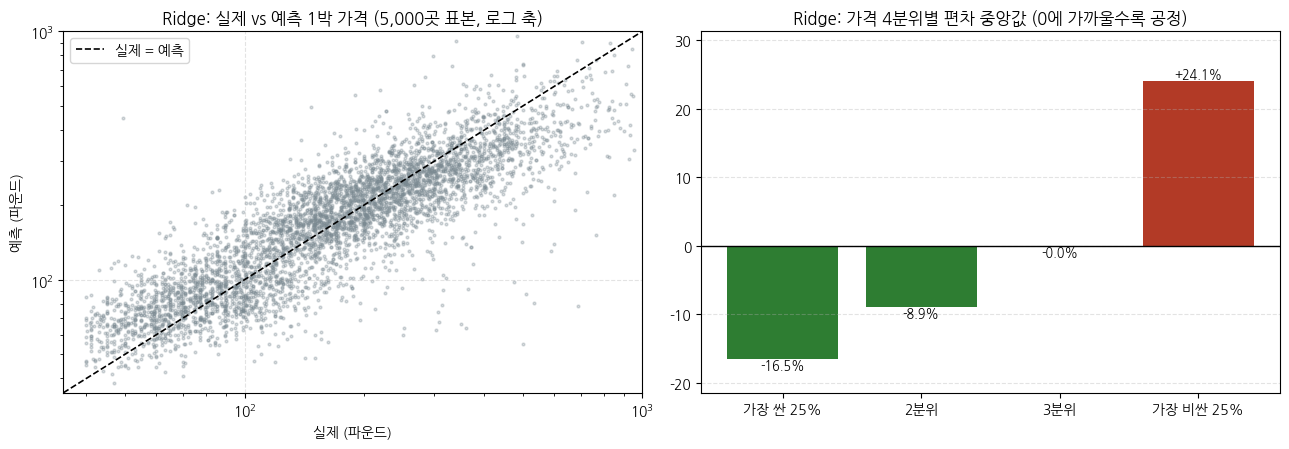

In [ ]:
# [Step 2] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 2-1. 5겹 OOF (겹 밖 예측) 성능
# ====================================================================================================
# [2-1] 원-핫 + 표준화 + Ridge (릿지 회귀) 파이프라인, 5겹 OOF 예측과 성능

lin_pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
                             ("num", StandardScaler(), num_cols)])

def make_ridge():
    return Pipeline([("pre", clone(lin_pre)), ("model", Ridge(alpha=1.0))])

oof_ridge, fr_ridge = oof_predict(make_ridge, X)
m_ridge = calc_metrics(y, oof_ridge)
print(f"Ridge: R² {m_ridge['R²']:.4f} | MAE {m_ridge['MAE (파운드)']:.1f}파운드 | MAPE {m_ridge['MAPE %']:.1f}% | MedAPE {m_ridge['MedAPE %']:.1f}%")

# ====================================================================================================
# 2-2. 계수 해석: 조건 1단위가 가격을 몇 % 움직이나
# ====================================================================================================
# [2-2] 전체 데이터로 학습한 Ridge 계수를 '조건 1단위 → 가격 변화 %'로 환산

ridge_full = make_ridge().fit(X, y)
coef = pd.Series(ridge_full.named_steps["model"].coef_, index=ridge_full.named_steps["pre"].get_feature_names_out())
sd = X[num_cols].std()
UNIT = {"accommodates": (1, "1명 늘면"), "bedrooms": (1, "1개 늘면"), "beds": (1, "1개 늘면"), "bath_n": (1, "1개 늘면"),
        "bath_shared": (1, "전용 → 공용"), "amenities_n": (10, "10개 늘면"), "dist_center_km": (1, "1km 멀어지면"),
        "latitude": (0.01, "0.01도 북쪽 (약 1.1km)"), "longitude": (0.01, "0.01도 동쪽 (약 0.7km)"),
        "quote_nights": (1, "1박 늘면")}
rows = []
for c in num_cols:
    step, label = UNIT[c]
    b = coef[f"num__{c}"] / sd[c] * step                  # 표준화 계수 → 원래 단위 계수
    rows.append({"피처": KR[c], "변화": label, "가격 변화 %": round((np.exp(b) - 1) * 100, 1)})
room_b = coef["cat__room_type_Private room"] - coef["cat__room_type_Entire home/apt"]
rows.append({"피처": "숙소 유형", "변화": "집 전체 → 개인실", "가격 변화 %": round((np.exp(room_b) - 1) * 100, 1)})
coef_table = pd.DataFrame(rows).set_index("피처")
display(coef_table)

bor = coef[coef.index.str.startswith("cat__neighbourhood_cleansed_")]
bor.index = bor.index.str.replace("cat__neighbourhood_cleansed_", "", regex=False)
bor_pct = ((np.exp(bor - bor.mean()) - 1) * 100).sort_values()
print("자치구 효과 (같은 조건일 때 33개 자치구 평균 대비)")
print("  가장 비싼 3곳: " + ", ".join(f"{k} {v:+.0f}%" for k, v in bor_pct.tail(3)[::-1].items()))
print("  가장 싼 3곳:   " + ", ".join(f"{k} {v:+.0f}%" for k, v in bor_pct.head(3).items()))

# ====================================================================================================
# 2-3. 실제 vs 예측, 가격대에 따른 쏠림
# ====================================================================================================
# [2-3] 실제·예측 산점도, 가격 4분위별 편차 중앙값 (가격대 쏠림)

ridge_bias = bias_by_quartile(oof_ridge).rename("편차 중앙값 % (실제 ÷ 예측 − 1)").to_frame()
display(ridge_bias.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
idx = np.random.RandomState(RANDOM_STATE).choice(len(y), 5000, replace=False)
axes[0].scatter(np.exp(y.values[idx]), np.exp(oof_ridge[idx]), s=4, alpha=0.3, color=MODEL_COLORS["Ridge"])
lims = np.array([35, 1000])
axes[0].plot(lims, lims, color="black", linestyle="--", linewidth=1.2, label="실제 = 예측")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_title("Ridge: 실제 vs 예측 1박 가격 (5,000곳 표본, 로그 축)")
axes[0].set_xlabel("실제 (파운드)"); axes[0].set_ylabel("예측 (파운드)")
axes[0].legend(); axes[0].grid(linestyle="--", alpha=0.35)
pos = np.arange(4); w = 0.38
vals = ridge_bias.iloc[:, 0].values
axes[1].bar(pos, vals, color=[COLORS["상대적 고가"] if v > 0 else COLORS["상대적 저가"] for v in vals])
for x, v in zip(pos, vals):
    axes[1].text(x, v, f"{v:+.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xticks(pos); axes[1].set_xticklabels(ridge_bias.index)
axes[1].set_ylim(vals.min() * 1.3, vals.max() * 1.3)
axes[1].set_title("Ridge: 가격 4분위별 편차 중앙값 (0에 가까울수록 공정)")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Step 2 실행 결과와 해석

#### 2-1. 5겹 OOF(겹 밖 예측) 성능

**결과**: 겹별 R²(결정계수) 0.7474 / 0.7394 / 0.7450 / 0.7497 / 0.7534 (표준편차 0.0047). 전체 R² **0.7470**, MAE(평균 절대 오차) **53.4파운드**, MAPE(평균 오차율) 26.3%, MedAPE(보통 숙소 오차율) **20.7%**.

**해석**: 조건 12개를 더하기만 해도 가격 차이의 75%를 설명한다. 보통 숙소는 약 21% 틀린다(169파운드 숙소라면 ±35파운드). 어느 겹을 검증에 써도 R²가 0.74~0.75로 비슷하다.

#### 2-2. 계수 해석: 조건 1단위가 가격을 몇 % 움직이나

**결과**: 같은 조건에서 하나만 바꿀 때 가격 변화 (계수 → %로 환산)

| 조건 변화 | 가격 변화 |
| --- | --- |
| 1명 늘면 (수용 인원) | +5.7% |
| 1개 늘면 (침실 수) | +19.2% |
| 1개 늘면 (침대 수) | −2.4% |
| 1개 늘면 (욕실 수) | +8.4% |
| 전용 → 공용 (공용 욕실) | −23.9% |
| 10개 늘면 (편의시설 수) | +6.2% |
| 1km 멀어지면 (도심 거리(km)) | −4.0% |
| 0.01도 북쪽 (약 1.1km) (위도) | −0.1% |
| 0.01도 동쪽 (약 0.7km) (경도) | +0.1% |
| 1박 늘면 (조회 박 수) | +0.3% |
| 집 전체 → 개인실 (숙소 유형) | −37.1% |

자치구 효과(같은 조건일 때 자치구 평균 대비): Hillingdon +34%, Richmond upon Thames +24%, Havering +24% / Lewisham −19%, Lambeth −17%, Southwark −15%.

**해석**
- 현장에서 바로 쓸 수 있는 숫자다. 예: "개인실은 같은 조건의 집 전체보다 약 37% 싸다", "침실 하나가 약 19% 값을 한다."
- 이상한 숫자가 선형 모델의 한계를 보여 준다. 외곽인 Hillingdon이 가장 비싸게 나오는 것은 도심 거리를 '1km마다 같은 %'로 깎다 보니 먼 외곽이 너무 많이 깎이고, 자치구 계수가 그만큼 되돌려 주기 때문이다. 실제 가격은 거리에 따라 직선으로 떨어지지 않는다.
- 침대 수가 −2.4%인 것은 침실·인원이 같은데 침대만 많으면 좁은 방(이층 침대 등)이라는 뜻으로 읽힌다.

#### 2-3. 실제 vs 예측, 가격대에 따른 쏠림

**결과**: 가격 4분위마다 편차(실제 ÷ 예측 − 1)의 중앙값

| 가격 4분위 | 편차 중앙값 |
| --- | --- |
| 가장 싼 25% | −16.5% |
| 2분위 | −8.9% |
| 3분위 | −0.0% |
| 가장 비싼 25% | +24.1% |

**해석**: 가장 싼 25%는 실제 가격이 예측보다 16% 낮고, 가장 비싼 25%는 24% 높다. 즉 Ridge는 **싼 숙소는 비싸게, 비싼 숙소는 싸게 예측한다.** 이 예측을 기준으로 쓰면 비싼 숙소는 비싸다는 이유만으로 '시세보다 비싸게 받는 숙소'처럼 보이게 된다. 이것을 **가격대 쏠림**이라 부르고, 크기는 두 끝의 차이(쏠림 폭) 40.6%p로 잰다. 공정한 기준이 되려면 이 폭이 줄어야 한다. 이 비교는 편차 기준선 없이 편차 값만으로 계산한다.

### Step 2 종합 분석
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 성능 | R²(결정계수) 0.747, 보통 오차 20.7% | 더하기만으로도 상당 부분 맞힌다 |
| 해석력 | 개인실 −37%, 공용 욕실 −24%, 침실 +19% | 조건의 값을 %로 말할 수 있다 |
| 한계 | 가장 싼 25% 편차 −16.5%, 가장 비싼 25% +24.1% (쏠림 폭 40.6%p) | 가격대 쏠림이 커서 그대로 기준으로 쓰기 어렵다 |

**의견**: Ridge는 설명용으로 좋지만, 조건의 조합(예: 개인실에서는 침실보다 욕실 공유가 중요)을 못 본다.

**다음 질문**: 조건의 조합을 질문 규칙으로 나누는 결정트리는 이 쏠림을 줄일 수 있을까? → Step 3

---
## Step 3. 결정트리: 가격을 가르는 규칙
**문제 제기**: Ridge는 "침실 1개 = 몇 %"를 모든 숙소에 똑같이 적용한다. 그래서 '도심의 큰 집'처럼 조건이 겹칠 때 가격이 더 뛰는 효과를 못 잡는다. 질문을 여러 번 나눠 묻는 결정트리는 이런 조합을 잡을 수 있을까?

**모델 선택 이유**: 결정트리는 "개인실인가?", "침실이 1.5개를 넘는가?" 같은 질문으로 숙소를 나누고, 마지막 묶음의 평균 가격을 예측으로 쓴다. 규칙을 그대로 보여줄 수 있어 현장 설명이 쉽다.

**전처리**: 자치구·숙소 유형만 0/1로 바꾸고 숫자는 그대로 둔다. 트리는 숫자 크기에 영향을 받지 않고, 규칙을 실제 단위(km, 개)로 읽을 수 있어서다.

,규칙 (위에서부터 질문 순서),숙소수,예측 1박 (파운드),실제_중앙값_파운드
0,개인실 → 공용 욕실 → 도심 거리(km) > 7.5,2212,65.0,62.0
1,개인실 → 공용 욕실 → 도심 거리(km) ≤ 7.5,2656,84.0,80.0
2,개인실 → 전용 욕실 → 도심 거리(km) > 6.7,2007,86.0,84.0
3,개인실 → 전용 욕실 → 도심 거리(km) ≤ 6.7,1728,120.0,115.0
4,집 전체 → 침실 수 ≤ 1.5 → 도심 거리(km) > 6.4,3064,138.0,137.0
5,집 전체 → 침실 수 ≤ 1.5 → 도심 거리(km) ≤ 6.4,5493,198.0,196.0
6,집 전체 → 침실 수 > 1.5 → 욕실 수 ≤ 1.8,4117,246.0,242.0
7,집 전체 → 침실 수 > 1.5 → 욕실 수 > 1.8,4330,365.0,364.0


규칙 8개 트리의 설명력 (학습 데이터 기준) R² 0.676


,규칙 수 (마지막 묶음),R²,MAE (파운드),MedAPE %,겹 간 R² 표준편차
최대 깊이,,,,,
3,8,0.6749,62.5640,24.3708,0.0061
6,61,0.7421,54.2495,21.4055,0.0051
9,314,0.7560,52.0229,20.3834,0.0068
12,691,0.7583,51.9802,20.1809,0.0069
15,910,0.7576,52.0800,20.2351,0.0063
20,978,0.7571,52.1201,20.2263,0.0060


선택: 최대 깊이 12 → R² 0.7583 | MAE 52.0파운드 | MedAPE 20.2% | 규칙 691개


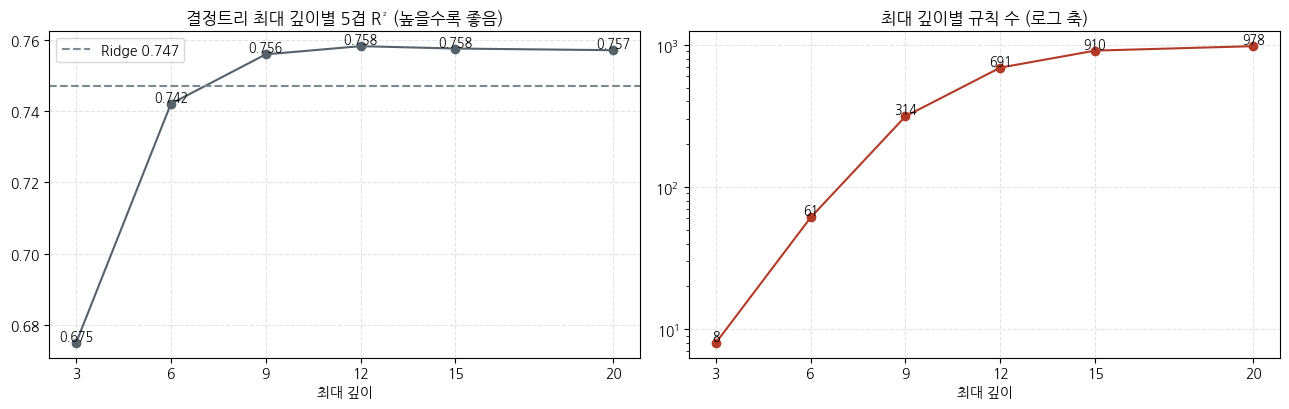

In [ ]:
# [Step 3] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 3-1. 깊이 3 트리: 가격을 가르는 첫 규칙
# ====================================================================================================
# [3-1] 질문 3번(깊이 3)짜리 트리로 가격을 가르는 핵심 규칙과 묶음별 가격 확인 (설명용, 전체 데이터로 학습)

tree_pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)],
                             remainder="passthrough", verbose_feature_names_out=False)
small_tree = Pipeline([("pre", clone(tree_pre)),
                       ("model", DecisionTreeRegressor(max_depth=3, min_samples_leaf=200, random_state=RANDOM_STATE))]).fit(X, y)
names = small_tree.named_steps["pre"].get_feature_names_out()
tree_ = small_tree.named_steps["model"].tree_
TYPE_KR = {"Entire home/apt": "집 전체", "Private room": "개인실"}

def cond_text(name, thr, go_left):
    if name.startswith("room_type_"):
        rt = name.replace("room_type_", "")
        other = [v for k, v in TYPE_KR.items() if k != rt][0]
        return other if go_left else TYPE_KR[rt]
    if name.startswith("neighbourhood_cleansed_"):
        b = name.replace("neighbourhood_cleansed_", "")
        return f"{b} 아님" if go_left else b
    if name == "bath_shared":
        return "전용 욕실" if go_left else "공용 욕실"
    return f"{KR[name]} ≤ {thr:.1f}" if go_left else f"{KR[name]} > {thr:.1f}"

rules = {}
def walk(node, conds):
    if tree_.children_left[node] == -1:
        rules[node] = conds
        return
    name, thr = names[tree_.feature[node]], tree_.threshold[node]
    walk(tree_.children_left[node], conds + [cond_text(name, thr, True)])
    walk(tree_.children_right[node], conds + [cond_text(name, thr, False)])
walk(0, [])

leaf = small_tree.named_steps["model"].apply(small_tree.named_steps["pre"].transform(X))
rule_table = pd.DataFrame({"leaf": leaf, "price": df["price_gbp"].values}).groupby("leaf").agg(숙소수=("price", "size"), 실제_중앙값_파운드=("price", "median"))
rule_table["규칙 (위에서부터 질문 순서)"] = [" → ".join(rules[i]) for i in rule_table.index]
rule_table["예측 1박 (파운드)"] = [np.exp(tree_.value[i].ravel()[0]) for i in rule_table.index]
rule_table = rule_table.sort_values("예측 1박 (파운드)")[["규칙 (위에서부터 질문 순서)", "숙소수", "예측 1박 (파운드)", "실제_중앙값_파운드"]].reset_index(drop=True)
display(rule_table.round(0))
print(f"규칙 {len(rule_table)}개 트리의 설명력 (학습 데이터 기준) R² {r2_score(y, small_tree.predict(X)):.3f}")

# ====================================================================================================
# 3-2. 깊이에 따른 성능과 규칙 수
# ====================================================================================================
# [3-2] 최대 깊이 3~20의 5겹 OOF (겹 밖 예측) 성능과 마지막 묶음(규칙) 수 비교 → 성능이 가장 좋은 깊이 선택

depth_rows, oof_by_depth = [], {}
for d in [3, 6, 9, 12, 15, 20]:
    def make_dt(d=d):
        return Pipeline([("pre", clone(tree_pre)), ("model", DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=RANDOM_STATE))])
    oof_d, fr = oof_predict(make_dt, X, verbose=False)
    oof_by_depth[d] = oof_d
    m = calc_metrics(y, oof_d)
    depth_rows.append({"최대 깊이": d, "규칙 수 (마지막 묶음)": make_dt().fit(X, y).named_steps["model"].get_n_leaves(),
                       "R²": m["R²"], "MAE (파운드)": m["MAE (파운드)"], "MedAPE %": m["MedAPE %"], "겹 간 R² 표준편차": np.std(fr)})
depth_table = pd.DataFrame(depth_rows).set_index("최대 깊이")
display(depth_table.round(4))
best_depth = int(depth_table["R²"].idxmax())
oof_dt = oof_by_depth[best_depth]
m_dt = calc_metrics(y, oof_dt)
print(f"선택: 최대 깊이 {best_depth} → R² {m_dt['R²']:.4f} | MAE {m_dt['MAE (파운드)']:.1f}파운드 | MedAPE {m_dt['MedAPE %']:.1f}% | 규칙 {depth_table.loc[best_depth, '규칙 수 (마지막 묶음)']:,}개")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(depth_table.index, depth_table["R²"], marker="o", color=MODEL_COLORS["DecisionTree"])
axes[0].axhline(m_ridge["R²"], color=MODEL_COLORS["Ridge"], linestyle="--", label=f"Ridge {m_ridge['R²']:.3f}")
for d, v in depth_table["R²"].items():
    axes[0].text(d, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
axes[0].set_title("결정트리 최대 깊이별 5겹 R² (높을수록 좋음)"); axes[0].set_xlabel("최대 깊이"); axes[0].set_xticks(depth_table.index)
axes[0].legend(); axes[0].grid(linestyle="--", alpha=0.35)
axes[1].plot(depth_table.index, depth_table["규칙 수 (마지막 묶음)"], marker="o", color="#B23A26")
axes[1].set_yscale("log")
for d, v in depth_table["규칙 수 (마지막 묶음)"].items():
    axes[1].text(d, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[1].set_title("최대 깊이별 규칙 수 (로그 축)"); axes[1].set_xlabel("최대 깊이"); axes[1].set_xticks(depth_table.index)
axes[1].grid(linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Step 3 실행 결과와 해석

#### 3-1. 깊이 3 트리: 가격을 가르는 첫 규칙

**결과**: 질문 3번으로 숙소를 8묶음으로 나눈 규칙 (예측 1박이 싼 순서)

| 규칙 | 숙소 수 | 예측 1박 |
| --- | --- | --- |
| 개인실 → 공용 욕실 → 도심 거리(km) > 7.5 | 2,212 | 65파운드 |
| 개인실 → 공용 욕실 → 도심 거리(km) ≤ 7.5 | 2,656 | 84파운드 |
| 개인실 → 전용 욕실 → 도심 거리(km) > 6.7 | 2,007 | 86파운드 |
| 개인실 → 전용 욕실 → 도심 거리(km) ≤ 6.7 | 1,728 | 120파운드 |
| 집 전체 → 침실 수 ≤ 1.5 → 도심 거리(km) > 6.4 | 3,064 | 138파운드 |
| 집 전체 → 침실 수 ≤ 1.5 → 도심 거리(km) ≤ 6.4 | 5,493 | 198파운드 |
| 집 전체 → 침실 수 > 1.5 → 욕실 수 ≤ 1.8 | 4,117 | 246파운드 |
| 집 전체 → 침실 수 > 1.5 → 욕실 수 > 1.8 | 4,330 | 365파운드 |

규칙 8개만으로 R²(결정계수) 0.676(학습 데이터 기준).

**해석**: 가격을 가르는 첫 질문은 **집 전체냐 개인실이냐**다. 개인실은 다음으로 **욕실을 같이 쓰는가**, 집 전체는 **침실이 2개 이상인가**를 묻는다. 유형마다 다른 질문을 한다는 것이 Ridge와의 차이다. 현장 설명용으로 이 표를 그대로 쓸 수 있다.

#### 3-2. 깊이에 따른 성능과 규칙 수

**결과**

| 최대 깊이 | 규칙 수 | 5겹 R² | MedAPE(보통 숙소 오차율) |
| --- | --- | --- | --- |
| 3 | 8 | 0.675 | 24.4% |
| 6 | 61 | 0.742 | 21.4% |
| 9 | 314 | 0.756 | 20.4% |
| **12** | 691 | 0.758 | 20.2% |
| 15 | 910 | 0.758 | 20.2% |
| 20 | 978 | 0.757 | 20.2% |

선택: 최대 깊이 12 → R² 0.7583, MAE(평균 절대 오차) 52.0파운드, MedAPE 20.2%.

**해석**: 깊이 6까지는 성능이 빠르게 오르지만, 9 이후로는 규칙만 늘고 성능은 멈춘다. 가장 좋은 깊이 12도 Ridge(0.747)보다 0.011 높을 뿐이고, 규칙이 691개라 더 이상 '읽는 규칙'이 아니다. **설명하기 좋은 트리(깊이 3)는 부정확하고, 정확한 트리는 설명이 어렵다.**

### Step 3 종합 분석
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 가격을 가르는 규칙 | 유형 → (개인실) 욕실 공유 / (집 전체) 침실 수 → 도심 거리 | 유형마다 가격을 정하는 조건이 다르다 |
| 성능 | 최고 R²(결정계수) 0.758 (깊이 12) | Ridge보다 조금 나을 뿐이다 |

**의견**: 결정트리는 '조건의 조합'이 중요하다는 것을 보여 줬다. 하지만 트리 하나로는 정확도가 부족하고, 데이터가 조금만 바뀌어도 규칙이 바뀐다.

**다음 질문**: 트리 200개를 평균내면 정확하면서도 '비슷한 숙소들의 평균 가격'이라는 쉬운 설명을 유지할 수 있을까? → Step 4

---
## Step 4. 랜덤포레스트: 비슷한 숙소들의 평균 가격
**문제 제기**: 결정트리는 깊어질수록 정확해지지만 규칙이 수천 개가 되고, 데이터가 조금만 바뀌어도 규칙이 달라진다. 트리를 여러 개 만들어 평균내면 안정적이면서 정확해질까?

**모델 선택 이유**: 랜덤포레스트는 숙소를 무작위로 다시 뽑아 결정트리 200개를 만들고 예측을 평균한다. 한 숙소의 예측은 결국 **"각 트리에서 같은 마지막 묶음에 들어간 비슷한 숙소들의 가격 평균"**이다. "같은 조건이면 보통 받는 가격"이라는 추정 시세의 정의와 그대로 맞는다. 기본 설정으로도 잘 동작해 따로 튜닝할 필요가 거의 없다.

**설정**: 트리 200개(`n_estimators=200`), 마지막 묶음 최소 2곳(`min_samples_leaf=2`), 나머지는 sklearn 기본값. 전처리는 결정트리와 같다.

| Step 4~6 | 추정 시세 만들기 | 트리 200개, 마지막 묶음 최소 2곳, 나머지 sklearn 기본값 |

겹별 R²: 0.8019 / 0.7953 / 0.8042 / 0.8062 / 0.8038 (표준편차 0.0037)
RandomForest: R² 0.8023 | MAE 46.6파운드 | MAPE 22.6% | MedAPE 17.5% | 94초


,R²,MAE (파운드),MAPE %,MedAPE %,가장 싼 25% 편차 중앙값 %,가장 비싼 25% 편차 중앙값 %,쏠림 폭 %p
모델,,,,,,,
Ridge,0.747,53.413,26.338,20.668,-16.500,24.103,40.603
DecisionTree,0.758,51.980,25.621,20.181,-13.576,17.798,31.373
RandomForest,0.802,46.617,22.577,17.521,-11.634,15.702,27.335


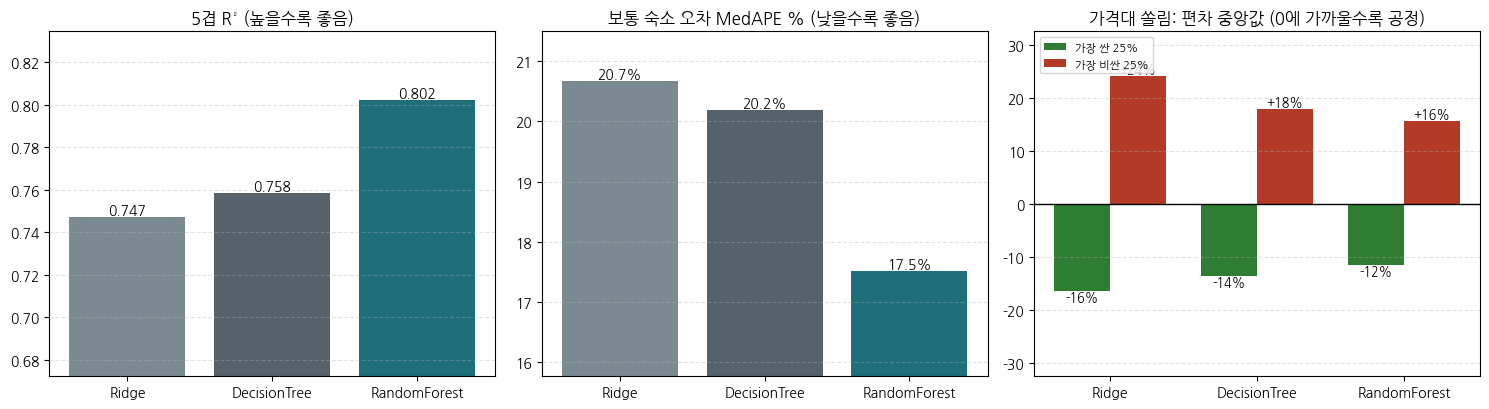

예시 숙소: Kensington and Chelsea · 집 전체 · 4명 · 침실 2 · 욕실 1.0 · 도심 5.3km · 실제 1박 276파운드
비슷한 숙소로 한 번 이상 뽑힌 학습 숙소: 151곳 | 가중치 상위 10곳의 비중 44%


,자치구,수용 인원,침실,욕실,도심 거리 km,1박 (파운드),가중치
13536,Kensington and Chelsea,8,2.0,1.0,5.030,205.67,0.066
19053,Kensington and Chelsea,4,2.0,1.0,5.129,489.00,0.060
11981,Kensington and Chelsea,8,2.0,1.0,4.968,190.50,0.055
17751,Kensington and Chelsea,5,2.0,1.0,4.797,268.50,0.043
16497,Kensington and Chelsea,4,2.0,1.0,4.867,474.67,0.042
2416,Kensington and Chelsea,4,2.0,0.0,5.292,382.00,0.040
1674,Kensington and Chelsea,6,2.0,1.0,4.872,540.00,0.039
12851,Kensington and Chelsea,4,2.0,1.0,5.839,248.75,0.033


비슷한 숙소 가격의 가중 평균 327파운드 | 모델 예측(추정 시세) 328파운드 | 실제 276파운드


In [ ]:
# [Step 4] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 4-1. 5겹 OOF (겹 밖 예측) 성능
# ====================================================================================================
# [4-1] 랜덤포레스트 5겹 OOF 예측과 성능 (약 1분)

def make_rf(features_pre=tree_pre):
    return Pipeline([("pre", clone(features_pre)),
                     ("model", RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))])

start = time.time()
oof_rf, fr_rf = oof_predict(make_rf, X)
m_rf = calc_metrics(y, oof_rf)
print(f"RandomForest: R² {m_rf['R²']:.4f} | MAE {m_rf['MAE (파운드)']:.1f}파운드 | MAPE {m_rf['MAPE %']:.1f}% | MedAPE {m_rf['MedAPE %']:.1f}% | {time.time() - start:.0f}초")

# ====================================================================================================
# 4-2. 세 모델 비교
# ====================================================================================================
# [4-2] Ridge (릿지 회귀)·결정트리·랜덤포레스트의 성능과 가격대 쏠림 비교

models_oof = {"Ridge": oof_ridge, "DecisionTree": oof_dt, "RandomForest": oof_rf}
cmp_rows = []
for name, p in models_oof.items():
    b = bias_by_quartile(p)
    cmp_rows.append({"모델": name, **calc_metrics(y, p),
                     "가장 싼 25% 편차 중앙값 %": b.loc["가장 싼 25%"], "가장 비싼 25% 편차 중앙값 %": b.loc["가장 비싼 25%"],
                     "쏠림 폭 %p": b.loc["가장 비싼 25%"] - b.loc["가장 싼 25%"]})
compare = pd.DataFrame(cmp_rows).set_index("모델")
display(compare.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
names_m = compare.index.tolist()
cols_m = [MODEL_COLORS[n] for n in names_m]
for ax, col, title, fmt in [(axes[0], "R²", "5겹 R² (높을수록 좋음)", "{:.3f}"), (axes[1], "MedAPE %", "보통 숙소 오차 MedAPE % (낮을수록 좋음)", "{:.1f}%")]:
    vals = compare[col].values
    ax.bar(names_m, vals, color=cols_m)
    ax.set_ylim(vals.min() * 0.9, vals.max() * 1.04)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=10)
    ax.set_title(title); ax.grid(axis="y", linestyle="--", alpha=0.35)
pos = np.arange(3); w = 0.38
for j, (col, c, lab) in enumerate([("가장 싼 25% 편차 중앙값 %", COLORS["상대적 저가"], "가장 싼 25%"),
                                   ("가장 비싼 25% 편차 중앙값 %", COLORS["상대적 고가"], "가장 비싼 25%")]):
    vals = compare[col].values
    axes[2].bar(pos + (j - 0.5) * w, vals, width=w, color=c, label=lab)
    for x, v in zip(pos + (j - 0.5) * w, vals):
        axes[2].text(x, v, f"{v:+.0f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set_xticks(pos); axes[2].set_xticklabels(names_m)
axes[2].set_title("가격대 쏠림: 편차 중앙값 (0에 가까울수록 공정)"); axes[2].legend(fontsize=8, loc="upper left")
lim_b = np.abs(compare[["가장 싼 25% 편차 중앙값 %", "가장 비싼 25% 편차 중앙값 %"]].values).max() * 1.35
axes[2].set_ylim(-lim_b, lim_b)
axes[2].grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# ====================================================================================================
# 4-3. 추정 시세는 어떻게 만들어지나: 숙소 1곳 예시
# ====================================================================================================
# [4-3] 숙소 1곳의 랜덤포레스트 예측을 '비슷한 숙소들의 가격 평균'으로 풀어 보기 (첫 번째 겹 모델 사용)

tr_idx, te_idx = next(iter(kf.split(X)))
rf_demo = make_rf().fit(X.iloc[tr_idx], y.iloc[tr_idx])
pre_demo, forest = rf_demo.named_steps["pre"], rf_demo.named_steps["model"]

# 예시: 검증 묶음 중 '집 전체 · 4명 · 침실 2개'이면서 도심 거리가 그 묶음의 중앙값에 가장 가까운 숙소
cand = df.iloc[te_idx]
cand = cand[(cand["room_type"] == "Entire home/apt") & (cand["accommodates"] == 4) & (cand["bedrooms"] == 2)]
ex = df.index.get_loc((cand["dist_center_km"] - cand["dist_center_km"].median()).abs().idxmin())

leaves_tr = forest.apply(pre_demo.transform(X.iloc[tr_idx]))            # 학습 숙소마다 200개 트리에서 들어간 마지막 묶음 번호
leaves_ex = forest.apply(pre_demo.transform(X.iloc[[ex]]))[0]
same_leaf = leaves_tr == leaves_ex                                     # 트리마다 예시 숙소와 같은 묶음에 들어간 학습 숙소
weight = (same_leaf / same_leaf.sum(axis=0)).mean(axis=1)              # 트리마다 같은 묶음 숙소에 1/묶음 크기 → 200개 평균
neigh = df.iloc[tr_idx][["neighbourhood_cleansed", "accommodates", "bedrooms", "bath_n", "dist_center_km", "price_gbp"]].assign(가중치=weight)
neigh = neigh[neigh["가중치"] > 0].sort_values("가중치", ascending=False)

e = df.iloc[ex]
print(f"예시 숙소: {e['neighbourhood_cleansed']} · 집 전체 · {e['accommodates']}명 · 침실 {e['bedrooms']:.0f} · 욕실 {e['bath_n']:.1f} · 도심 {e['dist_center_km']:.1f}km · 실제 1박 {e['price_gbp']:.0f}파운드")
print(f"비슷한 숙소로 한 번 이상 뽑힌 학습 숙소: {len(neigh):,}곳 | 가중치 상위 10곳의 비중 {neigh['가중치'].head(10).sum():.0%}")
display(neigh.head(8).rename(columns={"neighbourhood_cleansed": "자치구", "accommodates": "수용 인원", "bedrooms": "침실",
                                      "bath_n": "욕실", "dist_center_km": "도심 거리 km", "price_gbp": "1박 (파운드)"}).round(3))
wavg = np.exp(np.sum(weight * y.iloc[tr_idx].values))
print(f"비슷한 숙소 가격의 가중 평균 {wavg:.0f}파운드 | 모델 예측(추정 시세) {np.exp(rf_demo.predict(X.iloc[[ex]])[0]):.0f}파운드 | 실제 {e['price_gbp']:.0f}파운드")

### Step 4 실행 결과와 해석

#### 4-1. 5겹 OOF(겹 밖 예측) 성능

**결과**: 겹별 R²(결정계수) 0.8019 / 0.7953 / 0.8042 / 0.8062 / 0.8038 (표준편차 0.0037). 전체 R² **0.8023**, MAE(평균 절대 오차) **46.6파운드**, MAPE(평균 오차율) 22.6%, MedAPE(보통 숙소 오차율) **17.5%**.

**해석**: 가격 차이의 80%를 설명한다. 보통 숙소 오차는 17.5%로 Ridge(20.7%)보다 3.1%p 작다. 169파운드 숙소라면 오차가 ±35파운드에서 ±30파운드로 줄어든다.

#### 4-2. 세 모델 비교

**결과**

| 모델 | R² | MAE (파운드) | MedAPE | 가장 싼 25% 편차 중앙값 | 가장 비싼 25% 편차 중앙값 | 쏠림 폭 |
| --- | --- | --- | --- | --- | --- | --- |
| Ridge(릿지 회귀) | 0.747 | 53.4 | 20.7% | −16.5% | +24.1% | 40.6%p |
| 결정트리 | 0.758 | 52.0 | 20.2% | −13.6% | +17.8% | 31.4%p |
| **랜덤포레스트** | 0.802 | 46.6 | 17.5% | −11.6% | +15.7% | 27.3%p |

**해석**: 랜덤포레스트가 모든 지표에서 가장 좋다. 가장 중요한 차이는 **가격대 쏠림**이다. 비싼 숙소와 싼 숙소의 편차 중앙값 차이(쏠림 폭)가 Ridge 40.6%p → 랜덤포레스트 27.3%p로 줄었다. 그래도 가장 비싼 25%의 편차 중앙값이 +15.7%로, 쏠림이 완전히 없어지지는 않았다. 인테리어·전망 같은 고급 요소가 데이터에 없기 때문이며, 한계로 남긴다.

#### 4-3. 추정 시세는 어떻게 만들어지나: 숙소 1곳 예시

**결과**: Kensington and Chelsea · 집 전체 · 4명 · 침실 2 · 욕실 1 · 도심 5.3km 숙소(실제 1박 276파운드)
- 200개 트리가 이 숙소와 같은 마지막 묶음으로 고른 학습 숙소는 **151곳**이고, 가중치 상위 10곳이 44%를 차지한다.
- 이 숙소들 가격의 가중 평균은 **327파운드**, 모델 예측(추정 시세)은 **328파운드**로 거의 같다.
- 실제 276파운드는 추정 시세보다 16% 싸다.

**해석**: 추정 시세는 '같은 유형의 단순 평균'이 아니라 **조건 12개가 비슷한 숙소 150여 곳의 가격 가중 평균**이다. 호스트에게 "비슷한 숙소들은 보통 이만큼 받는다"고 그대로 설명할 수 있다.

### Step 4 종합 분석
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 성능 | R²(결정계수) 0.802, 보통 오차 17.5% (세 모델 중 최고) | 가장 정확하다 |
| 가격대 쏠림 | 쏠림 폭 27.3%p (Ridge(릿지 회귀) 40.6%p) | 가장 공정하다 |
| 설명 | 비슷한 숙소 151곳의 가중 평균 327파운드 ≈ 추정 시세 328파운드 | '같은 조건이면 보통 받는 가격'이라는 정의와 맞다 |

**의견**: 랜덤포레스트를 최종 모델로 정한다. 정확하고, 가격대 쏠림이 가장 작고, '비슷한 숙소들의 평균'으로 쉽게 설명된다. 기본 설정으로 충분히 안정적이다.

**다음 질문**: 이 모델은 무엇을 보고 가격을 정할까? → Step 5

---
## Step 5. 피처 중요도: 모델은 무엇을 보고 가격을 정하나
**문제 제기**: 랜덤포레스트에는 Ridge 같은 계수가 없다. 그럼 어떤 조건에 기대어 가격을 정하는지 어떻게 확인할까? 위치·유형·규모 중 무엇이 가장 중요할까?

**방법**: 순열 중요도. 검증 묶음에서 피처 하나의 값을 무작위로 섞었을 때 R²가 얼마나 떨어지는지 잰다. 많이 떨어질수록 모델이 그 피처에 많이 기댄다. 5겹마다 3번씩 섞어 평균한다.

,순위,피처,R² 하락 (5겹 평균),겹 간 표준편차
room_type,1,숙소 유형,0.2636,0.0118
dist_center_km,2,도심 거리(km),0.2077,0.0064
bedrooms,3,침실 수,0.1188,0.0074
accommodates,4,수용 인원,0.0561,0.0065
amenities_n,5,편의시설 수,0.0413,0.0031
bath_n,6,욕실 수,0.0396,0.0016
longitude,7,경도,0.0287,0.0002
bath_shared,8,공용 욕실,0.0272,0.0030
latitude,9,위도,0.0216,0.0014
neighbourhood_cleansed,10,자치구,0.0070,0.0013


상위 3개 합 0.590 | 125초


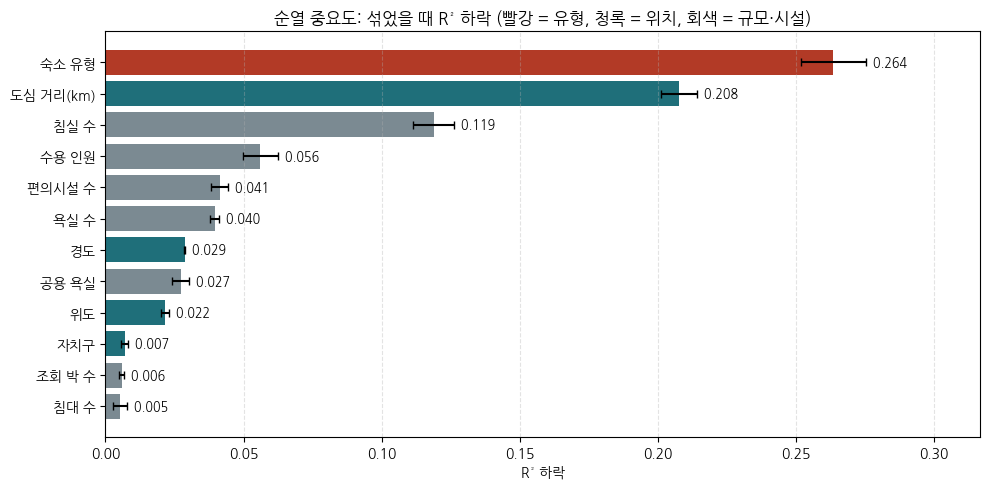

In [ ]:
# [Step 5] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 5-1. 5겹 순열 중요도
# ====================================================================================================
# [5-1] 겹마다 랜덤포레스트를 학습하고 검증 묶음에서 피처를 하나씩 섞어 R² (결정계수) 하락 측정 (약 1~2분)

start = time.time()
imp_list = []
for tr, te in kf.split(X):
    model = make_rf().fit(X.iloc[tr], y.iloc[tr])
    r = permutation_importance(model, X.iloc[te], y.iloc[te], n_repeats=3, random_state=RANDOM_STATE, scoring="r2")
    imp_list.append(r.importances_mean)
imp = pd.DataFrame(imp_list, columns=feature_cols)
imp_table = pd.DataFrame({"피처": [KR[c] for c in feature_cols], "R² 하락 (5겹 평균)": imp.mean().values,
                          "겹 간 표준편차": imp.std().values}, index=feature_cols).sort_values("R² 하락 (5겹 평균)", ascending=False)
imp_table.insert(0, "순위", range(1, len(imp_table) + 1))
display(imp_table.round(4))
print(f"상위 3개 합 {imp_table['R² 하락 (5겹 평균)'].head(3).sum():.3f} | {time.time() - start:.0f}초")

# ====================================================================================================
# 5-2. 중요도 그래프
# ====================================================================================================
# [5-2] 피처 12개 중요도와 겹 간 흔들림

fig, ax = plt.subplots(figsize=(10, 5))
t = imp_table.iloc[::-1]
grp_color = {"자치구": "#1F6F7A", "도심 거리(km)": "#1F6F7A", "위도": "#1F6F7A", "경도": "#1F6F7A", "숙소 유형": "#B23A26"}
ax.barh(t["피처"], t["R² 하락 (5겹 평균)"], xerr=t["겹 간 표준편차"], color=[grp_color.get(n, "#7B8A92") for n in t["피처"]], capsize=3)
for i, (v, sdv) in enumerate(zip(t["R² 하락 (5겹 평균)"], t["겹 간 표준편차"])):
    ax.text(v + sdv, i, f"  {v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, (t["R² 하락 (5겹 평균)"] + t["겹 간 표준편차"]).max() * 1.15)
ax.set_title("순열 중요도: 섞었을 때 R² 하락 (빨강 = 유형, 청록 = 위치, 회색 = 규모·시설)")
ax.set_xlabel("R² 하락")
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Step 5 실행 결과와 해석

#### 5-1. 5겹 순열 중요도

**결과**: 섞었을 때 R²(결정계수) 하락 (5겹 평균)

| 순위 | 피처 | R² 하락 |
| --- | --- | --- |
| 1 | 숙소 유형 | **0.264** |
| 2 | 도심 거리(km) | **0.208** |
| 3 | 침실 수 | **0.119** |
| 4 | 수용 인원 | 0.056 |
| 5 | 편의시설 수 | 0.041 |
| 6 | 욕실 수 | 0.040 |
| 7 | 경도 | 0.029 |
| 8 | 공용 욕실 | 0.027 |
| 9 | 위도 | 0.022 |
| 10 | 자치구 | 0.007 |
| 11 | 조회 박 수 | 0.006 |
| 12 | 침대 수 | 0.005 |

상위 3개 합 0.590.

**해석**: 숙소 유형을 무작위로 섞으면 R²가 0.26 떨어진다. 가격은 **유형 → 도심 거리 → 침실 수** 순으로 정해진다. 자치구가 낮은 것은 도심 거리·위도·경도가 위치 정보를 이미 담고 있어서이고, 위치가 덜 중요하다는 뜻은 아니다.

#### 5-2. 중요도 그래프

**결과**: 막대 끝의 검은 선(겹 간 표준편차)이 모두 짧다(최대 0.012). 빨강(유형)과 청록(위치) 막대가 위쪽을 차지한다.

**해석**: 어느 겹으로 재도 순위가 같다. 중요도 순위를 믿을 수 있다.

### Step 5 종합 분석
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 가장 중요한 조건 | 숙소 유형 0.264, 도심 거리 0.208, 침실 수 0.119 | 추정 시세는 '어떤 유형을, 어디서, 얼마나 크게'로 정해진다 |
| Step 2·3과 일치 | Ridge(릿지 회귀) 계수(개인실 −37%, 침실 +19%), 트리 첫 질문(유형) | 세 모델이 같은 조건을 중요하게 본다 |

**의견**: 세 모델이 같은 이야기를 한다. 호스트에게 "유형·위치·침실 수가 같은 숙소들과 비교했다"고 말하면 핵심을 다 말한 것이다.

**다음 질문**: 숙소마다 추정 시세와 편차는 얼마이고, '크게 벗어났다'는 기준선은 어디에 두어야 할까? → Step 6

---
## Step 6. 추정 시세와 편차, 편차 기준선
**문제 제기**: 이제 숙소마다 추정 시세를 정하고 실제 가격과 비교할 차례다. 누가 얼마나 비싸게·싸게 받고 있고, 그것은 숙소 유형에 따라 다른가?

**방법**
- 최종 모델은 Step 4에서 고른 랜덤포레스트다. 그 5겹 OOF 예측 `oof_pred_final`을 파운드로 바꾼 값이 **추정 시세**이다.
- 편차(gap) = (실제 가격 − 추정 시세) ÷ 추정 시세. +0.30이면 시세보다 30% 비싸게 받는다는 뜻이다.
- **편차 기준선**은 6-2에서 편차 값을 보고 정한다. 규칙: 숙소들이 추정 시세에서 보통 떨어진 정도(|편차|의 중앙값)를 넘는 첫 5% 단위. 보통 범위 안의 차이는 모델이 못 보는 사소한 차이로도 생기므로, 그보다 크게 벗어난 숙소만 상대적 고가·저가로 나눈다.
- 1년 추정 수익 = 1박 가격 × 지난 1년 추정 예약일. 파일의 수익 열을 쓰지 않고 여기서 직접 계산한다.

### Step 6 실행 결과와 해석

#### 6-1. 추정 시세와 편차

**결과**
- 추정 시세 중앙값 173파운드, 실제 가격 중앙값 169파운드.
- 편차 분위수: 하위 10% −29.3%, 하위 25% −16.9%, 중앙 −1.7%, 상위 25% +17.7%, 상위 10% +43.5%.

| 위치 | 자치구 | 유형 | 실제 | 추정 시세 | 편차 |
| --- | --- | --- | --- | --- | --- |
| 하위 5% | Ealing | 집 전체 4명 | 132파운드 | 207파운드 | −36.4% |
| 하위 25% | Hackney | 개인실 2명 | 75파운드 | 90파운드 | −16.9% |
| 중앙 | Westminster | 개인실 8명 | 77파운드 | 78파운드 | −1.7% |
| 상위 25% | Brent | 집 전체 5명 | 321파운드 | 273파운드 | +17.7% |
| 상위 5% | Westminster | 집 전체 2명 | 252파운드 | 154파운드 | +63.7% |

**해석**: 편차의 중앙값이 −1.7%로 0에 가깝다. 추정 시세가 한쪽으로 치우치지 않은 기준이라는 뜻이다. 숙소의 절반은 편차가 −16.9% ~ +17.7% 사이에 있다.

#### 6-2. 편차 분포와 기준선

**결과**
- 숙소가 추정 시세에서 보통 떨어진 정도(|편차| 중앙값): **17.2%** → 이를 넘는 첫 5% 단위 = **편차 기준선 ±20%**.
- 편차 ±20% 안 숙소 56.4%.

| 기준선 | 상대적 저가 | 시세 수준 | 상대적 고가 |
| --- | --- | --- | --- |
| ±10% | 9,192 (35.9%) | 7,860 (30.7%) | 8,555 (33.4%) |
| **±20%** | 5,260 (20.5%) | 14,450 (56.4%) | 5,897 (23.0%) |
| ±30% | 2,428 (9.5%) | 19,058 (74.4%) | 4,121 (16.1%) |

- 숙소 유형별 상대적 고가 비율: 집 전체 23.2%, 개인실 22.7%.

**해석 (편차 값이 기준선을 정한 과정)**
1. 모델이 만든 추정 시세와 실제 가격을 비교하니, 숙소들은 추정 시세에서 **보통 17.2%** 떨어져 있다(|편차| 중앙값). 이 정도 차이는 사진·인테리어처럼 모델이 못 보는 사소한 차이로도 생기는 '보통 범위'라서, 비싸다·싸다고 말할 수 없다.
2. 그래서 보통 범위를 넘는 첫 5% 단위인 **±20%**를 기준선으로 정했다. 이 기준선이면 숙소의 56%가 시세 수준이고, 상대적 고가 23.0%, 상대적 저가 20.5%다.
3. 10%p 좁힌 ±10%이면 보통 범위 안의 숙소까지 벗어났다고 보게 되어 셋 중 하나(33%)가 상대적 고가가 된다. 10%p 넓힌 ±30%이면 16%로 좁아진다.
4. 집 전체와 개인실의 비율이 거의 같아, 특정 유형만 비싸게 받는 쏠림은 없다.

#### 6-3. 비슷한 유형별 가격 비교 분석

**결과**

| 유형 | 숙소 수 | 실제 중앙값 | 추정 시세 중앙값 | 편차 중앙값 | 보통 오차 | 상대적 저가 | 시세 수준 | 상대적 고가 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 집 전체 1~2명 | 4,631 | 160파운드 | 163파운드 | −2.0% | 17.9% | 21.7% | 56.0% | 22.3% |
| 집 전체 3~4명 | 6,491 | 218파운드 | 219파운드 | −0.8% | 17.2% | 19.7% | 56.8% | 23.5% |
| 집 전체 5~6명 | 4,038 | 283파운드 | 282파운드 | −1.1% | 17.3% | 20.0% | 57.3% | 22.8% |
| 집 전체 7명 이상 | 1,844 | 357파운드 | 352파운드 | −1.2% | 18.5% | 20.9% | 54.2% | 24.9% |
| 개인실 1~2명 | 7,360 | 78파운드 | 80파운드 | −2.6% | 17.2% | 20.7% | 57.6% | 21.7% |
| 개인실 3명 이상 | 1,243 | 104파운드 | 103파운드 | −0.7% | 20.6% | 21.2% | 50.0% | 28.7% |

**해석**
- 모든 유형에서 실제 가격 중앙값과 추정 시세 중앙값의 차이가 3% 안이다. 전역 모델 하나로도 **유형마다 추정 시세가 제대로 맞춰져 있다**.
- '개인실 3명 이상'은 보통 오차(20.6%)와 상대적 고가 비율(28.7%)이 가장 높다. 숙소가 1,243곳으로 적어 모델이 덜 정확한 유형이다. 연락 전 사람이 한 번 더 확인하는 것이 좋다.

추정 시세 중앙값 173파운드 | 실제 가격 중앙값 169파운드
편차 분위수: 10%: -29.3% | 25%: -16.9% | 50%: -1.7% | 75%: +17.7% | 90%: +43.5%


,자치구,숙소 유형,수용 인원,실제 (파운드),추정 시세 (파운드),차이 %
하위 5%,Ealing,Entire home/apt,4,131.75,207.0,-36.4
하위 25%,Hackney,Private room,2,74.80,90.0,-16.9
중앙,Westminster,Private room,8,77.00,78.0,-1.7
상위 25%,Brent,Entire home/apt,5,320.80,273.0,17.7
상위 5%,Westminster,Entire home/apt,2,252.50,154.0,63.7


숙소가 추정 시세에서 보통 떨어진 정도 (|편차| 중앙값): 17.2% → 이를 넘는 첫 5% 단위 = 편차 기준선 ±20%
편차 ±20% 안 숙소: 56.4%


,상대적 저가,시세 수준,상대적 고가,상대적 저가 %,시세 수준 %,상대적 고가 %
기준,,,,,,
±10%,9192,7860,8555,35.9,30.7,33.4
±20%,5260,14450,5897,20.5,56.4,23.0
±30%,2428,19058,4121,9.5,74.4,16.1


숙소 유형별 집단 비율 (%)


group,상대적 저가,시세 수준,상대적 고가
room_type,,,
개인실,20.7,56.5,22.7
집 전체,20.4,56.4,23.2


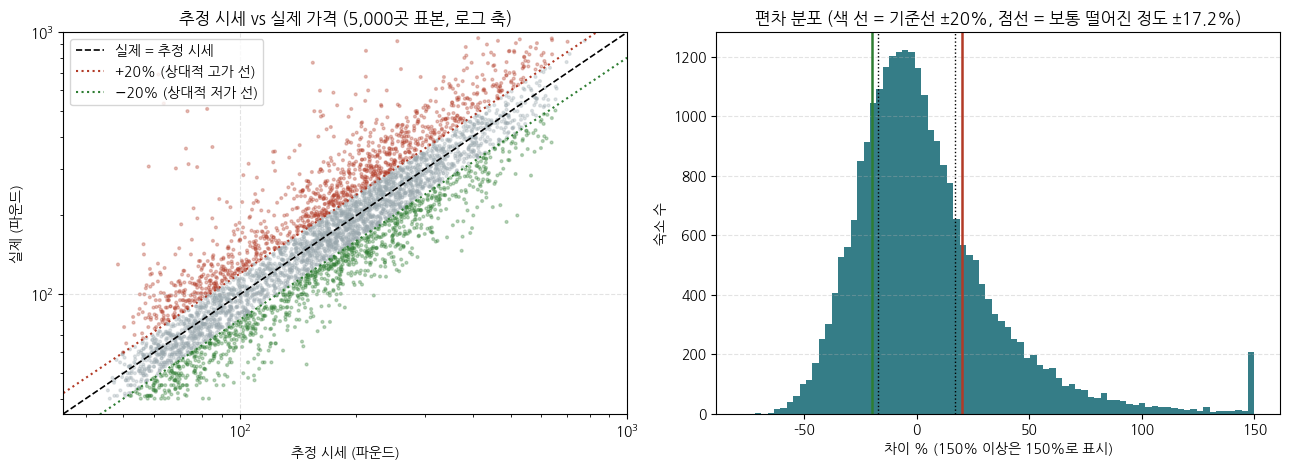

,숙소수,실제_중앙값_파운드,추정시세_중앙값_파운드,편차_중앙값_퍼센트,보통_오차_MedAPE,상대적 저가 %,시세 수준 %,상대적 고가 %
유형,,,,,,,,
집 전체 1~2명,4631,160.0,163.0,-2.0,17.9,21.7,56.0,22.3
집 전체 3~4명,6491,218.3,218.8,-0.8,17.2,19.7,56.8,23.5
집 전체 5~6명,4038,283.0,282.5,-1.1,17.3,20.0,57.3,22.8
집 전체 7명 이상,1844,356.7,352.3,-1.2,18.5,20.9,54.2,24.9
개인실 1~2명,7360,78.0,79.8,-2.6,17.2,20.7,57.6,21.7
개인실 3명 이상,1243,104.0,103.3,-0.7,20.6,21.2,50.0,28.7


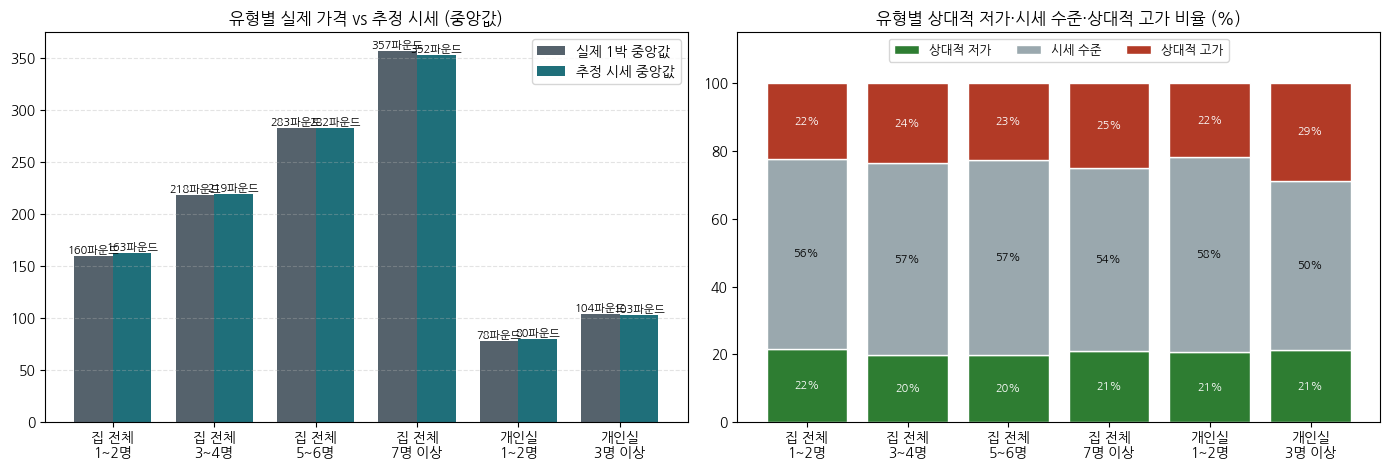

In [ ]:
# [Step 6] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 6-1. 추정 시세와 편차
# ====================================================================================================
# [6-1] 최종 모델(랜덤포레스트) OOF (겹 밖 예측) 예측 → 추정 시세(파운드), 차이 계산

oof_pred_final = oof_rf                                     # 최종 모델: 랜덤포레스트 5겹 OOF 예측 (log 가격)
diag = df[["id", "neighbourhood_cleansed", "room_type", "accommodates", "price_gbp", "quote_nights",
           "estimated_occupancy_l365d", "number_of_reviews_ltm",
           "review_scores_value", "review_scores_rating", "host_is_superhost"]].copy()
diag["pred_price"] = np.exp(oof_pred_final)                 # 추정 시세 = 자기 가격을 보지 않은 모델의 예측
diag["gap"] = diag["price_gbp"] / diag["pred_price"] - 1     # 편차
diag["est_revenue"] = diag["price_gbp"] * diag["estimated_occupancy_l365d"]   # 1년 추정 수익 = 1박 가격 × 추정 예약일
diag["superhost"] = (diag["host_is_superhost"] == "t").astype(int)

print(f"추정 시세 중앙값 {diag['pred_price'].median():.0f}파운드 | 실제 가격 중앙값 {diag['price_gbp'].median():.0f}파운드")
q = diag["gap"].quantile([0.10, 0.25, 0.50, 0.75, 0.90])
print("편차 분위수: " + " | ".join(f"{int(k * 100)}%: {v:+.1%}" for k, v in q.items()))
ex_idx = [(diag["gap"] - diag["gap"].quantile(p)).abs().idxmin() for p in [0.05, 0.25, 0.50, 0.75, 0.95]]
example = diag.loc[ex_idx, ["neighbourhood_cleansed", "room_type", "accommodates", "price_gbp", "pred_price", "gap"]].copy()
example.index = ["하위 5%", "하위 25%", "중앙", "상위 25%", "상위 5%"]
example["pred_price"] = example["pred_price"].round(0)
example["gap"] = (example["gap"] * 100).round(1)
display(example.rename(columns={"neighbourhood_cleansed": "자치구", "room_type": "숙소 유형", "accommodates": "수용 인원",
                                "price_gbp": "실제 (파운드)", "pred_price": "추정 시세 (파운드)", "gap": "차이 %"}))

# ====================================================================================================
# 6-2. 편차 분포와 기준선
# ====================================================================================================
# [6-2] 편차 값으로 기준선 정하기: 보통 떨어진 정도(|편차| 중앙값) → 이를 넘는 첫 5% 단위, 후보 기준선별 집단 수, 유형별 비율, 그래프

abs_gap = diag["gap"].abs()
typical_gap = abs_gap.median()                                        # 숙소가 추정 시세에서 보통 떨어진 정도
THRESHOLD = round(float(np.ceil(typical_gap / 0.05) * 0.05), 2)       # 편차 기준선 = 보통 범위를 넘는 첫 5% 단위
print(f"숙소가 추정 시세에서 보통 떨어진 정도 (|편차| 중앙값): {typical_gap:.1%} → 이를 넘는 첫 5% 단위 = 편차 기준선 ±{THRESHOLD:.0%}")
print(f"편차 ±{THRESHOLD:.0%} 안 숙소: {(abs_gap < THRESHOLD).mean():.1%}")

order = ["상대적 저가", "시세 수준", "상대적 고가"]
th_rows = []
for t in [round(THRESHOLD - 0.10, 2), THRESHOLD, round(THRESHOLD + 0.10, 2)]:      # 정한 기준선과 10%p 좁은·넓은 기준선 비교
    g = pd.Series(classify(diag["gap"].values, t))
    th_rows.append({"기준": f"±{t:.0%}", **{k: int((g == k).sum()) for k in order},
                    **{f"{k} %": round((g == k).mean() * 100, 1) for k in order}})
display(pd.DataFrame(th_rows).set_index("기준"))

diag["group"] = classify(diag["gap"].values, THRESHOLD)
print("숙소 유형별 집단 비율 (%)")
display((pd.crosstab(diag["room_type"].map(TYPE_KR), diag["group"], normalize="index")[order] * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
s_idx = np.random.RandomState(RANDOM_STATE).choice(len(diag), 5000, replace=False)
axes[0].scatter(diag["pred_price"].values[s_idx], diag["price_gbp"].values[s_idx], s=4, alpha=0.3,
                c=[COLORS[g] for g in diag["group"].values[s_idx]])
lims = np.array([35, 1000])
axes[0].plot(lims, lims, color="black", linestyle="--", linewidth=1.2, label="실제 = 추정 시세")
axes[0].plot(lims, lims * (1 + THRESHOLD), color=COLORS["상대적 고가"], linestyle=":", linewidth=1.5, label=f"+{THRESHOLD:.0%} (상대적 고가 선)")
axes[0].plot(lims, lims * (1 - THRESHOLD), color=COLORS["상대적 저가"], linestyle=":", linewidth=1.5, label=f"−{THRESHOLD:.0%} (상대적 저가 선)")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_title("추정 시세 vs 실제 가격 (5,000곳 표본, 로그 축)")
axes[0].set_xlabel("추정 시세 (파운드)"); axes[0].set_ylabel("실제 (파운드)")
axes[0].legend(loc="upper left"); axes[0].grid(linestyle="--", alpha=0.35)
axes[1].hist(diag["gap"].clip(-0.8, 1.5) * 100, bins=80, color="#1F6F7A", alpha=0.9)
for v, c in [(-THRESHOLD * 100, COLORS["상대적 저가"]), (THRESHOLD * 100, COLORS["상대적 고가"])]:
    axes[1].axvline(v, color=c, linewidth=1.8)
axes[1].axvline(typical_gap * 100, color="black", linestyle=":", linewidth=1); axes[1].axvline(-typical_gap * 100, color="black", linestyle=":", linewidth=1)
axes[1].set_title(f"편차 분포 (색 선 = 기준선 ±{THRESHOLD:.0%}, 점선 = 보통 떨어진 정도 ±{typical_gap:.1%})")
axes[1].set_xlabel("차이 % (150% 이상은 150%로 표시)"); axes[1].set_ylabel("숙소 수")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# ====================================================================================================
# 6-3. 비슷한 유형별 가격 비교 분석
# ====================================================================================================
# [6-3] 비슷한 유형별 가격 비교 분석
# 모델은 전역 하나, 분석만 유형별로 나눈다 (유형별로 모델을 따로 만들면 학습 데이터가 줄어 추정 시세가 불안정해진다)

# 1) 실제·예측 가격을 파운드로
actual_gbp = np.exp(y.values)                       # = price_gbp
pred_gbp = np.exp(oof_pred_final)                   # = 추정 시세

# 2) 편차: 실제가 추정 시세보다 몇 % 비싼가(+) 싼가(−)
dev_pct = (actual_gbp / pred_gbp - 1) * 100

# 3) 유형별 표: 숙소 유형 × 수용 인원 구간 (개인실 3명 이상은 숙소가 적어 하나로 묶음)
size_band = np.where(df["room_type"] == "Private room",
                     np.where(df["accommodates"] <= 2, "1~2명", "3명 이상"),
                     pd.cut(df["accommodates"], [0, 2, 4, 6, 100], labels=["1~2명", "3~4명", "5~6명", "7명 이상"]).astype(str))
type_label = df["room_type"].map(TYPE_KR) + " " + size_band
type_order = ["집 전체 1~2명", "집 전체 3~4명", "집 전체 5~6명", "집 전체 7명 이상", "개인실 1~2명", "개인실 3명 이상"]
tdf = pd.DataFrame({"유형": type_label, "실제": actual_gbp, "예측": pred_gbp, "편차": dev_pct,
                    "오차": np.abs(pred_gbp / actual_gbp - 1) * 100, "group": diag["group"].values})
type_table = tdf.groupby("유형").agg(숙소수=("실제", "size"), 실제_중앙값_파운드=("실제", "median"), 추정시세_중앙값_파운드=("예측", "median"),
                                    편차_중앙값_퍼센트=("편차", "median"), 보통_오차_MedAPE=("오차", "median")).reindex(type_order)
for g in order:
    type_table[f"{g} %"] = (tdf.assign(v=tdf["group"] == g).groupby("유형")["v"].mean() * 100).reindex(type_order)
display(type_table.round(1))

# 4) 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
pos = np.arange(len(type_order)); w = 0.38
axes[0].bar(pos - w / 2, type_table["실제_중앙값_파운드"], width=w, color="#55626C", label="실제 1박 중앙값")
axes[0].bar(pos + w / 2, type_table["추정시세_중앙값_파운드"], width=w, color="#1F6F7A", label="추정 시세 중앙값")
for x, v in zip(np.r_[pos - w / 2, pos + w / 2], np.r_[type_table["실제_중앙값_파운드"], type_table["추정시세_중앙값_파운드"]]):
    axes[0].text(x, v, f"{v:.0f}파운드", ha="center", va="bottom", fontsize=8)
tick_lab = [t.replace("집 전체 ", "집 전체\n").replace("개인실 ", "개인실\n") for t in type_order]
axes[0].set_xticks(pos); axes[0].set_xticklabels(tick_lab)
axes[0].set_title("유형별 실제 가격 vs 추정 시세 (중앙값)"); axes[0].legend(); axes[0].grid(axis="y", linestyle="--", alpha=0.35)
bottom = np.zeros(len(type_order))
for g in order:
    vals = type_table[f"{g} %"].values
    axes[1].bar(pos, vals, bottom=bottom, color=COLORS[g], label=g, edgecolor="white", linewidth=1)
    for x, b, v in zip(pos, bottom, vals):
        axes[1].text(x, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if g != "시세 수준" else "black")
    bottom += vals
axes[1].set_xticks(pos); axes[1].set_xticklabels(tick_lab)
axes[1].set_title("유형별 상대적 저가·시세 수준·상대적 고가 비율 (%)"); axes[1].legend(loc="upper center", ncol=3, fontsize=9)
axes[1].set_ylim(0, 115)
plt.tight_layout()
plt.show()

### Step 6 종합 분석
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 추정 시세 | 중앙값 173파운드 (실제 169파운드), 편차 중앙값 −1.7% | 한쪽으로 치우치지 않은 기준이다 |
| 편차 기준선 | 보통 편차 17.2% → 이를 넘는 첫 5% 단위 ±20% | 보통 범위를 넘어 크게 벗어난 숙소만 상대적 고가·저가로 본다 |
| 분류 | 상대적 저가 5,260 / 시세 수준 14,450 / 상대적 고가 5,897 | 숙소 넷 중 하나 정도가 상대적 고가 |
| 유형별 | 모든 유형에서 실제·추정 시세 중앙값 차이 3% 안 | 모델은 전역, 분석은 유형별로 하는 방식이 작동한다 |

**의견**: 추정 시세는 유형마다 고르게 맞고, 상대적 고가는 유형과 관계없이 약 23%다. 이제 질문은 '시세를 벗어난 숙소들이 같은 조건 시세 수준 숙소보다 덜 버는가'다.

**다음 질문**: 상대적 고가는 1박에 더 받는 대신 예약이 줄고, 상대적 저가는 예약이 느는 대신 1박에 덜 받는다. 그 결과 같은 조건 시세 수준 숙소보다 1년 수익이 낮을까? → Step 7 (가설 1-1·1-2)

---
## Step 7. 가설 : 가격 편차가 큰 숙소는 수익이 낮은가
**문제 제기**: 상대적 고가는 1박에 더 받는 대신 예약이 줄 것이고(가설 1-1), 상대적 저가는 예약이 느는 대신 1박에 덜 받는다(가설 1-2). 그 결과 같은 조건에서 시세 수준의 가격을 받는 숙소보다 1년 추정 수익이 낮을까?

**방법**
- 같은 조건 묶음(자치구 × 숙소 유형 × 수용 인원) 안에서만 비교한다. 시세 수준 숙소가 10곳 이상인 묶음만 쓴다. 시세 수준 숙소의 수익 중앙값이 0인 묶음은 수익 비율을 계산할 수 없어 뺀다.
- **수익 비율** = 숙소의 1년 추정 수익 ÷ 같은 묶음 시세 수준 숙소의 수익 중앙값. 1박 가격과 예약일도 같은 방식으로 배수를 낸다(1 = 시세 수준과 같음).
- 차이가 우연인지는 **층화 Mann-Whitney 검정**(묶음 안에서만 순위를 비교해 합침), 크기는 **효과 크기 r**로 보고, 서두의 판정 기준으로 판정한다(7-4).

**읽을 때 주의**: 수익 = 1박 가격 × 추정 예약일이라 가격이 수익 안에 들어 있다. 추정 예약일은 리뷰 수로 추정했고 255일에서 잘린다(20.7%).

시세 수준 숙소 10곳 이상 묶음 243개 중 수익 중앙값이 0인 묶음 1개(15곳) 제외: ['Sutton|Private room|1']
비교 묶음 242개, 숙소 23,675곳 (전체의 92.5%)


,숙소 수,1박 가격 배수,추정 예약일 중앙값,추정 예약일 배수,수익 비율 중앙값,예약 0일 %
group,,,,,,
상대적 저가,4828,0.740,138.0,1.154,0.848,6.089
시세 수준,13497,1.000,120.0,1.000,1.000,6.572
상대적 고가,5350,1.486,83.0,0.692,1.041,11.963


,비교,지표,Z,p-value,효과 크기 r
0,상대적 고가 vs 시세 수준,1박 가격,77.57,0.0e+00,0.565
1,상대적 고가 vs 시세 수준,추정 예약일,-19.83,1.5e-87,-0.145
2,상대적 고가 vs 시세 수준,1년 추정 수익,5.27,1.3e-07,0.038
3,상대적 저가 vs 시세 수준,1박 가격,-64.07,0.0e+00,-0.474
4,상대적 저가 vs 시세 수준,추정 예약일,9.87,5.5e-23,0.073
5,상대적 저가 vs 시세 수준,1년 추정 수익,-13.08,4.5e-39,-0.097


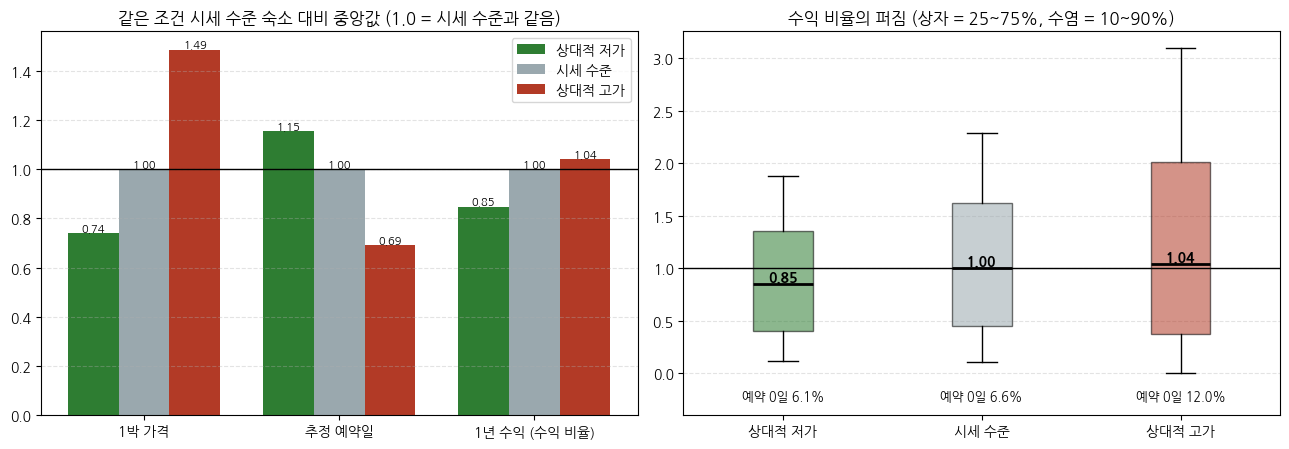

숙소 수  1박 가격 배수  예약일 배수  수익 비율  예약 0일 %  예약 0일 % (시세 수준)  수익 효과 크기 r 수익 p-value
숙소 유형 집단                                                                                    
전체    상대적 고가  5350     1.486   0.692  1.041   11.963            6.572       0.038    1.3e-07
      상대적 저가  4828     0.740   1.154  0.848    6.089            6.572      -0.097    4.5e-39
집 전체  상대적 고가  3594     1.464   0.767  1.106    9.794            5.657       0.067    6.9e-14
      상대적 저가  3177     0.730   1.165  0.826    5.319            5.657      -0.104    4.2e-30
개인실   상대적 고가  1756     1.519   0.545  0.889   16.401            8.339      -0.019    1.4e-01
      상대적 저가  1651     0.754   1.154  0.884    7.571            8.339      -0.083    6.1e-11

가설 방향  배수 (시세 수준 = 1)  효과 크기 r  p-value                      판정
가설     숙소 유형 지표                                                                                   
가설 1-1 전체    1년 추정 수익         시세 수준보다 낮음           1.041    0.038  1.3e-07                      기각
       집 전체  1년 추정 수익         시세 수준보다 낮음           1.106    0.067  6.9e-14                      기각
       개인실   1년 추정 수익         시세 수준보다 낮음           0.889   -0.019  1.4e-01                      기각
가설 1-2 전체    추정 예약일 (많은 예약일)  시세 수준보다 많음           1.154    0.073  5.5e-23  부분 채택 (방향은 맞지만 차이가 작음)
             1년 추정 수익         시세 수준보다 낮음           0.848   -0.097  4.5e-39  부분 채택 (방향은 맞지만 차이가 작음)
       집 전체  추정 예약일 (많은 예약일)  시세 수준보다 많음           1.165    0.070  2.3e-14  부분 채택 (방향은 맞지만 차이가 작음)
             1년 추정 수익         시세 수준보다 낮음           0.826   -0.104  4.2e-30                      채택
       개인실   추정 예약일 (많은 예약일)  시세 수준보다 많음           1.154    0.080  2.9e-10  부분 채택 (방향은 맞지만 차이가 작음)
             1년 추정 수익         시세 수준보다 낮음           0.884   -0.083  6.1e-11  부분 채택 (방향은 맞지만 차이가 작음)

In [ ]:
# [Step 7] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 7-1. 같은 조건 묶음 안 비교
# ====================================================================================================
# [7-1] 같은 조건 묶음 안에서 시세 수준 숙소 대비 1박 가격·예약일 배수와 수익 비율, 층화 Mann-Whitney (맨-휘트니 검정)

diag["cell"] = diag["neighbourhood_cleansed"] + "|" + diag["room_type"] + "|" + diag["accommodates"].astype(str)
n_fair = diag[diag["group"] == "시세 수준"].groupby("cell").size()
comp = diag[diag["cell"].isin(n_fair[n_fair >= MIN_FAIR_IN_CELL].index)].copy()      # 시세 수준 숙소 10곳 이상 묶음
base = comp[comp["group"] == "시세 수준"].groupby("cell").agg(fair_med_price=("price_gbp", "median"),
                                                       fair_med_occ=("estimated_occupancy_l365d", "median"),
                                                       fair_med_rev=("est_revenue", "median"))
zero_cells = base.index[base["fair_med_rev"] == 0]                                   # 수익 중앙값 0 → 수익 비율 계산 불가
print(f"시세 수준 숙소 10곳 이상 묶음 {len(base)}개 중 수익 중앙값이 0인 묶음 {len(zero_cells)}개"
      f"({int(comp['cell'].isin(zero_cells).sum())}곳) 제외: {list(zero_cells)}")
comp = comp[~comp["cell"].isin(zero_cells)].join(base, on="cell")
comp["rel_price"] = comp["price_gbp"] / comp["fair_med_price"]                      # 1박 가격 배수
comp["rel_occ"] = comp["estimated_occupancy_l365d"] / comp["fair_med_occ"].replace(0, np.nan)   # 예약일 배수
comp["rev_ratio"] = comp["est_revenue"] / comp["fair_med_rev"]                       # 수익 비율 (1 = 같음)
print(f"비교 묶음 {comp['cell'].nunique()}개, 숙소 {len(comp):,}곳 (전체의 {len(comp) / len(diag):.1%})")

summary = comp.groupby("group").agg(**{
    "숙소 수": ("id", "size"),
    "1박 가격 배수": ("rel_price", "median"),
    "추정 예약일 중앙값": ("estimated_occupancy_l365d", "median"),
    "추정 예약일 배수": ("rel_occ", "median"),
    "수익 비율 중앙값": ("rev_ratio", "median"),
    "예약 0일 %": ("estimated_occupancy_l365d", lambda s: (s == 0).mean() * 100),
}).loc[order]
display(summary.round(3))

def stratified_mw(data, col, a, b="시세 수준"):
    """같은 묶음 안에서만 a와 b를 비교하는 층화 Mann-Whitney(van Elteren). Z > 0이면 a가 큼, 효과 크기 r = Z/√N"""
    T = E = V = 0.0
    N = 0
    for _, g in data.groupby("cell"):
        x = g.loc[g["group"] == a, col].values
        z = g.loc[g["group"] == b, col].values
        n1, n2 = len(x), len(z)
        if n1 == 0 or n2 == 0:
            continue
        v = np.concatenate([x, z]); n = n1 + n2
        rk = stats.rankdata(v)
        _, cnt = np.unique(v, return_counts=True)
        var = n1 * n2 / 12 * ((n + 1) - (cnt ** 3 - cnt).sum() / (n * (n - 1)))
        wgt = 1 / (n + 1)
        T += wgt * rk[:n1].sum(); E += wgt * n1 * (n + 1) / 2; V += wgt * wgt * var; N += n
    Z = (T - E) / np.sqrt(V)
    return Z, 2 * stats.norm.sf(abs(Z)), Z / np.sqrt(N)

test_rows = []
for a in ["상대적 고가", "상대적 저가"]:
    for col, nm in [("price_gbp", "1박 가격"), ("estimated_occupancy_l365d", "추정 예약일"), ("est_revenue", "1년 추정 수익")]:
        Z, p, r = stratified_mw(comp, col, a)
        test_rows.append({"비교": f"{a} vs 시세 수준", "지표": nm, "Z": round(Z, 2), "p-value": f"{p:.1e}", "효과 크기 r": round(r, 3)})
display(pd.DataFrame(test_rows))

# ====================================================================================================
# 7-2. 비교 그래프
# ====================================================================================================
# [7-2] 같은 조건 시세 수준 숙소 대비 중앙값 배수, 집단별 수익 비율의 퍼짐

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
cols = ["1박 가격 배수", "추정 예약일 배수", "수익 비율 중앙값"]
pos = np.arange(3); w = 0.26
for i, g in enumerate(order):
    vals = summary.loc[g, cols].values.astype(float)
    axes[0].bar(pos + (i - 1) * w, vals, width=w, color=COLORS[g], label=g)
    for x, v in zip(pos + (i - 1) * w, vals):
        axes[0].text(x, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
axes[0].axhline(1, color="black", linewidth=1)
axes[0].set_xticks(pos); axes[0].set_xticklabels(["1박 가격", "추정 예약일", "1년 수익 (수익 비율)"])
axes[0].set_title("같은 조건 시세 수준 숙소 대비 중앙값 (1.0 = 시세 수준과 같음)"); axes[0].legend(); axes[0].grid(axis="y", linestyle="--", alpha=0.35)
rel_vals = [comp.loc[comp["group"] == g, "rev_ratio"].clip(upper=4) for g in order]
bp = axes[1].boxplot(rel_vals, showfliers=False, patch_artist=True, whis=(10, 90), medianprops=dict(color="black", linewidth=2))
for patch, g in zip(bp["boxes"], order):
    patch.set_facecolor(COLORS[g]); patch.set_alpha(0.55)
for i, (v, g) in enumerate(zip(rel_vals, order), 1):
    axes[1].text(i, v.median(), f"{v.median():.2f}", ha="center", va="bottom", fontweight="bold")
    axes[1].text(i, -0.25, f"예약 0일 {summary.loc[g, '예약 0일 %']:.1f}%", ha="center", fontsize=9)
axes[1].axhline(1, color="black", linewidth=1)
axes[1].set_ylim(-0.4, None)
axes[1].set_xticks([1, 2, 3]); axes[1].set_xticklabels(order)
axes[1].set_title("수익 비율의 퍼짐 (상자 = 25~75%, 수염 = 10~90%)"); axes[1].grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# ====================================================================================================
# 7-3. 숙소 유형별로 나눠 보기
# ====================================================================================================
# [7-3] 같은 조건 비교를 집 전체 / 개인실로 나눠 다시 계산 (모델은 그대로, 분석만 유형별)

def same_cell_compare(groups, mask=None, occ=None, min_fair=MIN_FAIR_IN_CELL):
    """집단 배정(groups)으로 같은 조건 비교를 다시 계산해 상대적 고가·저가의 결과를 돌려준다.
    mask: 일부 숙소만 쓸 때, occ: 예약일을 바꿔 수익을 다시 계산할 때,
    min_fair: 비교 묶음을 쓰는 기준(시세 수준 숙소 최소 수)을 바꿀 때"""
    d = diag[["cell", "price_gbp", "estimated_occupancy_l365d", "est_revenue"]].copy()
    d["group"] = groups
    if occ is not None:
        d["estimated_occupancy_l365d"] = occ
        d["est_revenue"] = d["price_gbp"] * occ
    if mask is not None:
        d = d[mask]
    n_f = d[d["group"] == "시세 수준"].groupby("cell").size()
    d = d[d["cell"].isin(n_f[n_f >= min_fair].index)]
    cols = ["price_gbp", "estimated_occupancy_l365d", "est_revenue"]
    med = d[d["group"] == "시세 수준"].groupby("cell")[cols].median()
    d = d[d["cell"].map(med["est_revenue"]) > 0]                                     # 수익 중앙값 0인 묶음 제외
    rel = d[cols].values / med.loc[d["cell"]].replace(0, np.nan).values
    res = {}
    for g in ["상대적 고가", "상대적 저가"]:
        m = (d["group"] == g).values
        _, p, r = stratified_mw(d, "est_revenue", g)
        _, p_o, r_o = stratified_mw(d, "estimated_occupancy_l365d", g)
        res[g] = {"숙소 수": int(m.sum()), "1박 가격 배수": np.nanmedian(rel[m, 0]), "예약일 배수": np.nanmedian(rel[m, 1]),
                  "수익 비율": np.nanmedian(rel[m, 2]), "수익 비율 1 미만 %": (rel[m, 2] < 1).mean() * 100,
                  "예약 0일 %": (d.loc[m, "estimated_occupancy_l365d"] == 0).mean() * 100,
                  "수익 r": r, "수익 p": p, "예약일 r": r_o, "예약일 p": p_o}
    fair = (d["group"] == "시세 수준").values
    res["시세 수준"] = {"숙소 수": int(fair.sum()), "수익 비율 1 미만 %": (rel[fair, 2] < 1).mean() * 100,
                     "예약 0일 %": (d.loc[fair, "estimated_occupancy_l365d"] == 0).mean() * 100}
    res["묶음 수"] = d["cell"].nunique()                                               # 비교에 쓴 묶음 수
    return res

type_rows = []
for label_t, mk in [("전체", None)] + [(lab, (diag["room_type"] == rt).values) for rt, lab in TYPE_KR.items()]:
    res = same_cell_compare(diag["group"].values, mk)
    for g in ["상대적 고가", "상대적 저가"]:
        v = res[g]
        type_rows.append({"숙소 유형": label_t, "집단": g, "숙소 수": v["숙소 수"], "1박 가격 배수": v["1박 가격 배수"],
                          "예약일 배수": v["예약일 배수"], "수익 비율": v["수익 비율"], "예약 0일 %": v["예약 0일 %"],
                          "예약 0일 % (시세 수준)": res["시세 수준"]["예약 0일 %"], "수익 효과 크기 r": v["수익 r"],
                          "수익 p-value": f"{v['수익 p']:.1e}"})
type_core = pd.DataFrame(type_rows).set_index(["숙소 유형", "집단"])
display(type_core.round(3))

# ====================================================================================================
# 7-4. 가설 판정
# ====================================================================================================
# [7-4] 서두의 판정 기준 적용: 방향이 가설과 같고 p < 0.05 → |r| ≥ 0.1이면 채택, 작으면 부분 채택 / 방향 반대·p ≥ 0.05면 기각

def verdict(r, p, expected_sign):
    if p >= 0.05 or np.sign(r) != expected_sign:
        return "기각"
    return "채택" if abs(r) >= 0.1 else "부분 채택 (방향은 맞지만 차이가 작음)"

judge_rows = []
for hyp, g, items in [("가설 1-1", "상대적 고가", [("1년 추정 수익", "수익", -1)]),
                      ("가설 1-2", "상대적 저가", [("추정 예약일 (많은 예약일)", "예약일", +1), ("1년 추정 수익", "수익", -1)])]:
    for label_t, mk in [("전체", None)] + [(lab, (diag["room_type"] == rt).values) for rt, lab in TYPE_KR.items()]:
        v = same_cell_compare(diag["group"].values, mk)[g]
        for item, key, sign in items:
            ratio = v["수익 비율"] if key == "수익" else v["예약일 배수"]
            judge_rows.append({"가설": hyp, "숙소 유형": label_t, "지표": item, "가설 방향": "시세 수준보다 낮음" if sign < 0 else "시세 수준보다 많음",
                               "배수 (시세 수준 = 1)": round(ratio, 3), "효과 크기 r": round(v[f"{key} r"], 3),
                               "p-value": f"{v[f'{key} p']:.1e}", "판정": verdict(v[f"{key} r"], v[f"{key} p"], sign)})
judge = pd.DataFrame(judge_rows).set_index(["가설", "숙소 유형", "지표"])
display(judge)

### Step 7 실행 결과와 해석

#### 7-1. 같은 조건 묶음 안 비교

**결과**
- 시세 수준 숙소 10곳 이상 묶음 중, 시세 수준 숙소의 수익 중앙값이 0인 1개(Sutton 개인실 1인)는 수익 비율을 계산할 수 없어 뺐다. 비교 묶음 **242개, 23,675곳**(전체의 92.5%).

| 같은 조건 시세 수준 숙소 대비 (중앙값) | 상대적 저가 | 시세 수준 | 상대적 고가 |
| --- | --- | --- | --- |
| 숙소 수 | 4,828 | 13,497 | 5,350 |
| 1박 가격 | 0.74배 | 1 | 1.49배 |
| 추정 예약일 | **1.15배** (138일) | 1 (120일) | 0.69배 (83일) |
| **수익 비율** | **0.85** | 1 | **1.04** |
| 예약 0일 비율 | 6.1% | 6.6% | 12.0% |

| 층화 Mann-Whitney (시세 수준과 비교, 모두 p < 0.001) | 상대적 고가: 효과 크기 r | 상대적 저가: 효과 크기 r |
| --- | --- | --- |
| 1박 가격 | +0.565 | −0.474 |
| 추정 예약일 | −0.145 | +0.073 |
| 1년 추정 수익 | **+0.038** | **−0.097** |

**해석**
- **상대적 고가 (가설 1-1)**: 1박 가격 1.49배 × 예약일 0.69배가 거의 상쇄되어 수익 비율이 **1.04**다. 시세 수준 숙소보다 수익이 낮지 않다. 효과 크기 r = +0.038도 가설과 반대 방향이다.
- **상대적 저가 (가설 1-2)**: 예약일은 시세 수준보다 **1.15배 많은데** 1박 가격이 0.74배라 수익 비율이 **0.85**다. '많은 예약일에도 불구하고 수익이 낮다'가 그대로 나타난다. 다만 크기는 r = −0.097로 작다.
- p-value는 모두 0.001보다 작다. 숙소가 2만 곳이 넘으면 작은 차이도 이렇게 나오므로, 판정은 효과 크기 r로 한다(7-4).
- 예약 0일은 상대적 고가가 12.0%로 시세 수준(6.6%)의 1.8배다.

#### 7-2. 비교 그래프

**결과**: 왼쪽 그림에서 상대적 고가는 1박 가격 막대(1.49)가 높고 예약일 막대(0.69)가 낮아, 수익 막대(1.04)가 1.0 근처로 돌아온다. 상대적 저가는 반대로 1박 가격 0.74, 예약일 1.15이고 수익 막대가 0.85로 1.0보다 낮다. 오른쪽 그림의 수익 비율 상자(25~75%)는 상대적 고가 0.37 ~ 2.02, 시세 수준 0.45 ~ 1.62, 상대적 저가 0.40 ~ 1.36이다. 상대적 고가의 10% 지점은 0.00이다.

**해석**: 상대적 고가는 가운데(중앙값)는 시세 수준과 같지만 **위아래로 가장 넓게 퍼져 있다**. 비싸게 받고도 잘 버는 숙소와 거의 못 버는 숙소가 함께 있다. 상대적 저가는 상자 전체가 아래로 내려와 있다.

#### 7-3. 숙소 유형별로 나눠 보기

**결과**

| 숙소 유형 | 집단 | 숙소 수 | 1박 가격 | 예약일 | 수익 비율 | 예약 0일 (시세 수준) | 수익 효과 크기 r |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 전체 | 상대적 고가 | 5,350 | 1.49배 | 0.69배 | 1.04 | 12.0% (6.6%) | +0.038 |
| 전체 | 상대적 저가 | 4,828 | 0.74배 | 1.15배 | 0.85 | 6.1% (6.6%) | −0.097 |
| 집 전체 | 상대적 고가 | 3,594 | 1.46배 | 0.77배 | 1.11 | 9.8% (5.7%) | +0.067 |
| 집 전체 | 상대적 저가 | 3,177 | 0.73배 | 1.16배 | 0.83 | 5.3% (5.7%) | −0.104 |
| 개인실 | 상대적 고가 | 1,756 | 1.52배 | 0.55배 | 0.89 | 16.4% (8.3%) | −0.019 (p = 1.4e-01) |
| 개인실 | 상대적 저가 | 1,651 | 0.75배 | 1.15배 | 0.88 | 7.6% (8.3%) | −0.083 |

**해석**
- **집 전체**: 비싸게 받아도 예약이 23%만 줄어 수익이 11% 많다. 싸게 받으면 예약이 16% 늘지만 수익은 17% 적다.
- **개인실**: 비싸게 받으면 예약이 45%나 줄고 예약 0일이 16.4%로 시세 수준의 약 2배다. 수익 비율은 0.89지만 p = 1.4e-01이라 우연과 구별되지 않는다. **'개인실에서 비싸게 받으면 예약이 끊길 위험이 크다'**고 읽어야 한다.
- 상대적 저가는 두 유형 모두 수익 비율이 1보다 낮다. 가설 1-2의 방향은 유형과 관계없이 같다.

#### 7-4. 가설 판정

**결과**: 서두의 판정 기준(방향 · p < 0.05 · |r| ≥ 0.1)을 `verdict` 함수로 적용했다.

| 가설 | 범위 | 지표 | 배수 (시세 수준 = 1) | 효과 크기 r | 판정 |
| --- | --- | --- | --- | --- | --- |
| 가설 1-1 | 전체 | 1년 추정 수익 | 1.041 | +0.038 | 기각 |
| 가설 1-1 | 집 전체 | 1년 추정 수익 | 1.106 | +0.067 | 기각 |
| 가설 1-1 | 개인실 | 1년 추정 수익 | 0.889 | −0.019 | 기각 |
| 가설 1-2 | 전체 | 추정 예약일 (많은 예약일) | 1.154 | +0.073 | 부분 채택 (방향은 맞지만 차이가 작음) |
| 가설 1-2 | 전체 | 1년 추정 수익 | 0.848 | −0.097 | 부분 채택 (방향은 맞지만 차이가 작음) |
| 가설 1-2 | 집 전체 | 추정 예약일 (많은 예약일) | 1.165 | +0.070 | 부분 채택 (방향은 맞지만 차이가 작음) |
| 가설 1-2 | 집 전체 | 1년 추정 수익 | 0.826 | −0.104 | 채택 |
| 가설 1-2 | 개인실 | 추정 예약일 (많은 예약일) | 1.154 | +0.080 | 부분 채택 (방향은 맞지만 차이가 작음) |
| 가설 1-2 | 개인실 | 1년 추정 수익 | 0.884 | −0.083 | 부분 채택 (방향은 맞지만 차이가 작음) |

**해석**
- **가설 1-1은 기각한다.** 상대적 고가는 높은 숙박 단가 때문에 예약은 줄지만, 수익은 같은 조건 시세 수준 숙소보다 낮지 않다.
- **가설 1-2는 부분 채택한다.** '예약일은 더 많다'와 '수익은 더 낮다'가 모두 맞고 우연도 아니다. 하지만 차이의 크기가 '작음' 기준(0.1)에 조금 못 미친다. 집 전체만 보면 채택이다.

### Step 7 종합 분석 (가설 1-1·1-2)
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 가설 1-1 (상대적 고가) | 1박 1.49배 × 예약일 0.69배 → 수익 비율 1.04, r = +0.038 | **기각**: 비싸게 받는 만큼 예약이 줄어 수익은 시세 수준과 같다 |
| 가설 1-2 (상대적 저가) | 예약일 1.15배, 1박 0.74배 → 수익 비율 0.85, r = −0.097 | **부분 채택**: 많이 팔지만 싸게 팔아 덜 번다. 차이는 작다 |
| 숨은 차이 | 상대적 고가 예약 0일 12.0% (시세 수준 6.6%) | 중앙값 뒤에 '거의 못 버는 숙소'가 섞여 있다 |
| 유형별 | 집 전체 고가 1.11 / 저가 0.83, 개인실 고가 예약 0일 16.4% | 집 전체는 싸게 받는 쪽이, 개인실은 비싸게 받는 쪽이 더 위험하다 |

**의견**: 시세에서 벗어나는 방향에 따라 결과가 다르다. 비싸게 받는 것은 집단으로는 손해가 아니지만, 싸게 받는 것은 집단으로 손해다. 다만 두 집단 모두 안에서 결과가 크게 갈린다. 그래서 질문을 개별 숙소로 옮겨야 한다.

**다음 질문**: 같은 조건 시세와의 가격 편차가 크고, 1년 추정 수익이 시세 수준 숙소보다 낮은 숙소는 어떤 숙소인가? → Step 8 (핵심 질문)

---
## Step 8. 핵심 질문: 같은 조건 시세와의 가격 편차가 크고, 1년 추정 수익이 시세 수준 숙소보다 낮은 숙소는 어떤 숙소인가?
**문제 제기**: Step 7은 집단의 중앙값을 비교했다. 이제 숙소 하나하나를 본다. 시세에서 편차가 기준선(6-2)을 넘어 벗어난 숙소(상대적 고가·저가) 중 수익 비율이 1 미만인 곳은 몇 곳이고, 같은 가격 집단 안에서 수익이 같거나 높은 숙소와 무엇이 다른가?

**방법**
- 대상: 비교 묶음 안의 상대적 고가·상대적 저가.
- **수익 낮음** = 수익 비율 1 미만. 시세 수준 숙소의 중앙값과 비교하므로 시세 수준 숙소도 약 절반은 1 미만이다. 그래서 이 비율을 **기준선**으로 놓고 비교한다.
- 기준선과의 차이가 통계적으로 의미 있는지(카이제곱 검정 + Cramér's V)는 이 모델링 노트북에서 하지 않고, **다음 검정 단계에서 검정 담당이 진행한다.** 여기서는 비율과 차이(%p)만 보여 준다.
- 수익 비율 0.5 미만(시세 수준 수익의 절반도 못 버는 곳)도 함께 센다.
- 다섯 묶음으로 나눠 특징을 비교한다: 고가·수익 낮음 / 고가·수익 같거나 높음 / 시세 수준 / 저가·수익 같거나 높음 / 저가·수익 낮음.
- 같은 가격 집단 안에서 '수익 낮음 vs 같거나 높음'의 차이 크기는 효과 크기 r(연속값) 또는 비율 차이(%p)로 본다. 편차가 비슷한 숙소끼리의 비교라서, **가격 말고 무엇이 다른지**가 드러난다.

,숙소 수,수익 비율 1 미만 (곳),1 미만 %,수익 비율 0.5 미만 (곳),0.5 미만 %,예약 0일 (곳),덜 번 금액 (만 파운드)
group,,,,,,,
상대적 저가,4828,2815,58.3,1493,30.9,294,3317.4
시세 수준,13497,6690,49.6,3665,27.2,887,7739.2
상대적 고가,5350,2594,48.5,1604,30.0,640,3348.5


편차가 기준선 ±20%를 넘어 벗어난 숙소 10,178곳 중 수익 비율 1 미만 5,409곳 (53.1%) | 기준선(시세 수준) 49.6%
  상대적 고가 48.5% (기준선 대비 -1.1%p) | 상대적 저가 58.3% (기준선 대비 +8.7%p)
숙소 유형별 수익 비율 1 미만 비율 (%)


group,상대적 저가,시세 수준,상대적 고가
room_type,,,
개인실,56.9,49.6,54.0
집 전체,59.0,49.5,45.8


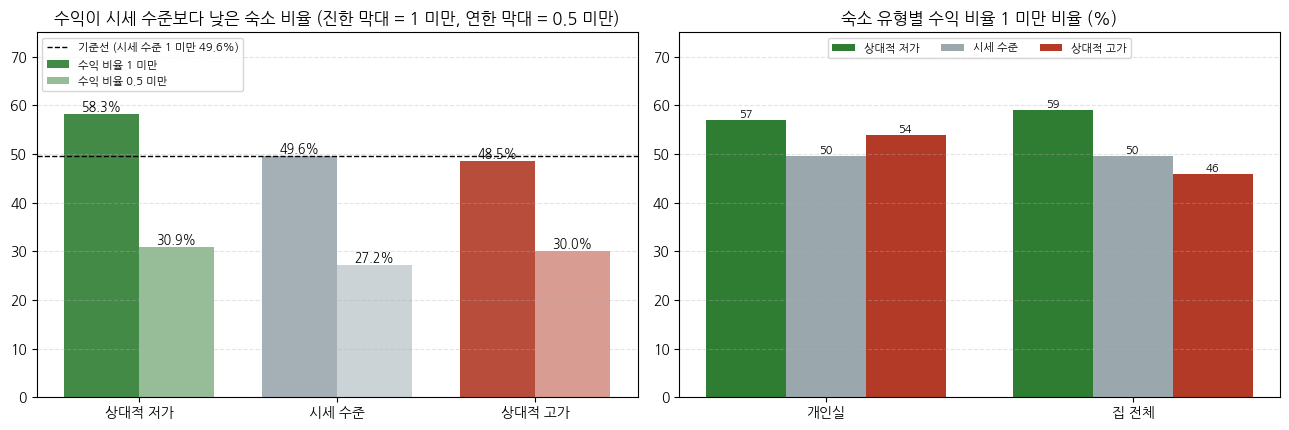

seg,고가·수익 낮음,고가·수익 같거나 높음,시세 수준,저가·수익 같거나 높음,저가·수익 낮음
숙소 수,2594.00,2756.00,13497.00,2013.00,2815.00
개인실 %,36.58,29.28,34.12,35.32,33.39
편차 중앙값 %,39.83,38.70,-2.36,-28.43,-29.00
추정 예약일 중앙값,28.00,156.00,120.00,255.00,83.00
예약일 배수 중앙값,0.23,1.29,1.00,1.91,0.63
수익 비율 중앙값,0.36,1.98,1.00,1.46,0.47
예약 0일 %,24.67,0.00,6.57,0.00,10.44
예약일 상한(255일) %,0.00,25.65,21.46,57.87,7.85
최근 1년 리뷰 수 중앙값,3.00,17.00,13.00,31.00,8.00
앞으로 1년 예약 가능일 중앙값,241.00,247.00,212.00,212.00,171.00


수익 낮음  수익 같거나 높음       차이 크기   p-value
가격 집단  특징                                                    
상대적 고가 편차               0.40       0.39  r = +0.023   8.6e-02
       앞으로 1년 예약 가능일  241.00     247.00  r = +0.006   6.9e-01
       평점               4.83       4.88  r = -0.115   4.9e-17
       가성비 점수           4.72       4.77  r = -0.134   1.4e-22
       조회 박 수           2.00       2.00  r = +0.133   7.2e-25
       슈퍼호스트 %         28.40      57.40     -29.0%p  1.8e-101
       첫 리뷰 1년 이내 %     2.90      21.30     -18.4%p   3.3e-92
       개인실 %           36.60      29.30      +7.3%p   1.5e-08
       3박 이상 조회 %      33.80      22.30     +11.6%p   5.5e-21
상대적 저가 편차              -0.29      -0.28  r = -0.038   8.6e-03
       앞으로 1년 예약 가능일  171.00     212.00  r = -0.086   1.9e-09
       평점               4.71       4.78  r = -0.151   9.0e-26
       가성비 점수           4.65       4.71  r = -0.151   8.2e-26
       조회 박 수           2.00       2.00  r = +0.145   2.8e-26
       슈퍼호스트 %         23.40      43.70     -20.3%p   3.7e-50
       첫 리뷰 1년 이내 %    16.10      19.40      -3.3%p   3.1e-03
       개인실 %           33.40      35.30      -1.9%p   1.7e-01
       3박 이상 조회 %      32.40      20.00     +12.4%p   1.5e-21

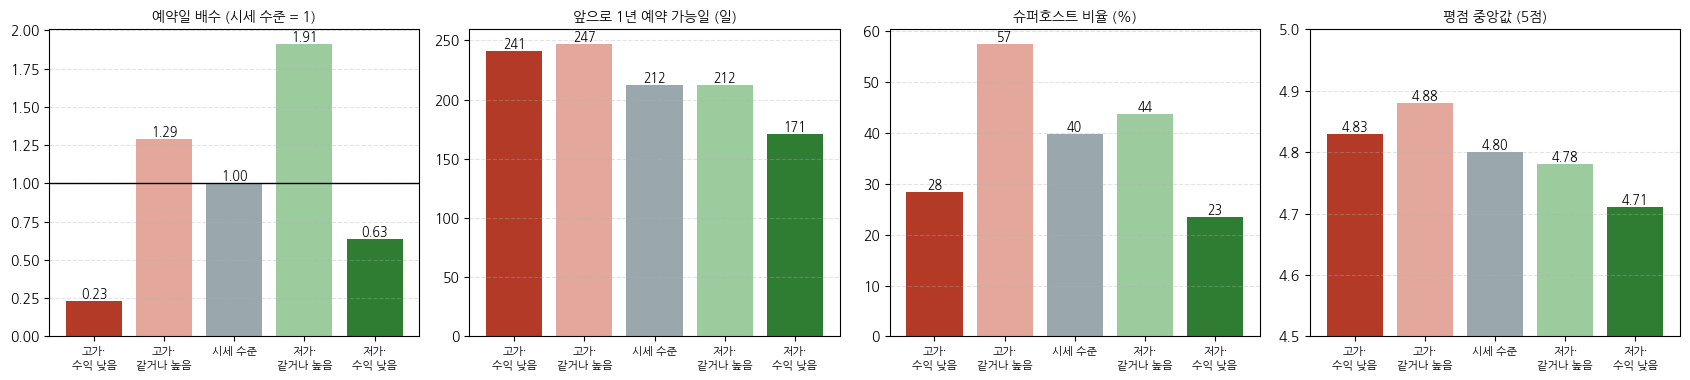

In [ ]:
# [Step 8] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 8-1. 수익 비율 1 미만 현황
# ====================================================================================================
# [8-1] 가격 집단별 수익 비율 1 미만·0.5 미만 숙소 수, 기준선(시세 수준)과 비교, 유형별 비율

comp["low_rev"] = comp["rev_ratio"] < 1                                              # 수익 낮음
comp["half_rev"] = comp["rev_ratio"] < 0.5                                           # 시세 수준 수익의 절반 미만
comp["shortfall"] = (comp["fair_med_rev"] - comp["est_revenue"]).clip(lower=0)       # 시세 수준 수익 중앙값보다 덜 번 금액
status = comp.groupby("group").agg(**{
    "숙소 수": ("id", "size"),
    "수익 비율 1 미만 (곳)": ("low_rev", "sum"),
    "1 미만 %": ("low_rev", lambda s: s.mean() * 100),
    "수익 비율 0.5 미만 (곳)": ("half_rev", "sum"),
    "0.5 미만 %": ("half_rev", lambda s: s.mean() * 100),
    "예약 0일 (곳)": ("estimated_occupancy_l365d", lambda s: int((s == 0).sum())),
    "덜 번 금액 (만 파운드)": ("shortfall", lambda s: s.sum() / 1e4),
}).loc[order]
display(status.round(1))

dev = comp[comp["group"] != "시세 수준"]
base_pct = status.loc["시세 수준", "1 미만 %"]
print(f"편차가 기준선 ±{THRESHOLD:.0%}를 넘어 벗어난 숙소 {len(dev):,}곳 중 수익 비율 1 미만 {int(dev['low_rev'].sum()):,}곳 ({dev['low_rev'].mean():.1%}) "
      f"| 기준선(시세 수준) {base_pct:.1f}%")
print(f"  상대적 고가 {status.loc['상대적 고가', '1 미만 %']:.1f}% (기준선 대비 {status.loc['상대적 고가', '1 미만 %'] - base_pct:+.1f}%p) "
      f"| 상대적 저가 {status.loc['상대적 저가', '1 미만 %']:.1f}% (기준선 대비 {status.loc['상대적 저가', '1 미만 %'] - base_pct:+.1f}%p)")

type_low = (comp.groupby([comp["room_type"].map(TYPE_KR), "group"])["low_rev"].mean().unstack()[order] * 100).round(1)
print("숙소 유형별 수익 비율 1 미만 비율 (%)")
display(type_low)

seg_order = ["고가·수익 낮음", "고가·수익 같거나 높음", "시세 수준", "저가·수익 같거나 높음", "저가·수익 낮음"]
comp["seg"] = np.select([(comp["group"] == "상대적 고가") & comp["low_rev"], comp["group"] == "상대적 고가",
                         (comp["group"] == "상대적 저가") & comp["low_rev"], comp["group"] == "상대적 저가"],
                        [seg_order[0], seg_order[1], seg_order[4], seg_order[3]], seg_order[2])

# ====================================================================================================
# 8-2. 현황 그래프
# ====================================================================================================
# [8-2] 집단별 수익 비율 1 미만·0.5 미만 비율 (기준선 표시), 유형별 1 미만 비율

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
pos = np.arange(3); w = 0.38
for j, (col, lab, alpha) in enumerate([("1 미만 %", "수익 비율 1 미만", 0.9), ("0.5 미만 %", "수익 비율 0.5 미만", 0.5)]):
    vals = status[col].values
    axes[0].bar(pos + (j - 0.5) * w, vals, width=w, color=[COLORS[g] for g in order], alpha=alpha, label=lab)
    for x, v in zip(pos + (j - 0.5) * w, vals):
        axes[0].text(x, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
axes[0].axhline(base_pct, color="black", linestyle="--", linewidth=1, label=f"기준선 (시세 수준 1 미만 {base_pct:.1f}%)")
axes[0].set_xticks(pos); axes[0].set_xticklabels(order); axes[0].set_ylim(0, 75)
axes[0].set_title("수익이 시세 수준보다 낮은 숙소 비율 (진한 막대 = 1 미만, 연한 막대 = 0.5 미만)")
axes[0].legend(fontsize=8, loc="upper left"); axes[0].grid(axis="y", linestyle="--", alpha=0.35)
xt = np.arange(len(type_low)); w2 = 0.26
for i, g in enumerate(order):
    vals = type_low[g].values
    axes[1].bar(xt + (i - 1) * w2, vals, width=w2, color=COLORS[g], label=g)
    for x, v in zip(xt + (i - 1) * w2, vals):
        axes[1].text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8)
axes[1].set_xticks(xt); axes[1].set_xticklabels(type_low.index); axes[1].set_ylim(0, 75)
axes[1].set_title("숙소 유형별 수익 비율 1 미만 비율 (%)"); axes[1].legend(fontsize=8, ncol=3, loc="upper center")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# ====================================================================================================
# 8-3. 어떤 숙소인가: 다섯 묶음의 특징
# ====================================================================================================
# [8-3] 다섯 묶음의 특징 비교 + 같은 가격 집단 안 '수익 낮음 vs 같거나 높음' 차이 크기

first_rev = pd.to_datetime(df.loc[comp.index, "first_review"])
prof_src = comp.assign(avail=df.loc[comp.index, "availability_365"],
                       new=((pd.Timestamp("2026-09-17") - first_rev).dt.days < 365).astype(float),
                       cap=(comp["estimated_occupancy_l365d"] >= 255).astype(float),
                       zero=(comp["estimated_occupancy_l365d"] == 0).astype(float),
                       private=(comp["room_type"] == "Private room").astype(float),
                       long=(comp["quote_nights"] >= 3).astype(float))
profile = prof_src.groupby("seg").agg(**{
    "숙소 수": ("id", "size"),
    "개인실 %": ("private", lambda s: s.mean() * 100),
    "편차 중앙값 %": ("gap", lambda s: s.median() * 100),
    "추정 예약일 중앙값": ("estimated_occupancy_l365d", "median"),
    "예약일 배수 중앙값": ("rel_occ", "median"),
    "수익 비율 중앙값": ("rev_ratio", "median"),
    "예약 0일 %": ("zero", lambda s: s.mean() * 100),
    "예약일 상한(255일) %": ("cap", lambda s: s.mean() * 100),
    "최근 1년 리뷰 수 중앙값": ("number_of_reviews_ltm", "median"),
    "앞으로 1년 예약 가능일 중앙값": ("avail", "median"),
    "평점 중앙값": ("review_scores_rating", "median"),
    "가성비 점수 중앙값": ("review_scores_value", "median"),
    "슈퍼호스트 %": ("superhost", lambda s: s.mean() * 100),
    "첫 리뷰 1년 이내 %": ("new", lambda s: s.mean() * 100),
    "3박 이상 조회 %": ("long", lambda s: s.mean() * 100),
}).loc[seg_order]
display(profile.T.round(2))

# 같은 가격 집단 안 비교: 연속값은 Mann-Whitney (맨-휘트니 검정) 효과 크기 r(+면 '수익 낮음'이 큼), 비율은 %p 차이
feat_cont = [("gap", "편차"), ("avail", "앞으로 1년 예약 가능일"), ("review_scores_rating", "평점"),
             ("review_scores_value", "가성비 점수"), ("quote_nights", "조회 박 수")]
feat_bin = [("superhost", "슈퍼호스트"), ("new", "첫 리뷰 1년 이내"), ("private", "개인실"), ("long", "3박 이상 조회")]
diff_rows = []
for g, lo, hi in [("상대적 고가", seg_order[0], seg_order[1]), ("상대적 저가", seg_order[4], seg_order[3])]:
    a, b = prof_src[prof_src["seg"] == lo], prof_src[prof_src["seg"] == hi]
    for col, nm in feat_cont:
        U, p = stats.mannwhitneyu(a[col], b[col], alternative="two-sided")
        z = (U - len(a) * len(b) / 2) / np.sqrt(len(a) * len(b) * (len(a) + len(b) + 1) / 12)
        diff_rows.append({"가격 집단": g, "특징": nm, "수익 낮음": round(a[col].median(), 2), "수익 같거나 높음": round(b[col].median(), 2),
                          "차이 크기": f"r = {z / np.sqrt(len(a) + len(b)):+.3f}", "p-value": f"{p:.1e}"})
    for col, nm in feat_bin:
        _, p, _, _ = stats.chi2_contingency(pd.crosstab(pd.concat([a, b])["seg"], pd.concat([a, b])[col]))
        diff_rows.append({"가격 집단": g, "특징": nm + " %", "수익 낮음": round(a[col].mean() * 100, 1),
                          "수익 같거나 높음": round(b[col].mean() * 100, 1),
                          "차이 크기": f"{(a[col].mean() - b[col].mean()) * 100:+.1f}%p", "p-value": f"{p:.1e}"})
display(pd.DataFrame(diff_rows).set_index(["가격 집단", "특징"]))

# ====================================================================================================
# 8-4. 특징 그래프
# ====================================================================================================
# [8-4] 다섯 묶음의 예약일 배수·예약 가능일·슈퍼호스트·평점

seg_colors = [COLORS["상대적 고가"], "#E3A79B", COLORS["시세 수준"], "#9CCB9E", COLORS["상대적 저가"]]
seg_ticks = ["고가·\n수익 낮음", "고가·\n같거나 높음", "시세 수준", "저가·\n같거나 높음", "저가·\n수익 낮음"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9))
for ax, col, title, fmt in [(axes[0], "예약일 배수 중앙값", "예약일 배수 (시세 수준 = 1)", "{:.2f}"),
                            (axes[1], "앞으로 1년 예약 가능일 중앙값", "앞으로 1년 예약 가능일 (일)", "{:.0f}"),
                            (axes[2], "슈퍼호스트 %", "슈퍼호스트 비율 (%)", "{:.0f}"),
                            (axes[3], "평점 중앙값", "평점 중앙값 (5점)", "{:.2f}")]:
    vals = profile[col].values
    ax.bar(seg_ticks, vals, color=seg_colors)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
    if col == "평점 중앙값":
        ax.set_ylim(4.5, 5.0)
    if col == "예약일 배수 중앙값":
        ax.axhline(1, color="black", linewidth=1)
    ax.set_title(title, fontsize=10); ax.grid(axis="y", linestyle="--", alpha=0.35); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

### Step 8 실행 결과와 해석

#### 8-1. 수익 비율 1 미만 현황

**결과**

| 가격 집단 | 숙소 수 | 수익 비율 1 미만 | 수익 비율 0.5 미만 | 예약 0일 | 덜 번 금액 |
| --- | --- | --- | --- | --- | --- |
| 상대적 저가 | 4,828 | **2,815곳 (58.3%)** | 1,493곳 (30.9%) | 294곳 | 3,317만 파운드 |
| 시세 수준 (기준선) | 13,497 | 6,690곳 (49.6%) | 3,665곳 (27.2%) | 887곳 | 7,739만 파운드 |
| 상대적 고가 | 5,350 | **2,594곳 (48.5%)** | 1,604곳 (30.0%) | 640곳 | 3,349만 파운드 |

- 시세에서 편차가 기준선을 넘어 벗어난 숙소 **10,178곳 중 수익 비율 1 미만은 5,409곳(53.1%)**이다. 기준선(시세 수준)은 49.6%다.
- 기준선 대비: 상대적 고가 -1.1%p, 상대적 저가 **+8.7%p**.

| 수익 비율 1 미만 비율 | 상대적 저가 | 시세 수준 | 상대적 고가 |
| --- | --- | --- | --- |
| 개인실 | 56.9% | 49.6% | 54.0% |
| 집 전체 | 59.0% | 49.5% | 45.8% |

**해석**
- **기준선부터 봐야 한다.** 수익 비율은 시세 수준 숙소의 중앙값과 비교한 값이라, 시세 수준 숙소도 거의 절반(49.6%)이 1 미만이다. 그래서 **기준선보다 많은가**가 중요하다.
- **상대적 고가는 48.5%로 기준선과 같다.** 비싸게 받는다고 수익 낮은 숙소가 더 많지는 않다. 다만 예약 0일(640곳)은 많다.
- **상대적 저가는 58.3%로 기준선보다 8.7%p 많다.** 비율로 보면 싸게 받는 숙소에서 '수익 낮음'이 더 흔하다.
- 유형별로 보면 상대적 저가는 두 유형 모두 기준선보다 높고(개인실 56.9%, 집 전체 59.0%), 상대적 고가는 **개인실만** 높다(개인실 54.0%, 집 전체 45.8%).
- **다음 단계로 넘길 것**: 이 차이(%p)가 통계적으로 의미 있는지는 이 모델링 노트북에서 검정하지 않았다. 다음 검정 단계에서 검정 담당이 카이제곱 검정과 효과 크기 Cramér's V로 '상대적 저가 vs 시세 수준', '상대적 고가 vs 시세 수준'을 확인해야 한다. 그 결과가 핵심 질문의 답인 '기준선보다 많다'를 뒷받침한다.

#### 8-2. 현황 그래프

**결과**: 왼쪽 그림에서 진한 막대(1 미만)는 상대적 저가 58.3%, 시세 수준 49.6%, 상대적 고가 48.5%다. 점선(기준선) 위로 확실히 올라간 것은 상대적 저가뿐이다. 연한 막대(0.5 미만)는 세 집단 모두 27~31%로 비슷하다. 오른쪽 그림에서는 상대적 저가 막대가 두 유형 모두 시세 수준보다 높고, 상대적 고가는 개인실만 높다.

**해석**: '수익이 시세 수준보다 낮은 숙소'는 시세 수준 숙소에도 절반 가까이 있다. 시세에서 벗어난 것이 위험을 키우는 경우는 **싸게 받는 숙소 전반**과 **비싸게 받는 개인실**이다.

#### 8-3. 어떤 숙소인가: 다섯 묶음의 특징

**결과**: 다섯 묶음의 특징 (중앙값 또는 비율)

| 특징 | 고가·수익 낮음 | 고가·수익 같거나 높음 | 시세 수준 | 저가·수익 같거나 높음 | 저가·수익 낮음 |
| --- | --- | --- | --- | --- | --- |
| 숙소 수 | 2,594 | 2,756 | 13,497 | 2,013 | 2,815 |
| 개인실 | 36.6% | 29.3% | 34.1% | 35.3% | 33.4% |
| 편차 | +40% | +39% | −2% | −28% | −29% |
| 추정 예약일 (배수) | 28일 (0.23배) | 156일 (1.29배) | 120일 (1.00배) | 255일 (1.91배) | 83일 (0.63배) |
| 수익 비율 | 0.36 | 1.98 | 1.00 | 1.46 | 0.47 |
| 예약 0일 | 24.7% | 0.0% | 6.6% | 0.0% | 10.4% |
| 예약일 상한(255일) | 0.0% | 25.7% | 21.5% | 57.9% | 7.9% |
| 앞으로 1년 예약 가능일 | 241일 | 247일 | 212일 | 212일 | 171일 |
| 평점 / 가성비 점수 | 4.83 / 4.72 | 4.88 / 4.77 | 4.80 / 4.71 | 4.78 / 4.71 | 4.71 / 4.65 |
| 슈퍼호스트 | 28.4% | 57.4% | 39.7% | 43.7% | 23.4% |
| 첫 리뷰 1년 이내 | 2.9% | 21.3% | 15.5% | 19.4% | 16.1% |
| 3박 이상 조회 | 33.8% | 22.3% | 28.7% | 20.0% | 32.4% |

같은 가격 집단 안에서 '수익 낮음 vs 같거나 높음'의 차이

| 특징 | 상대적 고가 안 차이 | 상대적 저가 안 차이 |
| --- | --- | --- |
| 편차 | 0.4 vs 0.39 (r = +0.023, p = 8.6e-02) | -0.29 vs -0.28 (r = -0.038, p = 8.6e-03) |
| 앞으로 1년 예약 가능일 | 241.0 vs 247.0 (r = +0.006, p = 6.9e-01) | 171.0 vs 212.0 (r = -0.086, p = 1.9e-09) |
| 평점 | 4.83 vs 4.88 (r = -0.115, p = 4.9e-17) | 4.71 vs 4.78 (r = -0.151, p = 9.0e-26) |
| 가성비 점수 | 4.72 vs 4.77 (r = -0.134, p = 1.4e-22) | 4.65 vs 4.71 (r = -0.151, p = 8.2e-26) |
| 슈퍼호스트 | 28.4 vs 57.4 (-29.0%p, p = 1.8e-101) | 23.4 vs 43.7 (-20.3%p, p = 3.7e-50) |
| 첫 리뷰 1년 이내 | 2.9 vs 21.3 (-18.4%p, p = 3.3e-92) | 16.1 vs 19.4 (-3.3%p, p = 3.1e-03) |
| 3박 이상 조회 | 33.8 vs 22.3 (+11.6%p, p = 5.5e-21) | 32.4 vs 20.0 (+12.4%p, p = 1.5e-21) |
| 개인실 | 36.6 vs 29.3 (+7.3%p, p = 1.5e-08) | 33.4 vs 35.3 (-1.9%p, p = 1.7e-01) |

**해석**
- **고가·수익 낮음 (2,594곳): 비싼데 예약이 거의 안 되는 숙소.** 시세보다 40% 비싸고, 1년에 28일만 예약되며 4곳 중 1곳은 예약이 0일이다. 달력은 열려 있고(241일) 평점도 나쁘지 않다(4.83).
  - 같은 고가인데 잘 버는 숙소와 비교하면 **편차가 같다**(+40% vs +39%, 차이 없음). 달력을 열어 둔 날도 같다. 즉 **가격만으로는 이 둘이 갈리지 않는다.**
  - 가장 크게 다른 것은 **슈퍼호스트 비율**(28% vs 57%)이다. 그다음은 최소 숙박일이 긴 숙소(3박 이상 조회 34% vs 22%)와 새로 시작한 숙소(잘 버는 쪽에 21%)다.
- **저가·수익 낮음 (2,815곳): 싸게 받는데도 예약이 적은 숙소.** 시세보다 29% 싸지만 예약일이 시세 수준의 0.63배(83일)다. 가설 1-2의 '많은 예약일'은 저가 **집단 전체**에는 맞지만, **수익이 낮은 저가 숙소에는 맞지 않는다.**
  - 같은 저가인데 잘 버는 숙소(255일 상한 58%)와 비교하면 편차는 같다. 대신 **달력을 연 날이 적고**(171 vs 212일), **평점·가성비 점수가 다섯 묶음 중 가장 낮으며**, 슈퍼호스트가 적다(23% vs 44%).
- **두 '수익 낮음' 묶음의 공통점**: 슈퍼호스트가 적고 최소 숙박일이 긴 숙소가 많다.
- **읽을 때 주의**: 슈퍼호스트 조건에는 지난 1년 숙박 실적이 들어 있어, 예약이 적은 숙소는 슈퍼호스트가 되기 어렵다. 슈퍼호스트 비율 차이는 원인이면서 결과일 수 있다. '첫 리뷰 1년 이내'가 잘 버는 쪽에 많은 것도 최근 리뷰로 예약일을 추정하는 방식 때문일 수 있다.

#### 8-4. 특징 그래프

**결과**: 네 그림 모두 양 끝(고가·수익 낮음, 저가·수익 낮음)이 가운데 묶음보다 낮다. 예약일 배수는 0.23와 0.63, 슈퍼호스트는 28%와 23%다. 다만 예약 가능일은 고가·수익 낮음(241일)이 높고 저가·수익 낮음(171일)만 낮다. 평점은 저가·수익 낮음(4.71)이 가장 낮다.

**해석**: 두 '수익 낮음' 묶음은 이유가 다르다. **고가·수익 낮음**은 달력도 열려 있고 평점도 괜찮은데 예약이 안 된다. **저가·수익 낮음**은 달력을 덜 열고 평점도 낮다.

### Step 8 종합 분석 (핵심 질문)

**같은 조건 시세와의 가격 편차가 크고, 1년 추정 수익이 시세 수준 숙소보다 낮은 숙소는 어떤 숙소인가?**

| 묶음 | 숙소 수 | 한 줄로 | 특징 |
| --- | --- | --- | --- |
| 고가·수익 낮음 | **2,594곳** (상대적 고가의 48.5%) | 비싼데 예약이 거의 안 되는 숙소 | 편차 +40%, 1년 28일, 예약 0일 25%. 달력은 열려 있고 평점 4.83. 같은 편차의 잘 버는 숙소보다 슈퍼호스트가 절반(28% vs 57%) |
| 저가·수익 낮음 | **2,815곳** (상대적 저가의 58.3%) | 싸게 받아도 예약이 적은 숙소 | 편차 −29%, 1년 83일(시세 수준의 0.63배). 예약 가능일 171일로 가장 적고, 평점 4.71·가성비 4.65로 가장 낮음 |
| 합계 | **5,409곳** (가격 편차가 큰 숙소의 53.1%) | | 비율로 기준선(시세 수준 49.6%)보다 많은 것은 저가 쪽(+8.7%p). 차이의 통계 검정은 다음 검정 단계에서 진행 |

**의견**: 두 묶음 모두 **같은 편차에서 잘 버는 숙소가 따로 있다.** 그래서 이 숙소들이 덜 버는 이유를 가격 하나로 설명할 수 없다. 고가 쪽은 '가격을 시세 쪽으로 낮추는 것'이 시도해 볼 수단이 되지만, 저가 쪽은 이미 싸므로 가격을 더 내리는 것은 답이 아니다.

**다음 질문**: 비싸게 받는 숙소는 게스트에게 '가성비가 나쁘다'는 평가를 받을까? → Step 9 (보조 질문)

---
## Step 9. 보조 질문: 같은 조건 시세와의 가격 편차는 게스트의 가성비 평가와 연결되는가?
**보조 가설**: 시세보다 높은 쪽으로 가격 편차가 클수록 가성비 점수가 낮다.

**방법**
- 가성비 점수 = `review_scores_value`(묵은 게스트가 매긴 5점 만점 점수).
- (1) 집단별 중앙값: Kruskal-Wallis 검정과 효과 크기 ε²(0.01 작음, 0.06 중간, 0.14 큼), 쌍별 Mann-Whitney 효과 크기 r.
- (2) 편차와 가성비 점수의 Spearman 순위 상관 ρ: 전체, 숙소 유형별.
- (3) 같은 조건 묶음 안 Spearman ρ: 묶음마다 따로 계산해 중앙값과 양수 묶음 비율을 본다. 위치·크기 차이를 뺀 연결이다.
- 판정: ρ가 음수이고 p < 0.05이며 |ρ| ≥ 0.1이면 채택(서두 기준).

**읽을 때 주의**: 점수는 **예약해서 묵은 게스트만** 매긴다. 비싸서 예약하지 않은 게스트의 판단은 들어 있지 않다. 또 4.5점 이상에 81%가 몰려 있어(전처리 탐색 결과) 차이가 작게 나오기 쉽다.

가성비 점수 Kruskal-Wallis: H = 226.0, p = 8.4e-50, 효과 크기 ε² = 0.0088


,비교,중앙값,p-value (본페로니 ×3),효과 크기 r
0,상대적 고가 vs 시세 수준,4.75 vs 4.71,4.0e-21,0.067
1,상대적 저가 vs 시세 수준,4.68 vs 4.71,2.3e-17,-0.061
2,상대적 고가 vs 상대적 저가,4.75 vs 4.68,1.1e-49,0.141


,숙소 수,Spearman ρ,p-value,판정
범위,,,,
전체,25607,0.103,1.1e-61,기각
집 전체,17004,0.142,1.8e-77,기각
개인실,8603,0.049,6.4e-06,기각
같은 조건 묶음 안 (묶음별 ρ의 중앙값),23675,0.105,양수 묶음 73% (176/242),참고


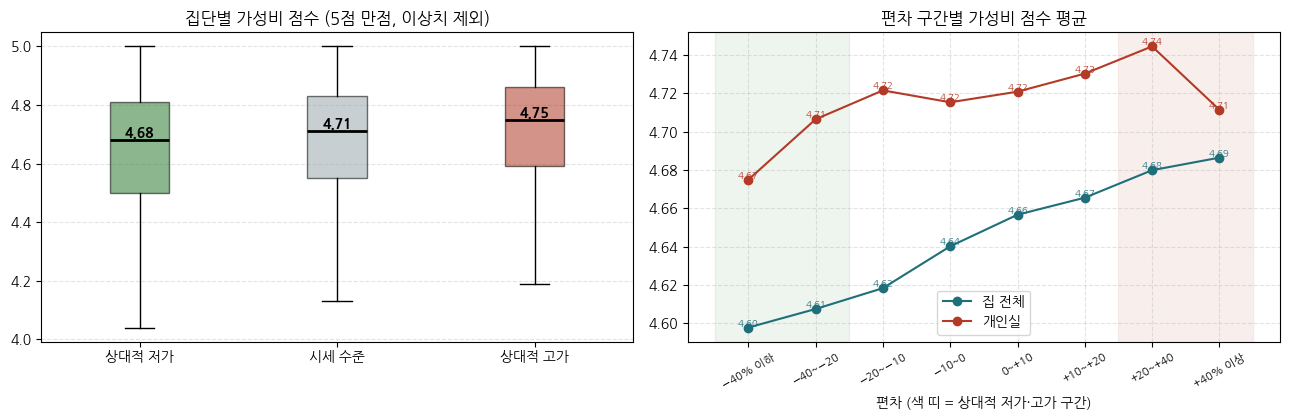

In [ ]:
# [Step 9] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 9-1. 편차와 가성비 점수
# ====================================================================================================
# [9-1] 집단별 가성비 점수 비교, 편차와의 Spearman (스피어만 순위 상관) ρ (전체·유형별·같은 묶음 안), 판정

warnings.filterwarnings("ignore", category=stats.ConstantInputWarning)   # 점수가 모두 같은 묶음은 ρ를 계산하지 않음

vals = [diag.loc[diag["group"] == k, "review_scores_value"] for k in order]
H, p_kw = stats.kruskal(*vals)
eps2 = H / (sum(len(v) for v in vals) - 1)
print(f"가성비 점수 Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.1e}, 효과 크기 ε² = {eps2:.4f}")
pair_rows = []
for a, b in [("상대적 고가", "시세 수준"), ("상대적 저가", "시세 수준"), ("상대적 고가", "상대적 저가")]:
    xa, xb = vals[order.index(a)], vals[order.index(b)]
    U, p = stats.mannwhitneyu(xa, xb, alternative="two-sided")
    z = (U - len(xa) * len(xb) / 2) / np.sqrt(len(xa) * len(xb) * (len(xa) + len(xb) + 1) / 12)
    pair_rows.append({"비교": f"{a} vs {b}", "중앙값": f"{xa.median():.2f} vs {xb.median():.2f}",
                      "p-value (본페로니 ×3)": f"{min(p * 3, 1):.1e}", "효과 크기 r": round(z / np.sqrt(len(xa) + len(xb)), 3)})
display(pd.DataFrame(pair_rows))

rho_rows = []
for label_t, mk in [("전체", np.ones(len(diag), bool))] + [(lab, (diag["room_type"] == rt).values) for rt, lab in TYPE_KR.items()]:
    res_s = stats.spearmanr(diag.loc[mk, "gap"], diag.loc[mk, "review_scores_value"])
    rho_rows.append({"범위": label_t, "숙소 수": int(mk.sum()), "Spearman ρ": round(res_s.statistic, 3), "p-value": f"{res_s.pvalue:.1e}",
                     "판정": verdict(res_s.statistic, res_s.pvalue, -1)})
cell_rho = comp.groupby("cell").apply(lambda g: stats.spearmanr(g["gap"], g["review_scores_value"]).statistic,
                                      include_groups=False).dropna()
rho_rows.append({"범위": "같은 조건 묶음 안 (묶음별 ρ의 중앙값)", "숙소 수": len(comp), "Spearman ρ": round(cell_rho.median(), 3),
                 "p-value": f"양수 묶음 {(cell_rho > 0).mean():.0%} ({int((cell_rho > 0).sum())}/{len(cell_rho)})", "판정": "참고"})
display(pd.DataFrame(rho_rows).set_index("범위"))

gap_bins = [-np.inf, -0.4, -0.2, -0.1, 0, 0.1, 0.2, 0.4, np.inf]
gap_labels = ["−40% 이하", "−40~−20", "−20~−10", "−10~0", "0~+10", "+10~+20", "+20~+40", "+40% 이상"]
diag["gap_bin"] = pd.cut(diag["gap"], gap_bins, labels=gap_labels)
val_curve = diag.groupby([diag["room_type"].map(TYPE_KR), "gap_bin"], observed=True)["review_scores_value"].agg(["size", "mean", "median"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
bp = axes[0].boxplot(vals, showfliers=False, patch_artist=True, medianprops=dict(color="black", linewidth=2))
for patch, k in zip(bp["boxes"], order):
    patch.set_facecolor(COLORS[k]); patch.set_alpha(0.55)
axes[0].set_xticks([1, 2, 3]); axes[0].set_xticklabels(order)
for i, v in enumerate(vals, 1):
    axes[0].text(i, v.median(), f"{v.median():.2f}", ha="center", va="bottom", fontweight="bold")
axes[0].set_title("집단별 가성비 점수 (5점 만점, 이상치 제외)"); axes[0].grid(axis="y", linestyle="--", alpha=0.35)
xs = np.arange(len(gap_labels))
for label_t, c in [("집 전체", "#1F6F7A"), ("개인실", "#B23A26")]:
    m_vals = val_curve.loc[label_t, "mean"].reindex(gap_labels).values
    axes[1].plot(xs, m_vals, marker="o", color=c, label=label_t)
    for xx, v in zip(xs, m_vals):
        axes[1].text(xx, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color=c)
axes[1].axvspan(-0.5, 1.5, color=COLORS["상대적 저가"], alpha=0.08)
axes[1].axvspan(5.5, 7.5, color=COLORS["상대적 고가"], alpha=0.08)
axes[1].set_xticks(xs); axes[1].set_xticklabels(gap_labels, rotation=30, fontsize=8)
axes[1].set_xlabel("편차 (색 띠 = 상대적 저가·고가 구간)")
axes[1].set_title("편차 구간별 가성비 점수 평균"); axes[1].legend(); axes[1].grid(linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

### Step 9 실행 결과와 해석

#### 9-1. 편차와 가성비 점수

**결과**

| 집단 | 가성비 점수 중앙값 |
| --- | --- |
| 상대적 저가 | 4.68 |
| 시세 수준 | 4.71 |
| 상대적 고가 | **4.75** |

- Kruskal-Wallis(크러스컬-월리스 검정) 효과 크기 ε² = **0.0088** (0.01 미만, 매우 작음). 쌍별 효과 크기 r: 상대적 고가 vs 시세 수준 +0.067, 상대적 저가 vs 시세 수준 −0.061, 상대적 고가 vs 상대적 저가 +0.141.

| 범위 | 편차와 가성비 점수의 Spearman(스피어만 순위 상관) ρ | 판정 |
| --- | --- | --- |
| 전체 (25,607곳) | **+0.103** | 기각 (방향 반대) |
| 집 전체 (17,004곳) | +0.142 | 기각 (방향 반대) |
| 개인실 (8,603곳) | +0.049 | 기각 (방향 반대) |
| 같은 조건 묶음 안 (242개 묶음 ρ의 중앙값) | +0.105, 묶음의 73%(176개)에서 양수 | 같은 결론 |

- 편차 구간별 가성비 점수 평균(집 전체): −40% 이하 4.60 → 0~+10% 4.66 → +40% 이상 4.69로 조금씩 오른다. 개인실은 4.67 ~ 4.74 사이로 거의 평평하다.

**해석**
- 보조 가설은 '시세보다 높은 쪽으로 가격 편차가 클수록 가성비 점수가 낮다'였지만, 결과는 **반대로 아주 조금 높다**. ρ = +0.103이고, 같은 조건 묶음 안에서 봐도 +0.105로 같다.
- 다만 차이는 아주 작다. 집단 차이로 설명되는 부분이 점수 차이의 1% 미만이다(ε² = 0.009).
- 이 점수는 **예약해서 묵은 게스트만** 매긴다. 비싸서 예약하지 않은 게스트의 판단은 들어 있지 않다. 점수가 4.5점 이상에 81% 몰려 있는 것도 차이를 작게 만든다.

### Step 9 종합 분석 (보조 질문)
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 집단별 가성비 점수 | 저가 4.68 < 시세 수준 4.71 < 고가 4.75 (ε² = 0.009) | 차이는 아주 작고, 방향은 가설과 반대 |
| 가격 편차와의 순위 상관 | 전체 ρ = +0.103, 같은 묶음 안 +0.105 | **기각**: 높은 쪽으로 가격 편차가 클수록 가성비 점수가 낮지 않다 |
| 한계 | 묵은 게스트만 평가, 4.5점 이상 81% | 예약하지 않은 게스트의 판단은 알 수 없다 |

**의견**: 게스트 평가로는 '비싸서 불만'이라는 신호가 보이지 않는다. 오히려 Step 8에서 본 것처럼 **수익이 낮은 숙소가 가성비 점수도 낮다**(저가·수익 낮음 4.65). 가성비 점수는 편차보다 숙소 운영·품질과 더 관계가 있어 보인다.

**다음 질문**: 평점·슈퍼호스트를 맞춰도, 예약일 상한을 고려해도, 기준선·모델이나 비교 묶음 기준을 바꿔도 결론이 같을까? → Step 10

---
## Step 10. 결론 점검
**문제 제기**
1. 평점·슈퍼호스트 같은 품질을 똑같이 맞춰도 가설 1-1·1-2의 수익 차이가 남을까?
2. 추정 예약일의 255일 상한이 결론을 바꿀까? 싼 숙소일수록 상한에 많이 걸려, 상대적 저가의 수익이 낮게 추정될 수 있다.
3. 편차 기준선을 10%p 좁히거나 넓혀도, 모델(Ridge·결정트리)을 바꿔도 결론이 같을까?
4. 같은 조건 묶음을 쓰는 기준(시세 수준 숙소 10곳 이상)을 5곳으로 넓히거나 30곳으로 좁혀도 결론이 같을까? 기준이 느슨하면 비교 대상이 적은 묶음이 들어오고, 엄격하면 빠지는 숙소가 늘어난다.

숙소 수 상대적 고가 vs 시세 수준 [95% 구간] 상대적 저가 vs 시세 수준 [95% 구간]
지표                모형                                                                  
1년 수익 (예약 있는 숙소)  통제 없음        21854    +21.0% [+16.0, +25.4]    -15.3% [-17.8, -12.6]
                  평점·슈퍼호스트 통제  21854    +15.5% [+11.3, +19.5]     -10.2% [-12.7, -7.5]
추정 예약일 (예약 있는 숙소) 통제 없음        21854    -20.3% [-23.6, -17.6]    +15.7% [+12.6, +19.4]
                  평점·슈퍼호스트 통제  21854    -22.5% [-25.5, -19.8]    +20.3% [+16.6, +24.2]
예약 0일 비율          통제 없음        23675      +5.6%p [+4.6, +6.6]      -0.4%p [-1.2, +0.5]
                  평점·슈퍼호스트 통제  23675      +6.0%p [+5.0, +6.9]      -1.1%p [-1.9, -0.2]

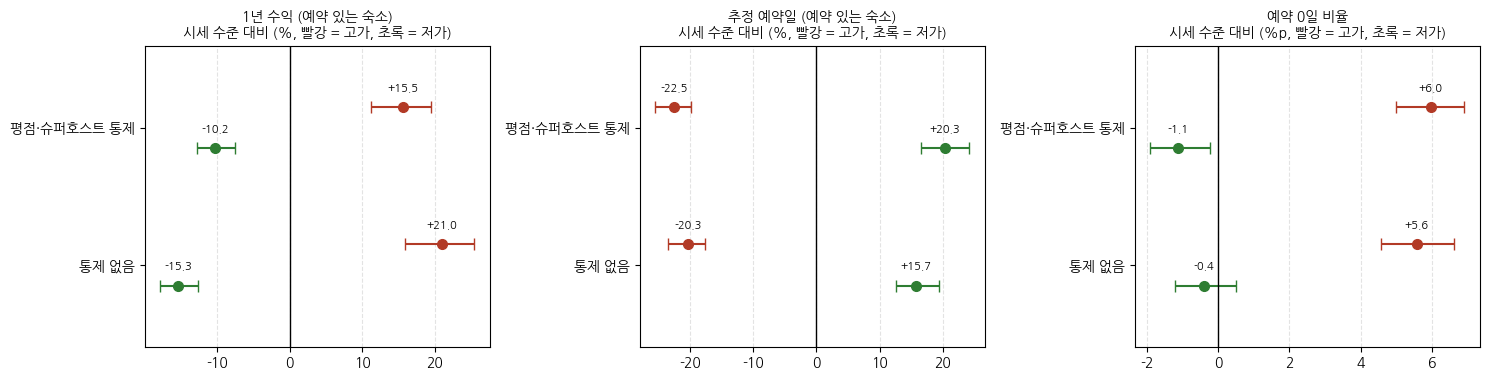

예약일 상한에 걸린 비율: 상대적 저가 28.5% | 시세 수준 21.1% | 상대적 고가 13.1%


,고가 수익 비율,고가 수익 r,고가 판정,저가 수익 비율,저가 수익 r,저가 판정
점검,,,,,,
① 그대로 (기본),1.041,0.038,기각,0.848,-0.097,부분 채택 (방향은 맞지만 차이가 작음)
② 상한 숙소 빼기,1.153,0.061,기각,0.773,-0.115,채택
③ 상한 숙소를 365일로 올리기 (최대치),1.024,0.012,기각,0.877,-0.063,부분 채택 (방향은 맞지만 차이가 작음)


,R²,고가 수,고가 수익 비율,고가 수익 r,저가 수,저가 수익 비율,저가 수익 r,1 미만 % (고가 / 시세 수준 / 저가)
점검,,,,,,,,
최종: 랜덤포레스트 · ±20%,0.802,5350,1.041,0.038,4828,0.848,-0.097,48.5 / 49.6 / 58.3
기준선 ±10%,0.802,7371,1.033,0.033,7984,0.874,-0.087,48.9 / 49.3 / 56.7
기준선 ±30%,0.802,3804,1.051,0.033,2257,0.830,-0.079,48.5 / 49.6 / 58.8
모델: Ridge,0.747,6186,1.093,0.060,5601,0.828,-0.124,46.8 / 49.5 / 60.4
모델: 결정트리,0.758,5914,1.051,0.044,5541,0.873,-0.085,48.2 / 49.5 / 56.9


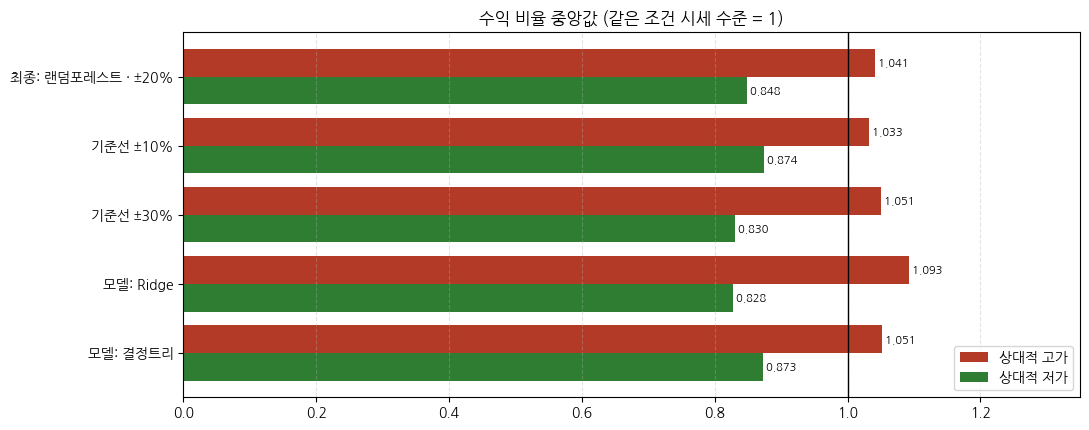

,묶음 수,숙소 수,전체 대비 %,고가 수익 비율,고가 수익 r,고가 판정,저가 수익 비율,저가 수익 r,저가 판정,1 미만 % (고가 / 시세 수준 / 저가)
시세 수준 최소 숙소 수,,,,,,,,,,
5곳,324,24688,96.4,1.049,0.039,기각,0.849,-0.095,부분 채택 (방향은 맞지만 차이가 작음),48.4 / 49.4 / 58.1
10곳 (기본),242,23675,92.5,1.041,0.038,기각,0.848,-0.097,부분 채택 (방향은 맞지만 차이가 작음),48.5 / 49.6 / 58.3
15곳,199,22780,89.0,1.052,0.041,기각,0.854,-0.095,부분 채택 (방향은 맞지만 차이가 작음),48.2 / 49.6 / 58.0
20곳,159,21605,84.4,1.050,0.039,기각,0.848,-0.099,부분 채택 (방향은 맞지만 차이가 작음),48.3 / 49.7 / 58.5
30곳,127,20245,79.1,1.049,0.037,기각,0.842,-0.101,채택,48.4 / 49.7 / 58.7


In [ ]:
# [Step 10] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 10-1. 품질을 맞춰도 차이가 남는가: 같은 조건 비교 회귀
# ====================================================================================================
# [10-1] 묶음마다 평균을 뺀 회귀(같은 묶음끼리만 비교) + 평점·슈퍼호스트 통제, 묶음 단위 부트스트랩 95% 구간

def within_fit(data, ycol, xcols, n_boot=300):
    # 같은 묶음 평균을 뺀 뒤 최소제곱. 묶음을 통째로 다시 뽑는 부트스트랩으로 95% 구간
    d = data.dropna(subset=[ycol] + xcols)
    cols = [ycol] + xcols
    dm = (d[cols] - d.groupby("cell")[cols].transform("mean")).values
    beta = np.linalg.lstsq(dm[:, 1:], dm[:, 0], rcond=None)[0]
    blocks = [dm[ix] for ix in d.groupby("cell").indices.values()]
    rng_b = np.random.RandomState(RANDOM_STATE)
    boots = []
    for _ in range(n_boot):
        M = np.vstack([blocks[i] for i in rng_b.randint(0, len(blocks), len(blocks))])
        boots.append(np.linalg.lstsq(M[:, 1:], M[:, 0], rcond=None)[0])
    lo_b, hi_b = np.percentile(boots, [2.5, 97.5], axis=0)
    return {x: (b, l, h) for x, b, l, h in zip(xcols, beta, lo_b, hi_b)}, len(d)

fe = comp[["cell", "group", "estimated_occupancy_l365d", "est_revenue", "review_scores_rating", "superhost"]].copy()
fe["high"] = (fe["group"] == "상대적 고가").astype(float)
fe["low"] = (fe["group"] == "상대적 저가").astype(float)
fe["zero"] = (fe["estimated_occupancy_l365d"] == 0).astype(float)                       # 예약 0일 여부
fe["log_rev"] = np.log(fe["est_revenue"].where(fe["est_revenue"] > 0))                  # 예약이 있는 숙소의 log 수익
fe["log_occ"] = np.log(fe["estimated_occupancy_l365d"].where(fe["estimated_occupancy_l365d"] > 0))

def fmt(ycol, b, l, h):
    if ycol == "zero":
        return f"{b * 100:+.1f}%p [{l * 100:+.1f}, {h * 100:+.1f}]"
    return f"{(np.exp(b) - 1) * 100:+.1f}% [{(np.exp(l) - 1) * 100:+.1f}, {(np.exp(h) - 1) * 100:+.1f}]"

outcomes = [("log_rev", "1년 수익 (예약 있는 숙소)"), ("log_occ", "추정 예약일 (예약 있는 숙소)"), ("zero", "예약 0일 비율")]
specs = [("통제 없음", ["high", "low"]), ("평점·슈퍼호스트 통제", ["high", "low", "review_scores_rating", "superhost"])]
fe_rows, fe_plot = [], []
for ycol, yname in outcomes:
    for sname, xcols in specs:
        res, n = within_fit(fe, ycol, xcols)
        fe_rows.append({"지표": yname, "모형": sname, "숙소 수": n,
                        "상대적 고가 vs 시세 수준 [95% 구간]": fmt(ycol, *res["high"]),
                        "상대적 저가 vs 시세 수준 [95% 구간]": fmt(ycol, *res["low"])})
        fe_plot.append((ycol, sname, res["high"], res["low"]))
display(pd.DataFrame(fe_rows).set_index(["지표", "모형"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for ax, (ycol, yname) in zip(axes, outcomes):
    tr_fn = (lambda v: v * 100) if ycol == "zero" else (lambda v: (np.exp(v) - 1) * 100)
    for j, (_, sname, hi_r, lo_r) in enumerate([p for p in fe_plot if p[0] == ycol]):
        for off, (b, l, h), c in [(0.15, hi_r, COLORS["상대적 고가"]), (-0.15, lo_r, COLORS["상대적 저가"])]:
            ax.errorbar([tr_fn(b)], [j + off], xerr=[[tr_fn(b) - tr_fn(l)], [tr_fn(h) - tr_fn(b)]], fmt="o", color=c, capsize=4, markersize=7)
            ax.text(tr_fn(b), j + off + 0.12, f"{tr_fn(b):+.1f}", ha="center", fontsize=8)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks([0, 1]); ax.set_yticklabels([s for s, _ in specs]); ax.set_ylim(-0.6, 1.6)
    ax.set_title(f"{yname}\n시세 수준 대비 ({'%p' if ycol == 'zero' else '%'}, 빨강 = 고가, 초록 = 저가)", fontsize=10)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# ====================================================================================================
# 10-2. 예약일 255일 상한 점검
# ====================================================================================================
# [10-2] 상한(255일)에 걸린 숙소를 ① 그대로 ② 빼고 ③ 최대치 365일로 올려서 수익 비교를 다시 계산

occ_raw = diag["estimated_occupancy_l365d"].values
capped = occ_raw >= 255
print("예약일 상한에 걸린 비율: " + " | ".join(f"{g} {capped[(diag['group'] == g).values].mean():.1%}" for g in order))
cap_rows = []
for label_t, kw in [("① 그대로 (기본)", {}), ("② 상한 숙소 빼기", {"mask": ~capped}),
                    ("③ 상한 숙소를 365일로 올리기 (최대치)", {"occ": np.where(capped, 365, occ_raw)})]:
    res = same_cell_compare(diag["group"].values, **kw)
    row = {"점검": label_t}
    for g, tag in [("상대적 고가", "고가"), ("상대적 저가", "저가")]:
        row.update({f"{tag} 수익 비율": res[g]["수익 비율"], f"{tag} 수익 r": res[g]["수익 r"],
                    f"{tag} 판정": verdict(res[g]["수익 r"], res[g]["수익 p"], -1)})
    cap_rows.append(row)
display(pd.DataFrame(cap_rows).set_index("점검").round(3))

# ====================================================================================================
# 10-3. 기준선·모델을 바꿔도 같은가
# ====================================================================================================
# [10-3] 편차 기준선(6-2에서 정한 값 ±10%p), 모델(Ridge (릿지 회귀)·결정트리)을 바꿔 가설 1-1·1-2와 핵심 질문 재계산

rob_rows = []
def add_check(label, pred_log, t=THRESHOLD):
    g = classify(diag["price_gbp"].values / np.exp(pred_log) - 1, t)
    res = same_cell_compare(g)
    rob_rows.append({"점검": label, "R²": r2_score(y, pred_log),
                     "고가 수": res["상대적 고가"]["숙소 수"], "고가 수익 비율": res["상대적 고가"]["수익 비율"],
                     "고가 수익 r": res["상대적 고가"]["수익 r"],
                     "저가 수": res["상대적 저가"]["숙소 수"], "저가 수익 비율": res["상대적 저가"]["수익 비율"],
                     "저가 수익 r": res["상대적 저가"]["수익 r"],
                     "1 미만 % (고가 / 시세 수준 / 저가)": f"{res['상대적 고가']['수익 비율 1 미만 %']:.1f} / "
                                                     f"{res['시세 수준']['수익 비율 1 미만 %']:.1f} / {res['상대적 저가']['수익 비율 1 미만 %']:.1f}"})
    return g

add_check(f"최종: 랜덤포레스트 · ±{THRESHOLD:.0%}", oof_pred_final)
add_check(f"기준선 ±{THRESHOLD - 0.10:.0%}", oof_pred_final, round(THRESHOLD - 0.10, 2))
add_check(f"기준선 ±{THRESHOLD + 0.10:.0%}", oof_pred_final, round(THRESHOLD + 0.10, 2))
add_check("모델: Ridge", oof_ridge)
add_check("모델: 결정트리", oof_dt)
rob = pd.DataFrame(rob_rows).set_index("점검")
display(rob.round(3))

fig, ax = plt.subplots(figsize=(11, 4.4))
yl = np.arange(len(rob))[::-1]
ax.barh(yl + 0.2, rob["고가 수익 비율"], height=0.4, color=COLORS["상대적 고가"], label="상대적 고가")
ax.barh(yl - 0.2, rob["저가 수익 비율"], height=0.4, color=COLORS["상대적 저가"], label="상대적 저가")
for yy, a, b in zip(yl, rob["고가 수익 비율"], rob["저가 수익 비율"]):
    ax.text(a, yy + 0.2, f" {a:.3f}", va="center", fontsize=8)
    ax.text(b, yy - 0.2, f" {b:.3f}", va="center", fontsize=8)
ax.axvline(1, color="black", linewidth=1)
ax.set_yticks(yl); ax.set_yticklabels(rob.index); ax.set_xlim(0, 1.35)
ax.set_title("수익 비율 중앙값 (같은 조건 시세 수준 = 1)"); ax.legend(loc="lower right"); ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# ====================================================================================================
# 10-4. 비교 묶음 기준을 바꿔도 같은가
# ====================================================================================================
# [10-4] 같은 조건 묶음을 쓰는 기준(시세 수준 숙소 최소 수, 기본 10곳)을 5·15·20·30곳으로 바꿔 가설 1-1·1-2와 핵심 질문 재계산

mf_rows = []
for mf in [5, MIN_FAIR_IN_CELL, 15, 20, 30]:
    res = same_cell_compare(diag["group"].values, min_fair=mf)
    r_hi, r_lo, r_fa = res["상대적 고가"], res["상대적 저가"], res["시세 수준"]
    n_all = r_hi["숙소 수"] + r_lo["숙소 수"] + r_fa["숙소 수"]
    mf_rows.append({"시세 수준 최소 숙소 수": f"{mf}곳" + (" (기본)" if mf == MIN_FAIR_IN_CELL else ""),
                    "묶음 수": res["묶음 수"], "숙소 수": n_all, "전체 대비 %": round(n_all / len(diag) * 100, 1),
                    "고가 수익 비율": r_hi["수익 비율"], "고가 수익 r": r_hi["수익 r"], "고가 판정": verdict(r_hi["수익 r"], r_hi["수익 p"], -1),
                    "저가 수익 비율": r_lo["수익 비율"], "저가 수익 r": r_lo["수익 r"], "저가 판정": verdict(r_lo["수익 r"], r_lo["수익 p"], -1),
                    "1 미만 % (고가 / 시세 수준 / 저가)": f"{r_hi['수익 비율 1 미만 %']:.1f} / {r_fa['수익 비율 1 미만 %']:.1f} / {r_lo['수익 비율 1 미만 %']:.1f}"})
mf_check = pd.DataFrame(mf_rows).set_index("시세 수준 최소 숙소 수")
display(mf_check.round(3))


### Step 10 실행 결과와 해석

#### 10-1. 품질을 맞춰도 차이가 남는가: 같은 조건 비교 회귀

**결과** (같은 묶음 안 비교, 괄호는 묶음 단위 부트스트랩 95% 구간)

| 지표 | 모형 | 상대적 고가 vs 시세 수준 | 상대적 저가 vs 시세 수준 |
| --- | --- | --- | --- |
| 1년 수익 (예약 있는 숙소) | 통제 없음 | +21.0% [+16.0, +25.4] | -15.3% [-17.8, -12.6] |
|  | 평점·슈퍼호스트 통제 | +15.5% [+11.3, +19.5] | -10.2% [-12.7, -7.5] |
| 추정 예약일 (예약 있는 숙소) | 통제 없음 | -20.3% [-23.6, -17.6] | +15.7% [+12.6, +19.4] |
|  | 평점·슈퍼호스트 통제 | -22.5% [-25.5, -19.8] | +20.3% [+16.6, +24.2] |
| 예약 0일 비율 | 통제 없음 | +5.6%p [+4.6, +6.6] | -0.4%p [-1.2, +0.5] |
|  | 평점·슈퍼호스트 통제 | +6.0%p [+5.0, +6.9] | -1.1%p [-1.9, -0.2] |

**해석**
- **평점·슈퍼호스트가 같아도 방향은 그대로다.** 상대적 저가는 예약일이 더 많은데(+20.3%) 수익은 적다(-10.2%). 95% 구간이 모두 0보다 아래라 우연이 아니다.
- 상대적 고가는 **예약이 있는 숙소끼리** 보면 수익이 +15.5% 많다. 대신 예약 0일이 +6.0%p 많다. 두 가지가 합쳐져 Step 7의 중앙값이 1.04로 나온 것이다.

#### 10-2. 예약일 255일 상한 점검

**결과**: 예약일 상한(255일)에 걸린 비율은 상대적 저가 **28.5%**, 시세 수준 21.1%, 상대적 고가 13.1%다.

| 점검 | 고가 수익 비율 (r) | 고가 판정 | 저가 수익 비율 (r) | 저가 판정 |
| --- | --- | --- | --- | --- |
| ① 그대로 (기본) | 1.041 (+0.038) | 기각 | 0.848 (−0.097) | 부분 채택 |
| ② 상한 숙소 빼기 | 1.153 (+0.061) | 기각 | 0.773 (−0.115) | 채택 |
| ③ 상한 숙소를 365일로 올리기 (최대치) | 1.024 (+0.012) | 기각 | 0.877 (−0.063) | 부분 채택 |

**해석**
- 싼 숙소일수록 상한에 많이 걸린다. 상한에 걸린 숙소의 실제 예약일은 255일보다 많을 수 있으니, 상대적 저가의 수익이 낮게 추정되어 가설 1-2에 유리하게 치우칠 수 있다.
- 그래서 가장 불리한 경우(③)를 계산했다. 상한에 걸린 숙소가 모두 1년 365일 꽉 찼다고 가정해도 **상대적 저가의 수익 비율은 0.877로 여전히 1보다 낮다.** 상한 때문에 가설 1-2의 결과가 생긴 것이 아니다.
- ②는 상한 숙소를 빼서 차이가 더 커지지만, 잘 팔리는 숙소만 골라 뺀 결과라 참고로만 본다. 가설 1-1은 세 경우 모두 기각이다.

#### 10-3. 기준선·모델을 바꿔도 같은가

**결과**

| 점검 | R²(결정계수) | 고가 수익 비율 (r) | 저가 수익 비율 (r) | 수익 비율 1 미만 % (고가 / 시세 수준 / 저가) |
| --- | --- | --- | --- | --- |
| **최종: 랜덤포레스트 · ±20%** | 0.802 | 1.041 (+0.038) | 0.848 (−0.097) | 48.5 / 49.6 / 58.3 |
| 기준선 ±10% | 0.802 | 1.033 (+0.033) | 0.874 (−0.087) | 48.9 / 49.3 / 56.7 |
| 기준선 ±30% | 0.802 | 1.051 (+0.033) | 0.830 (−0.079) | 48.5 / 49.6 / 58.8 |
| 모델: Ridge(릿지 회귀) | 0.747 | 1.093 (+0.060) | 0.828 (−0.124) | 46.8 / 49.5 / 60.4 |
| 모델: 결정트리 | 0.758 | 1.051 (+0.044) | 0.873 (−0.085) | 48.2 / 49.5 / 56.9 |

**해석**: 기준선과 모델을 바꿔도 세 결론이 같다.
1. **가설 1-1**: 상대적 고가의 수익 비율은 1.03~1.09로, 언제나 시세 수준과 같거나 조금 높다 → 기각.
2. **가설 1-2**: 상대적 저가의 수익 비율은 0.83~0.87로, 언제나 시세 수준보다 낮다. 효과 크기는 −0.079 ~ −0.124로 '작음' 기준(0.1) 근처라, 점검에 따라 부분 채택(4개)과 채택(1개) 사이를 오간다. **방향은 언제나 같다.**
3. **핵심 질문**: 수익 비율 1 미만 비율은 언제나 '고가 ≈ 시세 수준 < 저가'다.

#### 10-4. 비교 묶음 기준을 바꿔도 같은가

**결과** (`same_cell_compare(..., min_fair=기준)`으로 다시 계산. 기본 기준은 Step 0의 `MIN_FAIR_IN_CELL = 10`)

| 시세 수준 최소 숙소 수 | 묶음 수 | 숙소 수 (전체 대비) | 고가 수익 비율 (r) | 고가 판정 | 저가 수익 비율 (r) | 저가 판정 | 수익 비율 1 미만 % (고가 / 시세 수준 / 저가) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 5곳 | 324 | 24,688 (96.4%) | 1.049 (+0.039) | 기각 | 0.849 (−0.095) | 부분 채택 | 48.4 / 49.4 / 58.1 |
| **10곳 (기본)** | 242 | 23,675 (92.5%) | 1.041 (+0.038) | 기각 | 0.848 (−0.097) | 부분 채택 | 48.5 / 49.6 / 58.3 |
| 15곳 | 199 | 22,780 (89.0%) | 1.052 (+0.041) | 기각 | 0.854 (−0.095) | 부분 채택 | 48.2 / 49.6 / 58.0 |
| 20곳 | 159 | 21,605 (84.4%) | 1.050 (+0.039) | 기각 | 0.848 (−0.099) | 부분 채택 | 48.3 / 49.7 / 58.5 |
| 30곳 | 127 | 20,245 (79.1%) | 1.049 (+0.037) | 기각 | 0.842 (−0.101) | 채택 | 48.4 / 49.7 / 58.7 |

**해석**: 비교 묶음 기준을 5곳으로 넓혀도, 30곳으로 좁혀도 세 결론이 같다.
1. **가설 1-1**: 상대적 고가의 수익 비율은 1.041~1.052로, 언제나 시세 수준과 같거나 조금 높다 → 다섯 기준 모두 기각.
2. **가설 1-2**: 상대적 저가의 수익 비율은 0.842~0.854로, 언제나 시세 수준보다 낮다. 효과 크기는 −0.095 ~ −0.101로 '작음' 기준(0.1)에 걸쳐 있어 30곳에서만 채택, 나머지 4개는 부분 채택이다. **방향은 언제나 같다.**
3. **핵심 질문**: 수익 비율 1 미만 비율은 언제나 '고가(48.2~48.5%) ≈ 시세 수준(49.4~49.7%) < 저가(58.0~58.7%)'다.
4. **바뀐 것은 비교에 들어가는 숙소 수뿐이다.** 5곳이면 전체의 96.4%, 30곳이면 79.1%가 비교에 들어간다. 숙소가 17%p 넘게 달라져도 수익 비율은 소수 둘째 자리에서만 움직인다. 10곳이라는 선택이 결론을 만든 것이 아니므로 기본값 10곳을 그대로 쓴다.

### Step 10 종합 분석 (결론 점검)
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 품질 통제 | 평점·슈퍼호스트를 맞춰도 저가 수익 -10.2%, 고가 예약 0일 +6.0%p | 관측된 품질로는 차이가 설명되지 않는다 |
| 255일 상한 | 최대치(365일)로 올려도 저가 수익 비율 0.877 | 상한이 가설 1-2의 결과를 만든 것이 아니다 |
| 기준선·모델 | 고가 1.03~1.09, 저가 0.83~0.87, 1 미만 % '고가 ≈ 시세 수준 < 저가' | 결론의 방향이 분석 선택에 좌우되지 않는다 |
| 비교 묶음 기준 | 시세 수준 최소 5~30곳에서 고가 1.04~1.05, 저가 0.84~0.85, 1 미만 % '고가 ≈ 시세 수준 < 저가' | 10곳이라는 기준이 결론을 만든 것이 아니다 |

**의견**: 관측 데이터로 할 수 있는 점검은 다 했고 결과는 일관된다. '가격을 시세 쪽으로 옮기면 수익이 오르는가'는 관측 데이터가 아니라 **실험(A/B 테스트(무작위 비교 실험))**으로만 답할 수 있다.

**다음 질문**: 핵심 질문의 숙소들은 시세 수준 숙소보다 얼마나 덜 벌고, 그 금액은 어디에 몰려 있을까? → Step 11

---
## Step 11. 덜 번 금액과 결과 저장
**문제 제기**: 핵심 질문의 숙소들은 같은 조건 시세 수준 숙소보다 1년에 얼마나 덜 벌고 있을까? 그 금액은 어느 유형에 몰려 있을까?

**방법**
- 대상 = 핵심 질문의 숙소: 시세에서 편차가 기준선을 넘어 벗어나고 수익 비율이 1 미만인 숙소(Step 8). 고가·수익 낮음과 저가·수익 낮음을 나눠 본다.
- 덜 번 금액 = 같은 묶음 시세 수준 숙소의 수익 중앙값 − 내 1년 추정 수익.
- 이 금액은 '시세 수준 숙소만큼 벌었다면'의 차이일 뿐, 가격을 바꾸면 회복된다는 뜻은 아니다(원인은 Step 8 참고).

In [ ]:
# [Step 11] 이 Step의 모든 코드 (Step 하나 = 셀 하나, 위에서부터 순서대로 실행)

# ====================================================================================================
# 11-1. 덜 번 금액
# ====================================================================================================
# [11-1] 핵심 질문 숙소의 덜 번 금액, 유형 구성

focus = comp[comp["seg"].isin(["고가·수익 낮음", "저가·수익 낮음"])]
eff_rows = []
for label_t, part in [("고가·수익 낮음", focus[focus["seg"] == "고가·수익 낮음"]),
                      ("저가·수익 낮음", focus[focus["seg"] == "저가·수익 낮음"]), ("합계", focus)]:
    eff_rows.append({"대상": label_t, "숙소 수": len(part), "예약 0일 (곳)": int((part["estimated_occupancy_l365d"] == 0).sum()),
                     "덜 번 금액 (만 파운드)": round(part["shortfall"].sum() / 1e4),
                     "숙소당 덜 번 금액 중앙값 (파운드)": round(part["shortfall"].median())})
effect = pd.DataFrame(eff_rows).set_index("대상")
display(effect)

mix = focus.groupby(["seg", focus["room_type"].map(TYPE_KR)]).agg(숙소수=("id", "size"), 덜번금액_만파운드=("shortfall", lambda s: round(s.sum() / 1e4)),
                                                                   예약0일_곳=("estimated_occupancy_l365d", lambda s: int((s == 0).sum())))
print("핵심 질문 숙소의 숙소 유형 구성")
display(mix)

# ====================================================================================================
# 11-2. 결과 저장
# ====================================================================================================
# [11-2] 숙소별 추정 시세·편차·집단·수익 비율·묶음 구분·핵심 질문 대상 여부 저장, 재현 확인

out = diag[["id", "room_type", "accommodates", "price_gbp", "pred_price", "gap", "group", "est_revenue"]].copy()
out = out.join(comp[["fair_med_rev", "rev_ratio", "seg"]])        # 비교 묶음 밖 숙소는 수익 비율이 비어 있음
out["focus"] = out["seg"].isin(["고가·수익 낮음", "저가·수익 낮음"]).astype(int)
OUT_CSV = f"pred_price_oof_{VERSION}.csv"                         # 노트북 버전과 같은 이름으로 작업 폴더에 저장 (예: pred_price_oof_v11.csv)
out.to_csv(OUT_CSV, index=False)
print(f"저장 위치: {Path(OUT_CSV).resolve()} ({len(out):,}행) | 핵심 질문 대상(focus = 1) {out['focus'].sum():,}곳")
repro = {"추정 시세 합계": round(float(out["pred_price"].sum()), 2), "상대적 고가": int((out["group"] == "상대적 고가").sum())}
print(f"재현 확인값: 추정 시세 합계 {repro['추정 시세 합계']:,.2f}파운드 | 상대적 고가 {repro['상대적 고가']:,}곳")
EXPECTED = {"추정 시세 합계": 5018069.00, "상대적 고가": 5897}   # scikit-learn 1.6.1에서 만든 값 = 해설 숫자의 기준
same = abs(repro["추정 시세 합계"] - EXPECTED["추정 시세 합계"]) < 0.01 and repro["상대적 고가"] == EXPECTED["상대적 고가"]
print("해설 기준값과 일치: 해설 숫자와 출력 숫자가 같다" if same else
      f"해설 기준값({EXPECTED})과 다름: 실행 환경(scikit-learn {sklearn.__version__}, numpy {np.__version__})이 해설을 만든 환경과 달라 숫자가 조금 바뀌었다. 해설은 scikit-learn {REF_SKLEARN} 기준")

,숙소 수,예약 0일 (곳),덜 번 금액 (만 파운드),숙소당 덜 번 금액 중앙값 (파운드)
대상,,,,
고가·수익 낮음,2594,640,3349,10376
저가·수익 낮음,2815,294,3317,9349
합계,5409,934,6666,9809


핵심 질문 숙소의 숙소 유형 구성


숙소수  덜번금액_만파운드  예약0일_곳
seg      room_type                         
고가·수익 낮음 개인실         949        719     288
         집 전체       1645       2630     352
저가·수익 낮음 개인실         940        562     125
         집 전체       1875       2756     169

저장 위치: /content/pred_price_oof_v11.csv (25,607행) | 핵심 질문 대상(focus = 1) 5,409곳
재현 확인값: 추정 시세 합계 5,018,069.00파운드 | 상대적 고가 5,897곳
해설 기준값과 일치: 해설 숫자와 출력 숫자가 같다


### Step 11 실행 결과와 해석

#### 11-1. 덜 번 금액

**결과**

| 대상 | 숙소 수 | 예약 0일 | 덜 번 금액 | 숙소당 덜 번 금액 (중앙값) |
| --- | --- | --- | --- | --- |
| 고가·수익 낮음 | 2,594 | 640곳 | 3,349만 파운드 | 10,376파운드 |
| 저가·수익 낮음 | 2,815 | 294곳 | 3,317만 파운드 | 9,349파운드 |
| **합계** | 5,409 | 934곳 | 6,666만 파운드 | 9,809파운드 |

| 유형 구성 | 숙소 수 | 덜 번 금액 | 예약 0일 |
| --- | --- | --- | --- |
| 고가·수익 낮음: 집 전체 / 개인실 | 1,645 / 949 | 2,630만 / 719만 파운드 | 352 / 288곳 |
| 저가·수익 낮음: 집 전체 / 개인실 | 1,875 / 940 | 2,756만 / 562만 파운드 | 169 / 125곳 |

**해석**
- 핵심 질문의 숙소 5,409곳은 같은 묶음 시세 수준 숙소보다 1년에 모두 6,666만 파운드를 덜 번다. 숙소 1곳으로 보면 보통 9,809파운드다.
- 금액은 **집 전체**가 대부분이다(고가 쪽 79%, 저가 쪽 83%). 숙소 1곳당 금액이 크기 때문이다.
- 이 금액은 '시세 수준 숙소만큼 벌었다면'의 차이다. 가격을 바꾸면 이만큼 회복된다는 뜻은 아니다(원인은 Step 8).

#### 11-2. 결과 저장

**결과**: `pred_price_oof_v11.csv`(25,607행)를 **노트북을 실행한 작업 폴더**에 저장했다. 저장 위치는 출력의 '저장 위치' 줄에 전체 경로로 나온다. 핵심 질문 대상(`focus = 1`)은 5,409곳이다. 재현 확인값은 추정 시세 합계 5,018,069.00파운드, 상대적 고가 5,897곳이고, 해설 기준값과 같다는 줄이 나오면 해설의 숫자와 출력 숫자가 같은 것이다.

| 열 | 뜻 |
| --- | --- |
| `id`, `room_type`, `accommodates` | 숙소 식별자, 유형, 수용 인원 |
| `price_gbp`, `pred_price` | 실제 1박 가격, 추정 시세 (파운드) |
| `gap` | 편차 = (실제 가격 − 추정 시세) ÷ 추정 시세 |
| `group` | 상대적 저가 / 시세 수준 / 상대적 고가 |
| `est_revenue`, `fair_med_rev`, `rev_ratio` | 1년 추정 수익(1박 가격 × 추정 예약일), 같은 묶음 시세 수준 숙소의 수익 중앙값, 수익 비율 |
| `seg` | 다섯 묶음 (고가·수익 낮음 / 고가·수익 같거나 높음 / 시세 수준 / 저가·수익 같거나 높음 / 저가·수익 낮음) |
| `focus` | 1 = 핵심 질문의 숙소 (편차가 기준선을 넘어 벗어나고 수익 비율 1 미만) |

비교 묶음 밖 숙소 1,932곳은 `fair_med_rev`, `rev_ratio`, `seg`가 비어 있다.

### Step 11 종합 분석
| 확인한 것 | 값 | 의미 |
| --- | --- | --- |
| 핵심 질문의 숙소 | 5,409곳 (고가 2,594 + 저가 2,815), 예약 0일 934곳 | 결과 파일 `focus = 1` 목록으로 바로 쓸 수 있다 |
| 덜 번 금액 | 6,666만 파운드 (집 전체가 약 80%) | 금액 기준으로는 집 전체가 중요하다 |
| 재현 | 추정 시세 합계 5,018,069.00파운드, 상대적 고가 5,897곳 | 같은 환경에서 다시 실행하면 같은 값이 나와야 한다 |

**의견**: 두 묶음은 덜 번 금액이 비슷하지만 해법이 다르다. 고가·수익 낮음에는 '가격을 시세 쪽으로'와 '운영 개선'을 함께 제안하고, 저가·수익 낮음에는 가격보다 '달력·품질·운영 개선'을 제안해야 한다.

---
## 최종 모델링 결과 분석과 제언

### 1. 모델링 결과 요약
| 단계 | 결과 |
| --- | --- |
| 피처 | 전처리에서 넘겨받은 **12개**를 그대로 사용 (위치 4, 유형 1, 규모 4, 시설 2, 조회 박 수 1) |
| 가격 모델 비교 | Ridge(릿지 회귀) R²(결정계수) 0.747 → 결정트리 0.758 → **랜덤포레스트 0.802** (보통 오차 20.7% → 20.2% → 17.5%) |
| 최종 모델 | **랜덤포레스트 (전역 모델 하나, 기본 설정)**. 추정 시세 = 조건이 비슷한 숙소들의 가격 가중 평균 |
| 추정 시세를 정하는 조건 | 숙소 유형 > 도심 거리 > 침실 수 (세 모델 모두 같은 결론) |
| 편차와 기준선 | 숙소들은 추정 시세에서 보통 17.2% 떨어져 있다 → 이를 넘는 첫 5% 단위 ±20%를 기준선으로 정함 (Step 6-2) |
| 분류 | 상대적 저가 5,260 (20.5%) / 시세 수준 14,450 (56.4%) / 상대적 고가 5,897 (23.0%). 유형마다 고르게 분포 |

### 2. 가설과 질문의 결과
| 질문 | 결과 | 근거 |
| --- | --- | --- |
| **가설 1-1**: 같은 조건의 추정 시세보다 높은 쪽으로 가격 편차가 큰 숙소는, 높은 숙박 단가에도 불구하고 같은 조건에서 시세 수준의 가격을 책정한 숙소보다 1년 추정 수익이 낮을 것이다 | **기각** | 1박 1.49배 × 예약일 0.69배 → 수익 비율 1.04, r = +0.038. 기준선·모델을 바꾼 5가지 점검 모두 1.03~1.09, 비교 묶음 기준(5~30곳)을 바꿔도 1.04~1.05 |
| **가설 1-2**: 같은 조건의 추정 시세보다 낮은 쪽으로 가격 편차가 큰 숙소는, 많은 예약일에도 불구하고 같은 조건에서 시세 수준의 가격을 책정한 숙소보다 1년 추정 수익이 낮을 것이다 | **부분 채택** (방향은 맞지만 차이가 작음. 집 전체는 채택) | 예약일 1.15배인데 수익 비율 0.85, r = −0.097. 상한을 최대로 잡아도 0.877. 평점·슈퍼호스트 통제 후 -10.2%. 비교 묶음 기준(5~30곳)을 바꿔도 0.84~0.85 |
| **보조 질문**: 같은 조건 시세와의 가격 편차는 게스트의 가성비 평가와 연결되는가? (보조 가설: 시세보다 높은 쪽으로 가격 편차가 클수록 가성비 점수가 낮다) | **기각** (방향 반대, 크기 아주 작음) | ρ = +0.103 (같은 묶음 안 +0.105), ε² = 0.009 |
| **핵심 질문**: 같은 조건 시세와의 가격 편차가 크고, 1년 추정 수익이 시세 수준 숙소보다 낮은 숙소는 어떤 숙소인가? | **5,409곳** (벗어난 숙소의 53.1%, 기준선 49.6%) | 고가·수익 낮음 2,594곳 + 저가·수익 낮음 2,815곳. 기준선과의 차이 검정은 다음 검정 단계에서 진행 |

### 3. 핵심 결론
1. **비싸게 받는 숙소가 집단으로 덜 버는 것은 아니다.** 1박에 49% 더 받고 예약이 31% 줄어, 수익은 같은 조건 시세 수준 숙소와 같다.
2. **싸게 받는 숙소는 집단으로 조금 덜 번다.** 예약이 15% 더 많지만 1박에 26% 덜 받아 수익이 15% 적다. 집 전체에서 더 분명하다(0.83).
3. **고가·수익 낮음(2,594곳)은 '비싼데 예약이 거의 안 되는 숙소'다.** 1년 28일, 예약 0일 25%. 같은 편차인데 잘 버는 고가 숙소가 따로 있고, 가장 큰 차이는 슈퍼호스트 비율(28% vs 57%)이다.
4. **저가·수익 낮음(2,815곳)은 '싸게 받아도 예약이 적은 숙소'다.** 가설 1-2의 '많은 예약일'과 달리 예약일이 시세 수준의 0.63배다. 달력을 덜 열고(171일), 평점·가성비 점수가 가장 낮다.
5. **두 묶음 모두 가격 하나로 설명되지 않는다.** 같은 편차에서 잘 버는 숙소와 못 버는 숙소가 갈린다. 운영(슈퍼호스트), 최소 숙박일, 달력, 평점이 함께 다르다.
6. **게스트 가성비 평가는 가격 편차와 거의 관계없다.** 오히려 비싼 숙소가 아주 조금 높다.
7. **유형별로 위험한 방향이 다르다.** 개인실은 비싸게 받으면 예약 0일이 약 2배(16.4%)이고, 집 전체는 싸게 받으면 수익이 17% 적다.

### 4. 제언
| 제언 | 대상 | 근거 | 실행 방법 |
| --- | --- | --- | --- |
| ① 고가·수익 낮음 숙소에 시세 근거 가격 제안 | 2,594곳 (`seg = 고가·수익 낮음`). 예약 0일 640곳부터 | 시세보다 40% 비싸고 1년 28일 예약. 달력이 열려 있어 가격을 바로 조정해 볼 수 있다 | "같은 조건 추정 시세 X파운드, 현재 Y파운드, 같은 조건 시세 수준 숙소 수익의 N%" 형식으로 안내. 가격은 강제할 수 없으므로 '제안'으로 접근 |
| ② 고가·수익 낮음 숙소에 운영 개선 함께 안내 | 같은 숙소 | 같은 편차의 잘 버는 숙소와 슈퍼호스트 비율(28% vs 57%), 최소 숙박일(3박 이상 34% vs 22%)이 다르다 | 응답률·취소율 등 슈퍼호스트 요건, 최소 숙박일 줄이기를 함께 안내 |
| ③ 저가·수익 낮음 숙소는 가격 대신 달력·품질 | 2,815곳 (`seg = 저가·수익 낮음`) | 이미 시세보다 29% 싸다. 예약 가능일 171일, 평점 4.71로 가장 낮다 | 가격 인하 제안은 하지 않는다. 달력 개방, 사진·설명·청결 등 평점 요인, 최소 숙박일 점검 안내 |
| ④ 개인실은 시세 근처 유지 권장 | 개인실 상대적 고가 1,756곳 | 예약 0일 16.4%(시세 수준 8.3%), 수익 비율 1 미만 54% | 시세보다 크게 비싼 개인실에 '시세 근처' 가격을 안내 |
| ⑤ A/B 테스트로 원인 확인 | ①·③ 대상을 각각 무작위로 절반씩 | 관측 데이터로는 원인을 확정할 수 없다 | 한쪽에만 안내 → 8~12주 뒤 예약일·수익 비교 |
| ⑥ 사람 확인 단계 | 개인실 3명 이상, 3박 이상 조회 개인실, 고급 숙소 | 개인실 3명 이상은 오차가 가장 크고(20.6%), 고급 요소는 모델이 보지 못한다 | 연락 전 숙소 페이지를 직접 확인 |

### 5. 다음 단계(검정)로 넘길 것
| 항목 | 내용 | 이유 |
| --- | --- | --- |
| 기준선과의 차이 검정 | '수익 비율 1 미만' 비율을 상대적 저가 vs 시세 수준, 상대적 고가 vs 시세 수준으로 카이제곱 검정 + Cramér's V | 핵심 질문의 답 '기준선보다 많다'(저가 58.3% vs 49.6%)를 통계적으로 뒷받침하기 위해. 모델링 노트북에서는 비율과 차이(%p)만 제시했다 |
| A/B 테스트(무작위 비교 실험) 설계 | 제언 ①·③ 대상 무작위 절반, 8~12주 | 원인(가격인지)을 확정하기 위해. 시점과 성공 기준은 팀에서 정한다 |

### 6. 한계
- **관측 데이터**라 원인을 말할 수 없다. '가격을 시세 쪽으로 옮기면 수익이 오른다'는 A/B 테스트로 확인해야 한다(제언 ⑤).
- 1년 추정 수익 = 지금 1박 가격 × 리뷰로 추정한 예약일이다. 두 값의 시점이 다르다. 예약일은 255일(약 70%)에서 잘린다. 가장 불리하게 잡아도 결론은 같았다(10-2).
- 수익 비율은 시세 수준 숙소의 **중앙값**과 비교하므로 시세 수준 숙소도 절반 가까이 1 미만이다. 그래서 언제나 기준선(49.6%)과 함께 읽어야 한다.
- 슈퍼호스트 조건에 숙박 실적이 들어 있어, 슈퍼호스트 비율 차이는 원인이면서 결과일 수 있다.
- 랜덤포레스트도 가장 비싼 25%의 편차 중앙값이 +15.7%로, 비싼 숙소를 조금 싸게 예측한다. 인테리어·전망 같은 고급 요소가 데이터에 없기 때문이다.
- 비교 묶음(시세 수준 숙소 10곳 이상, 수익 중앙값 0 제외) 밖 숙소 1,932곳(7.5%)은 같은 조건 비교와 핵심 질문 분석에서 빠졌다. 기준을 5곳으로 낮춰 96.4%까지 넣어도 결론은 같았다(10-4).
- 해설 숫자는 scikit-learn 1.6.1 실행 결과다. 다른 버전에서는 끝자리가 달라질 수 있으며, Step 11의 재현 확인 줄로 같은지 확인할 수 있다.

In [ ]:
# [0-1] 라이브러리, 한글 폰트, 상수

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# v11 모델과 같은 기준값
VERSION = "v11"                     # 기준 모델 버전
THRESHOLD = 0.20                    # 상대적 고가·저가 기준선 ±20%
MIN_FAIR_IN_CELL = 10               # 같은 조건 묶음: 시세 수준 숙소 10곳 이상
ORDER = ["상대적 저가", "시세 수준", "상대적 고가"]
COLORS = {"상대적 저가": "#2E7D32", "시세 수준": "#9AA8AE", "상대적 고가": "#B23A26"}   # v11 모델과 같은 집단 색
TYPE_KR = {"Entire home/apt": "집 전체", "Private room": "개인실"}

# v11 모델 노트북에 적힌 재현 확인값 (Step 6·7·11)
V11_PRED_SUM = 5_018_069.00
V11_COUNTS = {"상대적 저가": 5_260, "시세 수준": 14_450, "상대적 고가": 5_897}
V11_COMP_N = 23_675                 # 같은 조건 비교 숙소 수
V11_FOCUS_N = 5_409                 # 핵심 질문 대상 (focus = 1)

print(f"pandas {pd.__version__} | 기준선 ±{THRESHOLD:.0%} | 묶음 기준 시세 수준 {MIN_FAIR_IN_CELL}곳 이상")

pandas 2.2.3 | 기준선 ±20% | 묶음 기준 시세 수준 10곳 이상


In [ ]:
# [0-2] 데이터 파일 경로

from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = Path("/content/drive/MyDrive/프로젝트")
CLEAN_PATH = DATA_DIR / "listings_clean.csv"                 # 전처리 결과
PRED_PATH = DATA_DIR / f"pred_price_oof_{VERSION}.csv"       # v11 모델 결과
RAW_PATH = DATA_DIR / "listings (1).csv"                     # 원본: 5단계에서 호스트 ID만 가져옴
OUT_DIR = DATA_DIR                                           # 결과 파일 저장 위치

for name, path in [("전처리 결과", CLEAN_PATH), ("v11 모델 결과", PRED_PATH), ("원본", RAW_PATH)]:
    print(f"{name}: {path.name} ({'있음' if path.exists() else '없음'})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
전처리 결과: listings_clean.csv (있음)
v11 모델 결과: pred_price_oof_v11.csv (있음)
원본: listings (1).csv (있음)


In [ ]:
# [0-3] 두 파일 불러오기, id로 합치기, v11 모델 재현 확인값 비교

df = pd.read_csv(CLEAN_PATH)
pred = pd.read_csv(PRED_PATH)
print(f"전처리 결과 {df.shape[0]:,}행 × {df.shape[1]}열 | v11 모델 결과 {pred.shape[0]:,}행 × {pred.shape[1]}열")
print("v11 모델 결과 열:", list(pred.columns))

assert df["id"].is_unique and pred["id"].is_unique, "id 중복이 있습니다."
assert set(df["id"]) == set(pred["id"]), "두 파일의 숙소 목록이 다릅니다."

# 전처리 결과에 v11 모델 결과를 붙인다. 두 파일에 다 있는 열(유형·인원·가격)은 전처리 쪽을 쓴다
dup = [c for c in pred.columns if c in df.columns and c != "id"]
data = df.merge(pred.drop(columns=dup), on="id", how="left", validate="one_to_one")
print(f"합친 결과 {data.shape[0]:,}행 × {data.shape[1]}열 (두 파일에 다 있어서 v11 모델 쪽을 뺀 열: {dup})")

check = pd.DataFrame({
    "v11 모델": [f"{V11_PRED_SUM:,.2f}"] + [f"{V11_COUNTS[g]:,}" for g in ORDER],
    "이 파일": [f"{data['pred_price'].sum():,.2f}"] + [f"{(data['group'] == g).sum():,}" for g in ORDER],
}, index=["추정 시세 합계 (파운드)"] + [f"{g} 숙소 수" for g in ORDER])
check["일치"] = check["v11 모델"] == check["이 파일"]
display(check)
assert check["일치"].all(), "v11 모델 숫자와 다릅니다. pred_price_oof_v11.csv 파일이 맞는지 확인하세요."
print("→ v11 모델과 같은 결과 파일이다")

전처리 결과 25,607행 × 24열 | v11 모델 결과 25,607행 × 12열
v11 모델 결과 열: ['id', 'room_type', 'accommodates', 'price_gbp', 'pred_price', 'gap', 'group', 'est_revenue', 'fair_med_rev', 'rev_ratio', 'seg', 'focus']
합친 결과 25,607행 × 32열 (두 파일에 다 있어서 v11 모델 쪽을 뺀 열: ['room_type', 'accommodates', 'price_gbp'])


,v11 모델,이 파일,일치
추정 시세 합계 (파운드),"5,018,069.00","5,018,069.00",True
상대적 저가 숙소 수,"5,260","5,260",True
시세 수준 숙소 수,"14,450","14,450",True
상대적 고가 숙소 수,"5,897","5,897",True


→ v11 모델과 같은 결과 파일이다


In [ ]:
# [0-4] 집단·수익·수익 비율을 다시 계산해서 v11 모델 파일과 비교

def classify(gap, t=THRESHOLD):
    """가격 편차가 +t 이상이면 상대적 고가, −t 이하면 상대적 저가, 나머지 시세 수준"""
    return np.select([gap >= t, gap <= -t], ["상대적 고가", "상대적 저가"], "시세 수준")

data["cell"] = data["neighbourhood_cleansed"] + "|" + data["room_type"] + "|" + data["accommodates"].astype(str)

def make_comp(groups):
    """집단 배정(groups)을 받아 같은 조건 비교 묶음 안의 숙소만 남기고 수익 비율·덜 번 금액을 계산한다.
    4단계에서 기준선(±10·30%)을 바꿔 다시 쓸 수 있도록 함수로 만든다"""
    d = data[["id", "cell", "room_type", "price_gbp", "pred_price", "gap", "estimated_occupancy_l365d",
              "est_revenue", "review_scores_rating"]].copy()
    d["group"] = groups
    fair = d[d["group"] == "시세 수준"]
    n_fair = fair.groupby("cell").size()
    med = fair.groupby("cell")[["est_revenue", "estimated_occupancy_l365d"]].median()
    ok = n_fair.index[(n_fair >= MIN_FAIR_IN_CELL).values & (med.loc[n_fair.index, "est_revenue"] > 0).values]
    d = d[d["cell"].isin(ok)].copy()
    d["fair_med_rev"] = d["cell"].map(med["est_revenue"])                      # 같은 묶음 시세 수준 수익 중앙값
    d["fair_med_occ"] = d["cell"].map(med["estimated_occupancy_l365d"])        # 같은 묶음 시세 수준 예약일 중앙값
    d["rev_ratio"] = d["est_revenue"] / d["fair_med_rev"]                      # 수익 비율 (1 = 같음)
    d["shortfall"] = (d["fair_med_rev"] - d["est_revenue"]).clip(lower=0)      # 덜 번 금액
    d["zero"] = d["estimated_occupancy_l365d"] == 0                            # 1년 예약 0일
    return d

my_gap = data["price_gbp"] / data["pred_price"] - 1
my_group = classify(my_gap)
my_rev = data["price_gbp"] * data["estimated_occupancy_l365d"]
comp = make_comp(data["group"].values)

v11 = data.set_index("id")
rows = [
    ("가격 편차 (gap)", f"최대 차이 {np.abs(my_gap - data['gap']).max():.1e}"),
    ("집단 (group)", f"다른 숙소 {(my_group != data['group']).sum()}곳"),
    ("1년 추정 수익 (est_revenue)", f"1박 가격 × 예약일과 최대 차이 {np.abs(my_rev - data['est_revenue']).max():.2f}파운드, "
                                    f"전처리 estimated_revenue_l365d와 최대 차이 {np.abs(data['est_revenue'] - data['estimated_revenue_l365d']).max():.2f}파운드"),
    ("비교 숙소 수", f"재계산 {len(comp):,}곳 / v11 모델 {int(data['rev_ratio'].notna().sum()):,}곳 / v11 모델 해설 {V11_COMP_N:,}곳"),
    ("수익 비율 (rev_ratio)", f"최대 차이 {np.abs(comp.set_index('id')['rev_ratio'] - v11.loc[comp['id'], 'rev_ratio']).max():.1e}"),
    ("핵심 질문 대상 (focus)", f"재계산 {int((comp['group'].isin(['상대적 고가', '상대적 저가']) & (comp['rev_ratio'] < 1)).sum()):,}곳 / "
                             f"v11 모델 {int(data['focus'].sum()):,}곳 / v11 모델 해설 {V11_FOCUS_N:,}곳"),
]
display(pd.DataFrame(rows, columns=["확인한 것", "결과"]).set_index("확인한 것"))
print(f"비교 묶음 {comp['cell'].nunique()}개, 숙소 {len(comp):,}곳 (전체의 {len(comp) / len(data):.1%})")

,결과
확인한 것,
가격 편차 (gap),최대 차이 1.8e-15
집단 (group),다른 숙소 0곳
1년 추정 수익 (est_revenue),"1박 가격 × 예약일과 최대 차이 0.00파운드, 전처리 estimated_revenue_l365d와 최대 차이 0.50파운드"
비교 숙소 수,"재계산 23,675곳 / v11 모델 23,675곳 / v11 모델 해설 23,675곳"
수익 비율 (rev_ratio),최대 차이 3.6e-15
핵심 질문 대상 (focus),"재계산 5,409곳 / v11 모델 5,409곳 / v11 모델 해설 5,409곳"


비교 묶음 242개, 숙소 23,675곳 (전체의 92.5%)


In [ ]:
# [0-5] v11 모델 Step 7 핵심 숫자 재현: 수익 비율 중앙값, 층화 Mann-Whitney 효과 크기 r

def stratified_mw(d, col, a, b="시세 수준"):
    """같은 묶음 안에서만 a와 b의 순위를 비교해 합치는 층화 Mann-Whitney(van Elteren). r = Z/√N"""
    T = E = V = 0.0
    N = 0
    for _, g in d.groupby("cell"):
        x = g.loc[g["group"] == a, col].values
        z = g.loc[g["group"] == b, col].values
        n1, n2 = len(x), len(z)
        if n1 == 0 or n2 == 0:
            continue
        v = np.concatenate([x, z]); n = n1 + n2
        rk = stats.rankdata(v)
        _, cnt = np.unique(v, return_counts=True)
        var = n1 * n2 / 12 * ((n + 1) - (cnt ** 3 - cnt).sum() / (n * (n - 1)))
        w = 1 / (n + 1)
        T += w * rk[:n1].sum(); E += w * n1 * (n + 1) / 2; V += w * w * var; N += n
    Z = (T - E) / np.sqrt(V)
    return Z, 2 * stats.norm.sf(abs(Z)), Z / np.sqrt(N)

rep = []
for g, model_ratio, model_r in [("상대적 고가", 1.041, 0.038), ("상대적 저가", 0.848, -0.097)]:
    Z, p, r = stratified_mw(comp, "est_revenue", g)
    rep.append({"집단": g, "비교 숙소 수": int((comp["group"] == g).sum()),
                "수익 비율 중앙값 (재계산)": round(comp.loc[comp["group"] == g, "rev_ratio"].median(), 3),
                "수익 비율 중앙값 (v11 모델)": model_ratio, "r (재계산)": round(r, 3), "r (v11 모델)": model_r, "p-value": f"{p:.1e}"})
display(pd.DataFrame(rep).set_index("집단"))

,비교 숙소 수,수익 비율 중앙값 (재계산),수익 비율 중앙값 (v11 모델),r (재계산),r (v11 모델),p-value
집단,,,,,,
상대적 고가,5350,1.041,1.041,0.038,0.038,1.3e-07
상대적 저가,4828,0.848,0.848,-0.097,-0.097,4.5e-39


### 0단계 결과와 해석

#### 0-3. 파일과 재현 확인값
**결과**: 두 파일 모두 25,607곳, id 중복 0건, 숙소 목록이 같다. v11 모델의 재현 확인값과 **모두 일치**한다.

| 확인값 | v11 모델 | 이 파일 |
| --- | --- | --- |
| 추정 시세 합계 | 5,018,069.00파운드 | 5,018,069.00파운드 |
| 상대적 저가 / 시세 수준 / 상대적 고가 | 5,260 / 14,450 / 5,897 | 같음 |

#### 0-4. 다시 계산
**결과**

| 확인한 것 | 결과 |
| --- | --- |
| 가격 편차, 집단 | 차이 0, 집단이 다른 숙소 0곳 |
| 1년 추정 수익 | 1박 가격 × 예약일과 같음. 전처리의 `estimated_revenue_l365d`와는 최대 0.50파운드 차이(원본의 반올림) |
| 같은 조건 비교 | 242개 묶음, **23,675곳**(전체의 92.5%). v11 모델과 같음 |
| 수익 비율 | 차이 0 |
| 핵심 질문 대상 | **5,409곳**. v11 모델과 같음 |

#### 0-5. v11 모델 Step 7 핵심 숫자 재현
**결과**: 상대적 고가 수익 비율 중앙값 1.041, r = +0.038 / 상대적 저가 0.848, r = −0.097. v11 모델 Step 7과 **소수 셋째 자리까지 같다**.

**해석**: 검증의 출발점이 v11 모델과 완전히 같다. 같은 조건 묶음을 만드는 규칙(시세 수준 10곳 이상, 수익 중앙값 0인 묶음 제외)과 층화 Mann-Whitney 계산도 똑같이 재현된다. 따라서 이후 단계의 숫자는 v11 모델 결과와 그대로 이어진다.

**다음 질문**: 연락 명단에 쓸 '수익이 낮다', '평점이 좋다'는 어디서 끊을까? → 1단계

---
## 1단계. 기준 정하기
**왜 하는가**: 연락 명단을 뽑으려면 두 가지 선이 필요하다. 이 선은 사람이 정하는 값이라, 숫자를 보고 근거를 남겨야 "왜 그 기준이냐"는 질문에 답할 수 있다.

| 기준 | 어디에 쓰나 | 비교할 후보 |
| --- | --- | --- |
| ① 저수익 기준 | 고가 **가격 인하** 후보: 수익이 얼마나 낮아야 먼저 연락하나 | 수익 비율 0.4 / 0.5 / 0.6 (참고: 1.0 = 핵심 질문의 '시세 수준보다 낮음') |
| ② 평점 기준 | 저가 **가격 인상** 후보: 게스트 평가가 좋아 가격을 올려도 될 숙소인가 | 평점 4.7 / 4.8 / 4.9 |

**방법**
- ①: 기준마다 집단별 저수익 비율, 고가·저수익 숙소 수, 그 숙소들이 고가 집단 전체가 덜 번 금액의 몇 %를 차지하는지 본다.
- ②: 평점 분포에서 4.8이 어디쯤인지(몇 %의 숙소가 4.8 미만인지) 보고, 기준마다 저가 숙소 중 몇 곳이 남는지 센다.

In [ ]:
# [1-1] 저수익 기준: 수익 비율 0.4 / 0.5 / 0.6 (+ 참고 1.0)

hi_all = comp[comp["group"] == "상대적 고가"]
rows = []
for t in [0.4, 0.5, 0.6, 1.0]:
    row = {"기준 (수익 비율 <)": t}
    for g in ORDER:
        row[f"{g} 저수익 %"] = (comp.loc[comp["group"] == g, "rev_ratio"] < t).mean() * 100
    low = hi_all["rev_ratio"] < t
    row["고가·저수익 (곳)"] = int(low.sum())
    row["그중 예약 0일 (곳)"] = int((low & hi_all["zero"]).sum())
    row["고가 덜 번 금액 중 비중 %"] = hi_all.loc[low, "shortfall"].sum() / hi_all["shortfall"].sum() * 100
    row["고가·저수익 덜 번 금액 (만 파운드)"] = hi_all.loc[low, "shortfall"].sum() / 1e4
    rows.append(row)
th = pd.DataFrame(rows).set_index("기준 (수익 비율 <)")
th["고가 − 시세 수준 (%p)"] = th["상대적 고가 저수익 %"] - th["시세 수준 저수익 %"]
display(th.round(1))
print(f"비교 묶음 안 상대적 고가 {len(hi_all):,}곳 | 덜 번 금액 합계 {hi_all['shortfall'].sum() / 1e4:,.0f}만 파운드 | 예약 0일 {int(hi_all['zero'].sum()):,}곳")
print("참고: 예약 0일 숙소는 수익 비율이 0이라 어느 기준에서나 저수익에 들어간다")

,상대적 저가 저수익 %,시세 수준 저수익 %,상대적 고가 저수익 %,고가·저수익 (곳),그중 예약 0일 (곳),고가 덜 번 금액 중 비중 %,고가·저수익 덜 번 금액 (만 파운드),고가 − 시세 수준 (%p)
기준 (수익 비율 <),,,,,,,,
0.4,24.9,22.5,25.9,1383,640,75.0,2512.4,3.4
0.5,30.9,27.2,30.0,1604,640,83.0,2780.1,2.8
0.6,36.3,31.5,33.4,1788,640,88.6,2966.6,1.9
1.0,58.3,49.6,48.5,2594,640,100.0,3348.5,-1.1


비교 묶음 안 상대적 고가 5,350곳 | 덜 번 금액 합계 3,349만 파운드 | 예약 0일 640곳
참고: 예약 0일 숙소는 수익 비율이 0이라 어느 기준에서나 저수익에 들어간다


In [ ]:
# [1-2] 평점 기준: 평점 분포에서 4.8의 위치, 4.7 / 4.8 / 4.9별 저가 숙소 수

rating = data["review_scores_rating"]
print(f"평점 분포 (전체 {rating.notna().sum():,}곳): " +
      " / ".join(f"{int(q * 100)}% {rating.quantile(q):.2f}" for q in [0.1, 0.25, 0.5, 0.75, 0.9]))
print("집단별 평점 중앙값: " + " / ".join(f"{g} {v:.2f}" for g, v in
                                        data.groupby("group")["review_scores_rating"].median().reindex(ORDER).items()))

low_all = data[data["group"] == "상대적 저가"]
rows = []
for t in [4.7, 4.8, 4.9]:
    good = low_all["review_scores_rating"] >= t
    rows.append({"기준 (평점 ≥)": t,
                 "전체 숙소 중 기준 미만 % (분위 위치)": (rating < t).mean() * 100,
                 "저가 중 기준 이상 (곳)": int(good.sum()),
                 "저가 중 기준 이상 %": good.mean() * 100,
                 "그중 255일 상한 (곳)": int((good & (low_all["estimated_occupancy_l365d"] >= 255)).sum())})
display(pd.DataFrame(rows).set_index("기준 (평점 ≥)").round(1))
print(f"상대적 저가 {len(low_all):,}곳 중 예약일 255일 상한 {int((low_all['estimated_occupancy_l365d'] >= 255).sum()):,}곳")

평점 분포 (전체 25,607곳): 10% 4.43 / 25% 4.63 / 50% 4.80 / 75% 4.91 / 90% 4.98
집단별 평점 중앙값: 상대적 저가 4.74 / 시세 수준 4.80 / 상대적 고가 4.86


,전체 숙소 중 기준 미만 % (분위 위치),저가 중 기준 이상 (곳),저가 중 기준 이상 %,그중 255일 상한 (곳)
기준 (평점 ≥),,,,
4.7,33.2,2992,56.9,886
4.8,48.9,2094,39.8,602
4.9,70.0,1035,19.7,262


상대적 저가 5,260곳 중 예약일 255일 상한 1,498곳


### 1단계 결과와 해석

#### 1-1. 저수익 기준
**결과**

| 기준 (수익 비율 <) | 고가 % | 시세 수준 % | 저가 % | 고가·저수익 숙소 | 고가 덜 번 금액 중 비중 |
| --- | --- | --- | --- | --- | --- |
| 0.4 | 25.9 | 22.5 | 24.9 | 1,383곳 | 75.0% |
| **0.5** | **30.0** | **27.2** | **30.9** | **1,604곳** | **83.0%** |
| 0.6 | 33.4 | 31.5 | 36.3 | 1,788곳 | 88.6% |
| (참고) 1.0 | 48.5 | 49.6 | 58.3 | 2,594곳 | 100% |

- 비교 묶음 안 상대적 고가 5,350곳이 덜 번 금액은 모두 3,349만 파운드다. 예약 0일 640곳은 수익 비율이 0이라 어느 기준에서나 들어간다.
- 0.4 → 0.5로 넓히면 221곳이 늘고 비중이 8.0%p 오른다. 0.5 → 0.6은 184곳이 늘지만 비중은 5.6%p만 오른다.

**해석과 결정: 저수익 기준 = 수익 비율 0.5 미만**
1. 고가·저수익 **1,604곳**(고가의 30.0%)만 보면 고가 집단이 덜 번 금액의 **83%**(2,780만 파운드)를 다룬다.
2. 0.4는 비중이 75%로 떨어지고, 0.6은 숙소가 늘어나는 데 비해 비중이 적게 오른다. 0.5가 '적은 숙소로 큰 비중'의 균형점이다.
3. "같은 조건 시세 수준 숙소 수익의 **절반도 못 번다**"는 말로 현장에서 설명하기 쉽다.
- 주의: 어느 기준에서나 고가의 저수익 비율은 시세 수준보다 **1.9~3.4%p만** 높다(1.0 기준은 오히려 1.1%p 낮다). 저수익은 고가만의 특징이 아니다. 이 차이가 우연인지는 2단계에서 검정한다.

#### 1-2. 평점 기준
**결과**
- 평점 분포: 10% 4.43 / 25% 4.63 / **50% 4.80** / 75% 4.91 / 90% 4.98
- 집단별 평점 중앙값: 상대적 저가 4.74 / 시세 수준 4.80 / 상대적 고가 4.86

| 기준 (평점 ≥) | 전체 숙소 중 기준 미만 | 저가 중 기준 이상 | 그중 255일 상한 |
| --- | --- | --- | --- |
| 4.7 | 33.2% | 2,992곳 (56.9%) | 886곳 |
| **4.8** | **48.9%** | **2,094곳 (39.8%)** | **602곳** |
| 4.9 | 70.0% | 1,035곳 (19.7%) | 262곳 |

**해석과 결정: 평점 기준 = 4.8 이상**
1. 4.8은 분석 대상 25,607곳 평점의 **중앙값**이다. "평점이 전체 숙소의 상위 절반"이라는 뜻이라 근거가 분명하다.
2. 4.7은 저가 숙소의 57%가 남아 '평가가 좋은 숙소'를 고르는 기준으로 너무 넓다. 4.9는 상위 30%라 후보가 절반으로 줄어든다.
3. 저가 숙소의 평점 중앙값(4.74)보다 높아서, 저가 중에서도 **평가가 좋은 쪽**만 고른다.

**다음 질문**: 저수익 비율의 차이(1 미만: 고가 48.5% · 시세 수준 49.6% · 저가 58.3%)는 우연일까, 의미 있는 크기일까? → 2단계

---
## 2단계. 저수익 비율 차이 검정
**왜 하는가**: v11 모델은 '수익 비율 1 미만' 비율을 집단별로 보여 주고(고가 48% · 시세 수준 50% · 저가 58%), 검정은 이 노트북으로 넘겼다(v11 모델 마지막 칸 '다음 단계로 넘길 것'). 이 차이가 **우연인지, 의미 있는 크기인지** 판정해야 핵심 질문의 답("저가 쪽에 수익 낮은 숙소가 더 많다")을 말할 수 있다.

**방법**
- 비교는 두 쌍: **상대적 고가 vs 시세 수준**, **상대적 저가 vs 시세 수준**.
- 기준은 두 개: 핵심 질문의 **수익 비율 1 미만**, 연락 명단에 쓰는 **0.5 미만** (1단계).
- 쌍마다 2 × 2 표(집단 × 저수익 여부)를 만들어 **카이제곱 검정**을 한다. 비교하는 값이 '수익 비율이 기준 미만인가(예/아니오)'의 **비율**이라서, 두 집단의 비율 차이를 보는 카이제곱 검정이 맞다. 표본이 커서 연속성 보정은 하지 않는다.
- 같은 기준 안에서 두 번 검정하므로 **본페로니 보정**(p × 2)을 한다.
- 크기는 **Cramér's V**(2 × 2 표에서는 √(χ² ÷ N))로 보고, 서두의 판정 기준을 쓴다.
- 차이(%p)의 95% 구간도 함께 본다.
- 2-2에서는 **집 전체와 개인실을 나눠** 같은 검정을 다시 한다. 두 유형은 가격대와 손님층이 달라서, 전체 결과가 한 유형의 결과를 가릴 수 있기 때문이다. 본페로니는 유형·기준마다 p × 2로 했다(검정 8개 전체로 p × 8을 해도 판정은 같다).

In [ ]:
# [2-1] 카이제곱 + Cramér's V + 본페로니: 고가 vs 시세 수준, 저가 vs 시세 수준

LOW_CUT = 0.5                        # 1단계에서 정한 저수익 기준

def judge(p_adj, eff):
    """서두의 판정 기준: 보정 p와 효과 크기(V 또는 |ρ|)"""
    if p_adj >= 0.05:
        return "차이 없음"
    return "의미 있는 차이" if abs(eff) >= 0.1 else "차이는 있지만 아주 작음"

def chi_test(d, cut, a, b="시세 수준", n_tests=2):
    """a와 b의 '수익 비율 < cut' 비율을 2×2 카이제곱으로 비교. 본페로니는 p × n_tests"""
    sub = d[d["group"].isin([a, b])]
    low = sub["rev_ratio"] < cut
    tab = pd.crosstab(sub["group"], low).reindex(index=[a, b], columns=[True, False], fill_value=0)
    chi2, p, _, _ = stats.chi2_contingency(tab.values, correction=False)
    n = tab.values.sum()
    pa, pb = tab.loc[a, True] / tab.loc[a].sum(), tab.loc[b, True] / tab.loc[b].sum()
    se = np.sqrt(pa * (1 - pa) / tab.loc[a].sum() + pb * (1 - pb) / tab.loc[b].sum())
    v = np.sqrt(chi2 / n)
    p_adj = min(p * n_tests, 1.0)
    return {"비교": f"{a} vs {b}", "저수익 % (비교 집단)": pa * 100, "저수익 % (시세 수준)": pb * 100,
            "차이 (%p)": (pa - pb) * 100, "차이 95% 구간": f"[{(pa - pb - 1.96 * se) * 100:+.1f}, {(pa - pb + 1.96 * se) * 100:+.1f}]",
            "χ²": chi2, "p (보정 전)": p, "p (본페로니)": p_adj, "Cramér's V": v, "판정": judge(p_adj, v), "N": int(n)}

rows = []
for cut, label in [(1.0, "수익 비율 1 미만 (핵심 질문)"), (LOW_CUT, f"수익 비율 {LOW_CUT} 미만 (연락 명단 기준)")]:
    for a in ["상대적 고가", "상대적 저가"]:
        rows.append({"기준": label, **chi_test(comp, cut, a)})
chi_tab = pd.DataFrame(rows).set_index(["기준", "비교"])
fmt = chi_tab.copy()
for c in ["저수익 % (비교 집단)", "저수익 % (시세 수준)", "차이 (%p)", "χ²"]:
    fmt[c] = fmt[c].round(1)
fmt["p (보정 전)"] = fmt["p (보정 전)"].map(lambda x: f"{x:.1e}")
fmt["p (본페로니)"] = fmt["p (본페로니)"].map(lambda x: f"{x:.1e}")
fmt["Cramér's V"] = fmt["Cramér's V"].round(3)
display(fmt)

저수익 % (비교 집단)  저수익 % (시세 수준)  차이 (%p)      차이 95% 구간     χ² p (보정 전) p (본페로니)  Cramér's V             판정      N
기준                      비교                                                                                                                              
수익 비율 1 미만 (핵심 질문)      상대적 고가 vs 시세 수준           48.5           49.6     -1.1   [-2.7, +0.5]    1.8  1.8e-01  3.6e-01       0.010          차이 없음  18847
                        상대적 저가 vs 시세 수준           58.3           49.6      8.7  [+7.1, +10.4]  108.8  1.8e-25  3.6e-25       0.077  차이는 있지만 아주 작음  18325
수익 비율 0.5 미만 (연락 명단 기준) 상대적 고가 vs 시세 수준           30.0           27.2      2.8   [+1.4, +4.3]   15.2  9.6e-05  1.9e-04       0.028  차이는 있지만 아주 작음  18847
                        상대적 저가 vs 시세 수준           30.9           27.2      3.8   [+2.3, +5.3]   25.0  5.8e-07  1.2e-06       0.037  차이는 있지만 아주 작음  18325

In [ ]:
# [2-2] 숙소 유형별로 나눠 보기 (수익 비율 1 미만, 0.5 미만)

rows = []
for rt, lab in TYPE_KR.items():
    part = comp[comp["room_type"] == rt]
    for cut in [1.0, LOW_CUT]:
        for a in ["상대적 고가", "상대적 저가"]:
            r = chi_test(part, cut, a)
            rows.append({"숙소 유형": lab, "기준 (수익 비율 <)": cut, "비교": r["비교"],
                         "저수익 % (비교 / 시세 수준)": f"{r['저수익 % (비교 집단)']:.1f} / {r['저수익 % (시세 수준)']:.1f}",
                         "차이 (%p)": round(r["차이 (%p)"], 1), "p (본페로니)": f"{r['p (본페로니)']:.1e}",
                         "Cramér's V": round(r["Cramér's V"], 3), "판정": r["판정"]})
display(pd.DataFrame(rows).set_index(["숙소 유형", "기준 (수익 비율 <)", "비교"]))

저수익 % (비교 / 시세 수준)  차이 (%p) p (본페로니)  Cramér's V             판정
숙소 유형 기준 (수익 비율 <) 비교                                                                             
집 전체  1.0          상대적 고가 vs 시세 수준        45.8 / 49.5     -3.8  2.9e-04       0.034  차이는 있지만 아주 작음
                   상대적 저가 vs 시세 수준        59.0 / 49.5      9.5  7.8e-20       0.084  차이는 있지만 아주 작음
      0.5          상대적 고가 vs 시세 수준        26.9 / 26.9      0.1  1.0e+00       0.001          차이 없음
                   상대적 저가 vs 시세 수준        31.7 / 26.9      4.8  3.6e-07       0.047  차이는 있지만 아주 작음
개인실   1.0          상대적 고가 vs 시세 수준        54.0 / 49.6      4.4  3.4e-03       0.039  차이는 있지만 아주 작음
                   상대적 저가 vs 시세 수준        56.9 / 49.6      7.3  7.2e-07       0.064  차이는 있지만 아주 작음
      0.5          상대적 고가 vs 시세 수준        36.2 / 27.7      8.5  6.5e-11       0.083  차이는 있지만 아주 작음
                   상대적 저가 vs 시세 수준        29.4 / 27.7      1.7  3.8e-01       0.017          차이 없음

### 2단계 결과와 해석

#### 2-1. 전체
**결과**

| 기준 | 비교 | 저수익 % (비교 / 시세 수준) | 차이 [95% 구간] | p (본페로니) | Cramér's V | 판정 |
| --- | --- | --- | --- | --- | --- | --- |
| 수익 비율 1 미만 | 고가 vs 시세 수준 | 48.5 / 49.6 | −1.1%p [−2.7, +0.5] | 0.36 | 0.010 | **차이 없음** |
| 수익 비율 1 미만 | 저가 vs 시세 수준 | 58.3 / 49.6 | **+8.7%p** [+7.1, +10.4] | 3.6e-25 | 0.077 | 차이는 있지만 아주 작음 |
| 수익 비율 0.5 미만 | 고가 vs 시세 수준 | 30.0 / 27.2 | +2.8%p [+1.4, +4.3] | 1.9e-04 | 0.028 | 차이는 있지만 아주 작음 |
| 수익 비율 0.5 미만 | 저가 vs 시세 수준 | 30.9 / 27.2 | +3.8%p [+2.3, +5.3] | 1.2e-06 | 0.037 | 차이는 있지만 아주 작음 |

**해석**
- **상대적 고가**: 수익이 시세 수준보다 낮은 숙소의 비율(48.5%)이 시세 수준(49.6%)과 **통계적으로 같다**. 가설 1-1 기각(v11 모델 Step 7)과 같은 결론이다. 절반 미만(0.5)으로 보면 2.8%p 많지만 크기는 무시할 수준(V = 0.028)이다.
- **상대적 저가**: 수익 비율 1 미만이 **58.3%로 시세 수준보다 8.7%p 많고**, 우연이 아니다(p = 3.6e-25). 다만 V = 0.077로 '작음' 기준(0.1)에 못 미친다. 가설 1-2 부분 채택(v11 모델)과 같은 모양이다.
- 따라서 핵심 질문의 답은 **"시세에서 벗어난 숙소 중 수익이 낮은 숙소는 싸게 받는 쪽에 조금 더 많다. 비싸게 받는 쪽은 시세 수준과 같다"**이다.

#### 2-2. 숙소 유형별
**결과**

| 유형 | 기준 | 고가 vs 시세 수준 (차이, V, 판정) | 저가 vs 시세 수준 (차이, V, 판정) |
| --- | --- | --- | --- |
| 집 전체 | 1 미만 | −3.8%p, 0.034, 아주 작음 (고가가 오히려 적음) | +9.5%p, 0.084, 아주 작음 |
| 집 전체 | 0.5 미만 | +0.1%p, 0.001, 차이 없음 | +4.8%p, 0.047, 아주 작음 |
| 개인실 | 1 미만 | +4.4%p, 0.039, 아주 작음 | +7.3%p, 0.064, 아주 작음 |
| 개인실 | 0.5 미만 | **+8.5%p**, 0.083, 아주 작음 | +1.7%p, 0.017, 차이 없음 |

**해석**: 유형별로 위험한 방향이 다르다. **집 전체는 싸게 받는 쪽**에 저수익이 더 많고, 비싸게 받는 쪽은 시세 수준과 같거나 오히려 적다. **개인실은 비싸게 받는 쪽**에 '절반도 못 버는' 숙소가 8.5%p 더 많다(36.2% vs 27.7%). v11 모델 Step 7의 '개인실은 비싸게 받으면 예약 0일이 2배'와 같은 방향이다. 다만 모든 차이의 크기(V)가 0.1 미만이라 '경향'으로 말해야 한다.

**다음 질문**: 세 집단으로 자르지 않고 가격 편차를 연속으로 보면, 시세에서 멀어질수록 수익이 낮아질까? → 3단계

---
## 3단계. 시세에서 멀어질수록 수익이 낮아지는가
**왜 하는가**: 2단계는 숙소를 세 집단으로 잘라서 비교했다. 그런데 ±20%는 사람이 정한 선이다. 선을 긋지 않고 **가격 편차 전체를 연속으로** 봐도 '시세에서 멀어질수록 수익이 낮다'가 보이는지 확인한다.

**방법**
- 같은 조건 비교 숙소를 가격 편차 순서로 줄 세워 **10구간**(각 약 2,370곳)으로 나누고, 구간마다 수익 비율 중앙값과 '1 미만' 비율을 본다. 편차 간격이 아니라 **숙소 수가 같게** 나눠서, 숙소가 적은 구간 때문에 결과가 흔들리지 않게 한다.
- **스피어만 순위 상관**: |가격 편차|(시세에서 멀어진 정도)와 수익 비율. 가설대로라면 **음수**(멀어질수록 수익 비율이 낮음). 값 대신 **순위**로 보는 상관이라, 수익처럼 한쪽으로 크게 치우친 값(예약 0일은 0, 일부는 매우 큼)이나 직선이 아닌 관계에도 덜 흔들린다. 그래서 피어슨 상관 대신 쓴다.
- 시세보다 비싼 쪽(편차 ≥ 0)과 싼 쪽(편차 < 0)은 방향이 다를 수 있어 따로도 본다.
  - 비싼 쪽: |편차|가 커질수록 수익 비율이 낮아지면 음수다.
  - 싼 쪽도 똑같이 |편차|로 본다.
  - 상관을 7번(전체, 비싼 쪽, 싼 쪽, 유형별 4개) 계산하므로 **본페로니 보정**(p × 7)을 한다.

,가격 편차 범위,숙소 수,수익 비율 중앙값,1 미만 %,0.5 미만 %,예약일 배수 중앙값
decile,,,,,,
1,-78% ~ -29%,2368,0.833,59.375,30.828,1.203
2,-29% ~ -20%,2367,0.863,57.161,30.798,1.091
3,-20% ~ -14%,2368,0.963,52.872,27.956,1.065
4,-14% ~ -8%,2367,0.978,50.951,27.503,1.047
5,-8% ~ -2%,2368,1.017,48.522,26.858,1.028
6,-2% ~ +5%,2367,1.000,49.134,26.616,1.000
7,+5% ~ +13%,2367,1.013,48.373,26.912,0.953
8,+13% ~ +23%,2368,1.038,47.128,28.083,0.870
9,+23% ~ +43%,2367,1.059,47.613,27.334,0.767


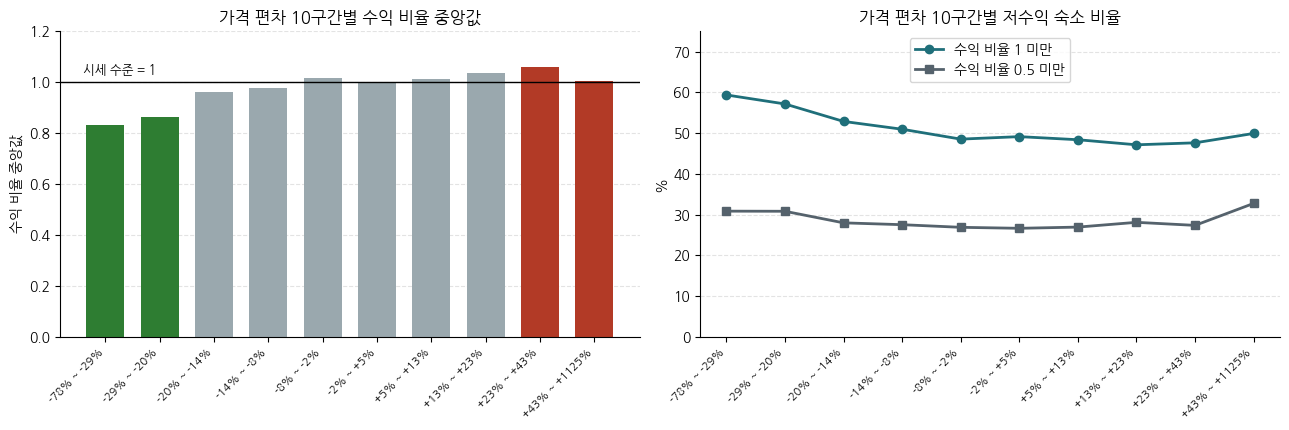

막대 색: 구간 가운데 편차가 −20% 이하면 저가 색, +20% 이상이면 고가 색, 그 사이는 시세 수준 색


In [ ]:
# [3-1] 가격 편차 10구간별 수익 비율

comp["decile"] = pd.qcut(comp["gap"], 10, labels=False) + 1
dec = comp.groupby("decile").agg(
    편차_최소=("gap", "min"), 편차_최대=("gap", "max"), 숙소수=("id", "size"),
    수익비율_중앙값=("rev_ratio", "median"),
    수익비율_1미만_pct=("rev_ratio", lambda s: (s < 1).mean() * 100),
    수익비율_05미만_pct=("rev_ratio", lambda s: (s < LOW_CUT).mean() * 100))
dec["편차 범위"] = [f"{a * 100:+.0f}% ~ {b * 100:+.0f}%" for a, b in zip(dec["편차_최소"], dec["편차_최대"])]
dec["예약일_배수_중앙값"] = comp.assign(  # 예약일 ÷ 같은 묶음 시세 수준 예약일 중앙값
    rel_occ=comp["estimated_occupancy_l365d"] / comp["fair_med_occ"].replace(0, np.nan)) \
                             .groupby("decile")["rel_occ"].median()
show = dec[["편차 범위", "숙소수", "수익비율_중앙값", "수익비율_1미만_pct", "수익비율_05미만_pct", "예약일_배수_중앙값"]].round(3)
show.columns = ["가격 편차 범위", "숙소 수", "수익 비율 중앙값", "1 미만 %", f"{LOW_CUT} 미만 %", "예약일 배수 중앙값"]
display(show)

# 그래프: 구간별 수익 비율 중앙값 (1 = 같은 묶음 시세 수준 숙소의 수익 중앙값)
x = np.arange(1, 11)
mid = (dec["편차_최소"] + dec["편차_최대"]) / 2
bar_colors = [COLORS["상대적 저가"] if m <= -THRESHOLD else COLORS["상대적 고가"] if m >= THRESHOLD else COLORS["시세 수준"] for m in mid]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
ax.bar(x, dec["수익비율_중앙값"], color=bar_colors, width=0.7)
ax.axhline(1, color="black", linewidth=1)
ax.text(0.6, 1.02, "시세 수준 = 1", va="bottom", ha="left", fontsize=9)
ax.set_ylim(0, 1.2)
ax.set_xticks(x); ax.set_xticklabels(show["가격 편차 범위"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("수익 비율 중앙값"); ax.set_title("가격 편차 10구간별 수익 비율 중앙값")
ax.grid(axis="y", linestyle="--", alpha=0.35); ax.set_axisbelow(True)
ax = axes[1]
ax.plot(x, dec["수익비율_1미만_pct"], marker="o", color="#1F6F7A", linewidth=2, label="수익 비율 1 미만")
ax.plot(x, dec["수익비율_05미만_pct"], marker="s", color="#55626C", linewidth=2, label=f"수익 비율 {LOW_CUT} 미만")
ax.set_xticks(x); ax.set_xticklabels(show["가격 편차 범위"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("%"); ax.set_title("가격 편차 10구간별 저수익 숙소 비율"); ax.set_ylim(0, 75)
ax.legend(loc="upper center"); ax.grid(axis="y", linestyle="--", alpha=0.35)
for a in axes:
    for s in ["top", "right"]:
        a.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
print("막대 색: 구간 가운데 편차가 −20% 이하면 저가 색, +20% 이상이면 고가 색, 그 사이는 시세 수준 색")

In [ ]:
# [3-2] 스피어만 순위 상관: |가격 편차|와 수익 비율 (전체 · 비싼 쪽 · 싼 쪽, 유형별)

def spear(d, label):
    rho, p = stats.spearmanr(d["gap"].abs(), d["rev_ratio"])
    return {"범위": label, "숙소 수": len(d), "ρ (|편차|, 수익 비율)": rho, "p-value": p}

rows = [spear(comp, "전체"), spear(comp[comp["gap"] >= 0], "비싼 쪽 (편차 ≥ 0)"), spear(comp[comp["gap"] < 0], "싼 쪽 (편차 < 0)")]
for rt, lab in TYPE_KR.items():
    part = comp[comp["room_type"] == rt]
    rows += [spear(part[part["gap"] >= 0], f"{lab} · 비싼 쪽"), spear(part[part["gap"] < 0], f"{lab} · 싼 쪽")]
sp = pd.DataFrame(rows).set_index("범위")
n_tests = len(sp)
sp["p (본페로니)"] = (sp["p-value"] * n_tests).clip(upper=1)
sp["판정"] = [judge(pa, r) + (" · 가설 방향(음수)" if r < 0 else " · 가설과 반대(양수)") for pa, r in zip(sp["p (본페로니)"], sp["ρ (|편차|, 수익 비율)"])]
sp["ρ (|편차|, 수익 비율)"] = sp["ρ (|편차|, 수익 비율)"].round(3)
sp["p-value"] = sp["p-value"].map(lambda v: f"{v:.1e}")
sp["p (본페로니)"] = sp["p (본페로니)"].map(lambda v: f"{v:.1e}")
display(sp)
print(f"본페로니 보정: 상관을 {n_tests}번 계산했으므로 p × {n_tests}")

,숙소 수,"ρ (|편차|, 수익 비율)",p-value,p (본페로니),판정
범위,,,,,
전체,23675,-0.021,1.2e-03,8.5e-03,차이는 있지만 아주 작음 · 가설 방향(음수)
비싼 쪽 (편차 ≥ 0),11209,0.021,2.3e-02,1.6e-01,차이 없음 · 가설과 반대(양수)
싼 쪽 (편차 < 0),12466,-0.085,2.3e-21,1.6e-20,차이는 있지만 아주 작음 · 가설 방향(음수)
집 전체 · 비싼 쪽,7549,0.060,1.6e-07,1.1e-06,차이는 있지만 아주 작음 · 가설과 반대(양수)
집 전체 · 싼 쪽,8114,-0.101,8.8e-20,6.2e-19,의미 있는 차이 · 가설 방향(음수)
개인실 · 비싼 쪽,3660,-0.055,8.4e-04,5.9e-03,차이는 있지만 아주 작음 · 가설 방향(음수)
개인실 · 싼 쪽,4352,-0.057,1.8e-04,1.3e-03,차이는 있지만 아주 작음 · 가설 방향(음수)


본페로니 보정: 상관을 7번 계산했으므로 p × 7


### 3단계 결과와 해석

#### 3-1. 가격 편차 10구간
**결과**

| 구간 | 가격 편차 | 수익 비율 중앙값 | 1 미만 % | 0.5 미만 % | 예약일 배수 |
| --- | --- | --- | --- | --- | --- |
| 1 | −78% ~ −29% | **0.833** | **59.4** | 30.8 | 1.20 |
| 2 | −29% ~ −20% | 0.863 | 57.2 | 30.8 | 1.09 |
| 3 | −20% ~ −14% | 0.963 | 52.9 | 28.0 | 1.07 |
| 4 | −14% ~ −8% | 0.978 | 51.0 | 27.5 | 1.05 |
| 5 | −8% ~ −2% | 1.017 | 48.5 | 26.9 | 1.03 |
| 6 | −2% ~ +5% | 1.000 | 49.1 | 26.6 | 1.00 |
| 7 | +5% ~ +13% | 1.013 | 48.4 | 26.9 | 0.95 |
| 8 | +13% ~ +23% | 1.038 | 47.1 | 28.1 | 0.87 |
| 9 | +23% ~ +43% | 1.059 | 47.6 | 27.3 | 0.77 |
| 10 | +43% 이상 | 1.003 | 49.9 | **32.7** | **0.57** |

**해석**
- **싼 쪽(구간 1~4)**: 시세보다 싸게 받을수록 수익 비율이 계단처럼 내려간다(0.98 → 0.83). 예약일은 1.05배 → 1.20배로 늘지만 가격을 깎은 만큼 메우지 못한다. 가설 1-2의 모습이 연속으로도 나타난다.
- **비싼 쪽(구간 7~10)**: 수익 비율은 1.01 ~ 1.06으로 오히려 조금 높다. 예약일은 0.95배 → 0.57배로 크게 줄지만 1박 가격이 그만큼 높아 상쇄된다. 다만 **가장 비싼 구간(+43% 이상)에서 '절반도 못 버는' 숙소가 32.7%로 모든 구간 중 가장 많다**. 집단 중앙값은 괜찮지만, 아주 비싸게 받는 숙소 중 일부는 예약이 거의 없다.
- 그래프의 모양은 '시세에서 멀어질수록 낮아지는 ∧ 모양'이 아니라, **싼 쪽만 내려가는 한쪽 기울기**다.

#### 3-2. 스피어만 상관 (|가격 편차|와 수익 비율)
**결과**

| 범위 | 숙소 수 | ρ | p (본페로니, ×7) | 판정 |
| --- | --- | --- | --- | --- |
| 전체 | 23,675 | −0.021 | 8.5e-03 | 아주 작음 · 가설 방향 |
| 비싼 쪽 (편차 ≥ 0) | 11,209 | +0.021 | 0.16 | **차이 없음** |
| 싼 쪽 (편차 < 0) | 12,466 | **−0.085** | 1.6e-20 | 아주 작음 · 가설 방향 |
| 집 전체 · 비싼 쪽 | 7,549 | +0.060 | 1.1e-06 | 아주 작음 · 가설과 반대 |
| 집 전체 · 싼 쪽 | 8,114 | **−0.101** | 6.2e-19 | **의미 있는 차이 · 가설 방향** |
| 개인실 · 비싼 쪽 | 3,660 | −0.055 | 5.9e-03 | 아주 작음 · 가설 방향 |
| 개인실 · 싼 쪽 | 4,352 | −0.057 | 1.3e-03 | 아주 작음 · 가설 방향 |

**해석**
- 전체로 보면 '시세에서 멀어질수록 수익이 낮다'는 관계는 **거의 없다**(ρ = −0.021).
- 방향을 나누면 그림이 분명해진다. **싸게 받을수록 수익 비율이 낮아지고**(ρ = −0.085), 집 전체에서는 '작음' 기준을 넘는다(ρ = −0.101). **비싸게 받는 정도는 수익과 관계가 없다**(ρ = +0.021, 차이 없음).
- 개인실은 비싼 쪽도 약하게 음수(−0.055)다. 2단계의 '개인실은 비싸게 받으면 위험하다'와 같은 방향이다.

**다음 질문**: 기준선을 ±10%, ±30%로 바꿔도 이 결론이 같을까? → 4단계

---
## 4단계. 민감도: 기준선을 ±10%, ±30%로 바꿔도 같은가
**왜 하는가**: ±20%는 v11 모델이 '숙소들이 시세에서 보통 17% 떨어져 있다'를 근거로 정한 선이다. 선을 바꾸면 집단이 바뀌고, 시세 수준 숙소가 바뀌니 **수익 비율의 기준(중앙값)도 바뀐다**. 그래도 2·3단계 결론이 같아야 믿을 수 있다.

**방법**
- 기준선 ±10%, ±20%, ±30%마다 집단을 다시 나누고, 같은 조건 묶음과 수익 비율을 **처음부터 다시 계산**한다(0-4의 `make_comp`).
- 2단계: 수익 비율 1 미만과 0.5 미만의 집단별 비율, 카이제곱 판정(본페로니, Cramér's V).
- 3단계: |가격 편차|와 수익 비율의 스피어만 상관(비싼 쪽 · 싼 쪽).

In [ ]:
# [4-1] 기준선 ±10 / 20 / 30%에서 2·3단계 다시 계산

rows = []
for t in [0.10, 0.20, 0.30]:
    d = make_comp(classify(data["gap"].values, t))
    row = {"기준선": f"±{int(t * 100)}%", "비교 숙소": len(d),
           "고가 수": int((d["group"] == "상대적 고가").sum()), "저가 수": int((d["group"] == "상대적 저가").sum())}
    for cut in [1.0, LOW_CUT]:
        rh, rl = chi_test(d, cut, "상대적 고가"), chi_test(d, cut, "상대적 저가")
        row[f"<{cut} 저수익 % (고가/수준/저가)"] = f"{rh['저수익 % (비교 집단)']:.1f} / {rh['저수익 % (시세 수준)']:.1f} / {rl['저수익 % (비교 집단)']:.1f}"
        vh, vl = rh["Cramér's V"], rl["Cramér's V"]
        row[f"<{cut} 고가 V · 판정"] = f"{vh:.3f} · {rh['판정']}"
        row[f"<{cut} 저가 V · 판정"] = f"{vl:.3f} · {rl['판정']}"
    for side, m in [("비싼 쪽", d["gap"] >= 0), ("싼 쪽", d["gap"] < 0)]:
        rho, p = stats.spearmanr(d.loc[m, "gap"].abs(), d.loc[m, "rev_ratio"])
        row[f"ρ {side}"] = round(rho, 3)
    rows.append(row)
sens = pd.DataFrame(rows).set_index("기준선")
display(sens.T)

기준선,±10%,±20%,±30%
비교 숙소,22289,23675,24195
고가 수,7371,5350,3804
저가 수,7984,4828,2257
<1.0 저수익 % (고가/수준/저가),48.9 / 49.3 / 56.7,48.5 / 49.6 / 58.3,48.5 / 49.6 / 58.8
<1.0 고가 V · 판정,0.004 · 차이 없음,0.010 · 차이 없음,0.008 · 차이 없음
<1.0 저가 V · 판정,0.074 · 차이는 있지만 아주 작음,0.077 · 차이는 있지만 아주 작음,0.058 · 차이는 있지만 아주 작음
<0.5 저수익 % (고가/수준/저가),29.5 / 27.0 / 30.1,30.0 / 27.2 / 30.9,30.4 / 27.1 / 30.2
<0.5 고가 V · 판정,0.028 · 차이는 있지만 아주 작음,0.028 · 차이는 있지만 아주 작음,0.028 · 차이는 있지만 아주 작음
<0.5 저가 V · 판정,0.034 · 차이는 있지만 아주 작음,0.037 · 차이는 있지만 아주 작음,0.022 · 차이는 있지만 아주 작음
ρ 비싼 쪽,0.025,0.021,0.021


### 4단계 결과와 해석

**결과**

| 항목 | ±10% | **±20% (기본)** | ±30% |
| --- | --- | --- | --- |
| 비교 숙소 / 고가 / 저가 | 22,289 / 7,371 / 7,984 | 23,675 / 5,350 / 4,828 | 24,195 / 3,804 / 2,257 |
| 1 미만 % (고가 / 수준 / 저가) | 48.9 / 49.3 / 56.7 | 48.5 / 49.6 / 58.3 | 48.5 / 49.6 / 58.8 |
| 1 미만 고가 vs 수준 | V 0.004 · 차이 없음 | V 0.010 · 차이 없음 | V 0.008 · 차이 없음 |
| 1 미만 저가 vs 수준 | V 0.074 · 아주 작음 | V 0.077 · 아주 작음 | V 0.058 · 아주 작음 |
| 0.5 미만 % (고가 / 수준 / 저가) | 29.5 / 27.0 / 30.1 | 30.0 / 27.2 / 30.9 | 30.4 / 27.1 / 30.2 |
| 0.5 미만 고가 / 저가 vs 수준 | V 0.028 / 0.034 · 아주 작음 | V 0.028 / 0.037 · 아주 작음 | V 0.028 / 0.022 · 아주 작음 |
| ρ 비싼 쪽 / 싼 쪽 | +0.025 / −0.072 | +0.021 / −0.085 | +0.021 / −0.086 |

**해석**: 기준선을 바꿔도 **2·3단계 결론이 그대로**다.
1. **고가**: 수익 비율 1 미만 비율은 언제나 시세 수준과 같다(차이 없음). 절반 미만은 언제나 2~3%p 많지만 아주 작다(V 0.028).
2. **저가**: 수익 비율 1 미만이 언제나 시세 수준보다 7~9%p 많다. 크기는 V 0.06 ~ 0.08로 늘 '작음' 기준 아래다.
3. **연속 관계**: 비싼 쪽은 늘 관계없음(ρ ≈ +0.02), 싼 쪽은 늘 약한 음수(ρ −0.07 ~ −0.09)다.
- 즉 ±20%라는 선택이 결론을 만든 것이 아니다. v11 모델 Step 10의 점검(가설 1-1·1-2의 수익 비율)과도 같은 방향이다.

**다음 질문**: 그렇다면 누구에게 먼저 연락할까? → 5단계

---
## 5단계. 연락 명단 `contact_list.csv`
**왜 하는가**: 검증 결과를 행동으로 옮기려면 '누구에게, 어떤 순서로' 연락할지 정해야 한다. v11 모델의 제언에 따라 두 가지 후보를 뽑는다.

| 후보 | 조건 | 이유 |
| --- | --- | --- |
| **① 고가 가격 인하 후보** | 상대적 고가 + 수익 비율 **0.5 미만** (1단계) | 시세보다 20% 이상 비싸게 받으면서 같은 조건 시세 수준 숙소 수익의 절반도 못 번다. 가격이 지금 바로 조정해 볼 수 있는 수단이다 |
| **② 저가 가격 인상 후보** | 상대적 저가 + 수익 비율 **1 미만** + 예약일이 같은 묶음 시세 수준 숙소의 **중앙값 이상** + 평점 **4.8 이상** (1단계) | 예약은 시세 수준만큼 이상 받는데(수요 있음) 싸게 받아서 덜 번다. 평가도 좋아 가격을 올려도 될 여지가 있다. 가설 1-2의 '많은 예약일에도 수익이 낮은' 숙소다 |

- v11 모델 제언 ③에 따라, 저가 중 **예약일이 적은** 숙소(달력·품질 문제)는 인상 후보에서 뺀다. 예약일 조건이 이 역할을 한다.

**우선순위**
- ① 인하 후보: **예약 0일 숙소를 먼저**, 그다음 **덜 번 금액이 큰 순서**. 예약이 아예 없는 숙소가 가장 급하고, 금액이 클수록 효과가 크다.
- ② 인상 후보: **예약일 255일 상한 숙소를 먼저**(실제 수요가 255일보다 많을 수 있어 올려도 예약이 덜 줄 가능성이 큼), 그다음 **덜 번 금액이 큰 순서**.

**열**: 숙소 ID, 호스트 ID(원본에서 가져옴), 대상 구분, 숙소 유형, 실제 가격, 추정 시세(기준 가격), 가격 편차, 수익 비율, 덜 번 금액(수익 차이), 1년 추정 예약일, 평점, 우선순위

In [ ]:
# [5-1] 후보 선정과 우선순위

RATING_CUT = 4.8                     # 1단계에서 정한 평점 기준

cut_dn = comp[(comp["group"] == "상대적 고가") & (comp["rev_ratio"] < LOW_CUT)].copy()
cut_dn["대상 구분"] = "① 고가 가격 인하 후보"
cut_dn = cut_dn.sort_values(["zero", "shortfall"], ascending=[False, False])

cut_up = comp[(comp["group"] == "상대적 저가") & (comp["rev_ratio"] < 1)
              & (comp["estimated_occupancy_l365d"] >= comp["fair_med_occ"])
              & (comp["review_scores_rating"] >= RATING_CUT)].copy()
cut_up["대상 구분"] = "② 저가 가격 인상 후보"
cut_up["capped"] = cut_up["estimated_occupancy_l365d"] >= 255
cut_up = cut_up.sort_values(["capped", "shortfall"], ascending=[False, False])

for part in [cut_dn, cut_up]:
    part["우선순위"] = np.arange(1, len(part) + 1)

# 후보 선정 과정 (조건을 하나씩 더할 때 남는 숙소 수)
low_c = comp[comp["group"] == "상대적 저가"]
steps = pd.DataFrame([
    ("① 인하", "비교 묶음 안 상대적 고가", int((comp["group"] == "상대적 고가").sum())),
    ("① 인하", f"+ 수익 비율 {LOW_CUT} 미만", len(cut_dn)),
    ("② 인상", "비교 묶음 안 상대적 저가", len(low_c)),
    ("② 인상", "+ 수익 비율 1 미만", int((low_c["rev_ratio"] < 1).sum())),
    ("② 인상", "+ 예약일 ≥ 같은 묶음 시세 수준 중앙값", int(((low_c["rev_ratio"] < 1) & (low_c["estimated_occupancy_l365d"] >= low_c["fair_med_occ"])).sum())),
    ("② 인상", f"+ 평점 {RATING_CUT} 이상", len(cut_up)),
], columns=["후보", "조건", "남는 숙소 수"])
display(steps.set_index(["후보", "조건"]))

def profile(d):
    return {"숙소 수": len(d), "집 전체 %": (d["room_type"] == "Entire home/apt").mean() * 100,
            "가격 편차 중앙값 %": d["gap"].median() * 100, "수익 비율 중앙값": d["rev_ratio"].median(),
            "예약일 중앙값": d["estimated_occupancy_l365d"].median(), "예약 0일 (곳)": int(d["zero"].sum()),
            "255일 상한 (곳)": int((d["estimated_occupancy_l365d"] >= 255).sum()), "평점 중앙값": d["review_scores_rating"].median(),
            "덜 번 금액 합계 (만 파운드)": d["shortfall"].sum() / 1e4}
display(pd.DataFrame({"① 고가 가격 인하 후보": profile(cut_dn), "② 저가 가격 인상 후보": profile(cut_up)}).round(2))

남는 숙소 수
후보   조건                              
① 인하 비교 묶음 안 상대적 고가              5350
     + 수익 비율 0.5 미만              1604
② 인상 비교 묶음 안 상대적 저가              4828
     + 수익 비율 1 미만                2815
     + 예약일 ≥ 같은 묶음 시세 수준 중앙값      812
     + 평점 4.8 이상                  232

,① 고가 가격 인하 후보,② 저가 가격 인상 후보
숙소 수,1604.00,232.00
집 전체 %,60.35,58.19
가격 편차 중앙값 %,41.65,-30.12
수익 비율 중앙값,0.14,0.84
예약일 중앙값,9.00,147.00
예약 0일 (곳),640.00,0.00
255일 상한 (곳),0.00,48.00
평점 중앙값,4.81,4.89
덜 번 금액 합계 (만 파운드),2780.08,91.84


In [ ]:
# [5-2] 호스트 ID 붙이기, contact_list.csv 저장, 상위 5개 예시

raw_host = pd.read_csv(RAW_PATH, usecols=["id", "host_id"])
contact = pd.concat([cut_dn, cut_up]).merge(raw_host, on="id", how="left", validate="one_to_one")
assert contact["host_id"].notna().all(), "호스트 ID가 없는 숙소가 있습니다."

contact = contact.assign(room_type=contact["room_type"].map(TYPE_KR))[[
    "id", "host_id", "대상 구분", "room_type", "price_gbp", "pred_price", "gap", "rev_ratio", "shortfall",
    "estimated_occupancy_l365d", "review_scores_rating", "우선순위"]]
contact.columns = ["숙소 ID", "호스트 ID", "대상 구분", "숙소 유형", "실제 가격 (파운드)", "추정 시세 (파운드)", "가격 편차",
                   "수익 비율", "덜 번 금액 (파운드)", "1년 추정 예약일", "평점", "우선순위"]
for c in ["추정 시세 (파운드)", "덜 번 금액 (파운드)"]:
    contact[c] = contact[c].round(0)
for c in ["가격 편차", "수익 비율"]:
    contact[c] = contact[c].round(3)

OUT_CSV = OUT_DIR / "contact_list.csv"
contact.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")       # utf-8-sig: 엑셀에서 열어도 한글이 안 깨짐
print(f"저장: {OUT_CSV.name} | {len(contact):,}행 (인하 후보 {len(cut_dn):,} + 인상 후보 {len(cut_up):,}) | "
      f"호스트 {contact['호스트 ID'].nunique():,}명")

for k in ["① 고가 가격 인하 후보", "② 저가 가격 인상 후보"]:
    print(f"\n{k} 상위 5개")
    display(contact[contact["대상 구분"] == k].head(5).set_index("우선순위"))

저장: contact_list.csv | 1,836행 (인하 후보 1,604 + 인상 후보 232) | 호스트 1,564명

① 고가 가격 인하 후보 상위 5개


,숙소 ID,호스트 ID,대상 구분,숙소 유형,실제 가격 (파운드),추정 시세 (파운드),가격 편차,수익 비율,덜 번 금액 (파운드),1년 추정 예약일,평점
우선순위,,,,,,,,,,,
1,690309482224958532,150571218,① 고가 가격 인하 후보,집 전체,520.33,399.0,0.305,0.0,62388.0,0,4.53
2,1281652443994187469,516277686,① 고가 가격 인하 후보,집 전체,739.00,607.0,0.218,0.0,62388.0,0,4.93
3,28838351,5541741,① 고가 가격 인하 후보,집 전체,422.00,247.0,0.705,0.0,60318.0,0,4.65
4,35743849,268875272,① 고가 가격 인하 후보,집 전체,530.00,278.0,0.908,0.0,60318.0,0,4.84
5,43593029,2822938,① 고가 가격 인하 후보,집 전체,660.00,449.0,0.471,0.0,60318.0,0,4.77



② 저가 가격 인상 후보 상위 5개


,숙소 ID,호스트 ID,대상 구분,숙소 유형,실제 가격 (파운드),추정 시세 (파운드),가격 편차,수익 비율,덜 번 금액 (파운드),1년 추정 예약일,평점
우선순위,,,,,,,,,,,
1,952670652567707603,107557456,② 저가 가격 인상 후보,집 전체,158.0,236.0,-0.329,0.701,17210.0,255,4.84
2,843553476379978703,280657820,② 저가 가격 인상 후보,집 전체,185.0,255.0,-0.275,0.820,10325.0,255,4.81
3,51592613,417746816,② 저가 가격 인상 후보,집 전체,110.0,144.0,-0.235,0.746,9549.0,255,4.83
4,1415804537216070663,661844715,② 저가 가격 인상 후보,집 전체,114.6,218.0,-0.475,0.777,8376.0,255,4.83
5,1179755298617406436,533154788,② 저가 가격 인상 후보,집 전체,143.0,258.0,-0.447,0.826,7695.0,255,4.82


### 5단계 결과와 해석

#### 5-1. 후보 선정
**결과**

| 후보 | 조건을 하나씩 더할 때 남는 숙소 |
| --- | --- |
| ① 고가 가격 인하 | 비교 묶음 안 상대적 고가 5,350 → 수익 비율 0.5 미만 **1,604곳** |
| ② 저가 가격 인상 | 비교 묶음 안 상대적 저가 4,828 → 수익 비율 1 미만 2,815 → 예약일 ≥ 시세 수준 중앙값 812 → 평점 4.8 이상 **232곳** |

| 특징 | ① 고가 가격 인하 후보 | ② 저가 가격 인상 후보 |
| --- | --- | --- |
| 숙소 수 (집 전체 / 개인실) | 1,604 (968 / 636) | 232 (135 / 97) |
| 가격 편차 중앙값 | +41.7% | −30.1% |
| 수익 비율 중앙값 | 0.14 | 0.84 |
| 1년 추정 예약일 중앙값 | 9일 | 147일 |
| 예약 0일 / 255일 상한 | 640곳 / 0곳 | 0곳 / 48곳 |
| 평점 중앙값 | 4.81 | 4.89 |
| 덜 번 금액 합계 | 2,780만 파운드 | 92만 파운드 |

**해석**
- **① 인하 후보 1,604곳**은 시세보다 42% 비싸게 받고 1년에 9일만 예약된다. 640곳(40%)은 예약이 0일이다. 평점은 4.81로 나쁘지 않다. 평가가 아니라 **가격과 예약 문제**로 보이는 숙소들이다.
- **② 인상 후보 232곳**은 시세보다 30% 싸게 받고, 예약은 같은 조건 시세 수준 숙소보다 많으며(147일), 평점도 4.89로 높다. 그런데도 수익은 시세 수준의 84%다. '많이 팔리는데 싸게 팔아서 덜 버는' 숙소라 가격을 올려 볼 근거가 가장 분명하다.
- 인상 후보가 적은 이유: 저가·수익 낮음 2,815곳 중 **예약일이 시세 수준 이상인 숙소는 812곳(29%)뿐**이다. 나머지는 싸게 받는데도 예약이 적다. 이 숙소들은 가격보다 달력·품질 문제라서 인상 후보에서 뺐다(v11 모델 제언 ③과 같은 판단).
- 금액은 ①이 훨씬 크다(2,780만 vs 92만 파운드). 연락의 중심은 ①이고, ②는 '가격을 올려도 된다'는 근거를 보여 줄 작은 시범 대상이다.

#### 5-2. 명단 파일
**결과**: `contact_list.csv`를 저장했다. 1,836행(인하 1,604 + 인상 232), 호스트 1,564명. 한 호스트가 인하 후보 숙소를 최대 10곳 가진 경우도 있어, **호스트 단위로 묶어 연락하면 연락 횟수를 줄일 수 있다**.

| 열 | 뜻 |
| --- | --- |
| 숙소 ID, 호스트 ID | 숙소와 호스트 식별자 (호스트 ID는 원본 `listings`에서 가져옴) |
| 대상 구분 | ① 고가 가격 인하 후보 / ② 저가 가격 인상 후보 |
| 실제 가격, 추정 시세 | 지금 1박 가격과 같은 조건 숙소의 추정 시세 (파운드) |
| 가격 편차 | (실제 가격 − 추정 시세) ÷ 추정 시세 |
| 수익 비율, 덜 번 금액 | 같은 묶음 시세 수준 숙소 수익 중앙값 대비 비율과 차이 |
| 1년 추정 예약일, 평점 | 우선순위 판단에 쓴 값 |
| 우선순위 | ① 예약 0일 먼저 → 덜 번 금액 큰 순 / ② 255일 상한 먼저 → 덜 번 금액 큰 순 (후보마다 1부터) |

**상위 5개 예시**: ① 인하 후보 1~5위는 모두 **집 전체, 예약 0일**이고 시세보다 22~91% 비싸며 숙소당 6만 파운드 넘게 덜 번다. ② 인상 후보 1~5위는 모두 **집 전체, 예약 255일 상한, 평점 4.8 이상**이고 시세보다 24~48% 싸게 받는다.

**한계**
- 우선순위는 관측 데이터로 정했다. 가격을 바꾸면 실제로 수익이 오르는지는 A/B 테스트로 확인해야 한다(v11 모델 제언 ⑤).
- 연락 전 숙소 페이지를 사람이 확인하는 단계가 필요하다(v11 모델 제언 ⑥). 특히 개인실 3명 이상, 고급 숙소는 추정 시세 오차가 크다.

---
## 6단계. 검증 결과 요약

### 1. 재현
v11 모델 결과(추정 시세 합계 5,018,069.00파운드, 고가 5,897곳, 비교 23,675곳, 핵심 질문 대상 5,409곳)와 Step 7 핵심 숫자(수익 비율 1.041 / 0.848, r +0.038 / −0.097)를 **독립적으로 다시 계산해 모두 일치**함을 확인했다.

### 2. 정한 기준
| 기준 | 값 | 근거 |
| --- | --- | --- |
| 저수익 | 수익 비율 **0.5 미만** | 고가·저수익 1,604곳으로 고가가 덜 번 금액의 83%. 0.4(75%)와 0.6(+184곳에 +5.6%p) 사이의 균형점 |
| 평점 | **4.8 이상** | 분석 대상 평점의 중앙값 = 상위 절반 |

### 3. 결과 한 문장
| 검증 | 결과 | 한 문장 |
| --- | --- | --- |
| 저수익 비율 차이 (1 미만) | 고가 48.5% vs 수준 49.6% (V 0.010, 차이 없음) / 저가 58.3% vs 49.6% (V 0.077, p < 0.001) | 수익이 시세 수준보다 낮은 숙소는 **싸게 받는 쪽에 8.7%p 더 많고**, 비싸게 받는 쪽은 시세 수준과 같다. 차이의 크기는 작다 |
| 저수익 비율 차이 (0.5 미만) | 고가 +2.8%p, 저가 +3.8%p (V 0.03 ~ 0.04) | '절반도 못 버는' 숙소는 모든 가격 집단에 약 30%씩 있어, 가격 집단만으로 가려낼 수 없다 |
| 연속 관계 (스피어만) | 비싼 쪽 ρ +0.021 (관계 없음), 싼 쪽 −0.085, 집 전체 싼 쪽 −0.101 | 시세보다 **싸게 받을수록 수익이 낮아지고**, 비싸게 받는 정도는 수익과 관계가 없다 |
| 유형별 | 개인실 고가 0.5 미만 +8.5%p, 집 전체 저가 1 미만 +9.5%p | 개인실은 비싸게, 집 전체는 싸게 받는 쪽이 위험하다 |
| 민감도 (±10 · 30%) | 모든 판정 같음 | 결론은 기준선 선택에 좌우되지 않는다 |
| 연락 명단 | 인하 1,604곳(덜 번 2,780만 파운드, 예약 0일 640곳) + 인상 232곳(92만 파운드), 호스트 1,564명 | 연락의 중심은 고가·저수익 숙소이고, 저가 인상은 작은 시범 대상이다 |

### 4. 가설과의 관계
- **가설 1-1 (고가)**: v11 모델 기각과 같다. 저수익 비율도, 연속 관계도 시세 수준과 차이가 없다.
- **가설 1-2 (저가)**: v11 모델 부분 채택과 같다. 방향은 모든 검정·기준선에서 같지만 크기는 '작음' 기준 근처다(집 전체만 기준을 넘음).